# NeuroVascNet: full analysis (infra-slow protocol)

**Run All shows every current result from the saved files in `analysis_p2_p4/results/`. Nothing is recomputed.**

**To rerun everything:** in section 2 (Settings), change `RUN = set()` to `RUN = ALL`, then Run All.

**To rerun one analysis:** go to the `HOW TO RERUN` block in section 2. Every analysis has a `# RERUN` line under its code with its name.

Open this notebook from the `merge/` folder. Rerunning needs the datasets in `dataset/` and the caches in `merge/neurovascnet_merge_v1_cache/`, neither of which is in git.

## 1. Environment

Checks the Python packages (installs any that are missing), then sets the random seed and the device.

In [1]:
import sys, subprocess

def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

for _mod, _pkg in [("numpy", "numpy"), ("scipy", "scipy"), ("pandas", "pandas"),
                   ("torch", "torch"), ("sklearn", "scikit-learn"),
                   ("nibabel", "nibabel"), ("nilearn", "nilearn"), ("mne", "mne")]:
    try:
        __import__(_mod)
    except ImportError:
        print(f"installing {_pkg} ...")
        _pip(_pkg)

import os, re, json, math, time, random, copy, warnings
from dataclasses import dataclass, asdict, replace
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy.io as sio
from scipy import signal as sps
from scipy import stats
import torch
import torch.nn as nn

if not hasattr(np, "trapezoid"):
    np.trapezoid = np.trapz

SEED = 1337

def set_determinism(seed=SEED):
    """Put every random source into a known state.

    Called once at import and again before each training run, so a rerun on a
    different machine follows the same sequence. Seeding numpy and torch alone
    is not enough: Python's own `random` drives some library code, cuDNN picks
    convolution algorithms by timing unless told not to, and cuBLAS needs a
    workspace setting before the first CUDA call for reproducible reductions.
    """
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seeded_loader(ds, batch_size, seed=SEED, shuffle=True):
    """DataLoader whose shuffle order depends only on `seed`.

    Without an explicit generator the shuffle draws from the global torch RNG,
    so the batch order silently depends on how many random numbers were drawn
    earlier in the notebook -- run cells in a different order and the training
    data arrives in a different sequence.
    """
    g = torch.Generator()
    g.manual_seed(int(seed))
    return torch.utils.data.DataLoader(
        ds, batch_size=batch_size, shuffle=shuffle, drop_last=False,
        generator=g if shuffle else None, num_workers=0)

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

FIGDIR = Path("neurovascnet_merge_v1_outputs") / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "legend.frameon": False,
})
INK, ACC, HBO, OK_, NO_ = "#11151a", "#1d4c6b", "#a3312a", "#1f6549", "#98382f"

def save_fig(fig, name, caption=""):
    """Write a figure next to the CSVs and say where it went."""
    f = FIGDIR / f"{name}.png"
    fig.savefig(f)
    plt.close(fig)
    print(f"   figure -> {f}" + (f"\n   {caption}" if caption else ""))

set_determinism()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

warnings.resetwarnings()
for _cat in (DeprecationWarning, FutureWarning, UserWarning):
    warnings.filterwarnings("ignore", category=_cat)
warnings.filterwarnings("once", category=RuntimeWarning)
from sklearn.linear_model import Ridge, LogisticRegression

## 2. Settings: `RUN = ALL` is set here

**This is the only cell you need to edit.** Leave `RUN = set()` to view the saved results. Change it to `RUN = ALL` to recompute everything.

In [2]:
from pathlib import Path

# ======================= HOW TO RERUN =======================
# RUN = set()              show the saved results, recompute nothing (default)
# RUN = {"calibration"}    rerun one analysis (names: see the "# RERUN" lines below each analysis)
# RUN = {"calibration", "nvc_kernel"}    rerun several
# RUN = ALL                rerun everything, one after another (rough estimate: a day or more)
#
# New results are written to merge/_nb_run/ and shown in the tables below.
# The saved results in analysis_p2_p4/results/ are never changed.
#
# PROJECT_ROOT must be the folder that holds dataset/ and merge/.
# Keep BUILD_CACHES = False: True overwrites the 60 GB cache in merge/neurovascnet_merge_v1_cache/, which is not in git.
ALL = {"all"}
RUN = set()
BUILD_CACHES = False
PROJECT_ROOT = Path.cwd().parent
NB_OUT = Path("_nb_run")
NB_OUT.mkdir(exist_ok=True)

Settings from the merge notebook: dataset paths and pipeline options. `EEG_FILTER = False` keeps the infra-slow band.

In [3]:
PATH_FNIRS_HEFMI            = f"{PROJECT_ROOT}/dataset/HEFMI-ICH EEG+FNRI"

PATH_FNIRS_HBCI             = f"{PROJECT_ROOT}/dataset/TU Berlin hBCI EEG+FNRI"

FNIRS_TRAIN = "hBCI"

HBCI_POOL_MI_MA = True

FMRI_TRAIN = "ds002336"

FMRI_ROIS = "motor"

MAX_FMRI_TRIALS_PER_RUN = 100

PATH_TRAIN_FMRI_DS002336     = f"{PROJECT_ROOT}/dataset/OpenNeuro ds002336"

PATH_EXTERNAL_FMRI_DS002739  = f"{PROJECT_ROOT}/dataset/External fMRI validation OpenNeuro ds002739"

PATH_CLINICAL_HEFMI = PATH_FNIRS_HEFMI

QUICK_TEST = False

ENCODER = "trunk"
EEG_INPUT = "raw"
EEG_FILTER = False
DS2336_TASKS = ("motorloc", "MIpre", "MIpost", "eegNF", "fmriNF", "eegfmriNF")
BALANCED_SUBJECTS = False
RUN_SWEEPS = True
USE_CACHE = True
SEEDS = [1337, 20260726, 7, 42, 2718]
RUN_SEED_INDEX = "auto"

Builds the configuration object and the run identifiers from those settings.

In [4]:
@dataclass(frozen=True)
class Config:
    tmin_s: float = -2.0
    tmax_s: float = 28.0
    eeg_fs: float = 200.0
    hemo_fs: float = 10.0
    eeg_samples: int = 6000
    hemo_samples: int = 300
    fmri_vols: int = 15
    baseline_s: float = 2.0
    n_folds: int = 5
    n_perm: int = 1000
    epochs: int = 30
    batch_size: int = 64
    lr: float = 1e-3
    apply_gsr: bool = False
    w_main: float = 1.0
    w_hetero: float = 0.1
    w_smooth: float = 0.05
    w_fmri: float = 1.0
    n_null: int = 100
    abstain_coverage: float = 0.75
    personal_fracs: tuple = (0.10, 0.20, 0.40)
    response_start_s: float = 7.2
    response_dur_s: float = 10.0
    practical_r: float = 0.05
    reliability_inner_folds: int = 3

CFG = Config()
if QUICK_TEST:
    CFG = replace(CFG, epochs=2, n_perm=200, n_folds=3, n_null=20)

import hashlib
RUN_SPEC = {"encoder": ENCODER, "eeg_input": EEG_INPUT, "eeg_filter": EEG_FILTER,
            "ds2336_tasks": list(DS2336_TASKS), "balanced_subjects": BALANCED_SUBJECTS,
            "run_sweeps": RUN_SWEEPS, "quick_test": QUICK_TEST, "config": asdict(CFG),
            "fnirs_train": FNIRS_TRAIN, "fmri_train": FMRI_TRAIN, "fmri_rois": FMRI_ROIS,
            "hbci_pool_mi_ma": HBCI_POOL_MI_MA, "max_fmri_trials_per_run": MAX_FMRI_TRIALS_PER_RUN,
            "fold_seed": SEED, "seeds": SEEDS, "notebook": "merge_v1.2",
            "paths": [None if p is None else Path(p).name for p in
                      (PATH_FNIRS_HBCI, PATH_FNIRS_HEFMI, PATH_TRAIN_FMRI_DS002336,
                       PATH_EXTERNAL_FMRI_DS002739, PATH_CLINICAL_HEFMI)]}
RUN_FINGERPRINT = hashlib.sha256(json.dumps(RUN_SPEC, sort_keys=True, default=str).encode()).hexdigest()
RUN_TAG = f"{ENCODER}_{EEG_INPUT}_{RUN_FINGERPRINT[:10]}" + ("_quick" if QUICK_TEST else "")
OUT = Path("neurovascnet_merge_v1_outputs") / RUN_TAG
OUT.mkdir(parents=True, exist_ok=True)
FIGDIR = OUT / "figures"
FIGDIR.mkdir(exist_ok=True)

def seed_done(s):
    f = OUT / f"summary_seed{s}.json"
    if not f.is_file():
        return False
    try:
        with open(f, encoding="utf-8") as fh:
            doc = json.load(fh)
        prov = doc.get("provenance", {})
        return (prov.get("seed") == s and prov.get("run_fingerprint") == RUN_FINGERPRINT
                and doc.get("claim_guard", {}).get("passed") is True)
    except Exception:
        return False

SEEDS_DONE = [s for s in SEEDS if seed_done(s)]
if os.environ.get("NEUROVASCNET_RUN_SEED"):
    RUN_SEED = int(os.environ["NEUROVASCNET_RUN_SEED"])
elif RUN_SEED_INDEX == "auto":
    _todo = [s for s in SEEDS if s not in SEEDS_DONE]
    RUN_SEED = _todo[0] if _todo else SEEDS[0]
    if not _todo:
        print("all five seeds already have summaries -- re-running", RUN_SEED)
else:
    RUN_SEED = SEEDS[int(RUN_SEED_INDEX)]
assert RUN_SEED in SEEDS, f"{RUN_SEED} is not in the declared protocol {SEEDS}"
TRAIN_SEED = RUN_SEED
DO_SWEEPS = RUN_SWEEPS and RUN_SEED in SEEDS[:2]
SEED_OUT = OUT / f"seed{RUN_SEED}"
SEED_OUT.mkdir(exist_ok=True)

print(f"numpy {np.__version__} | torch {torch.__version__} | device {DEVICE}")
print(f"run tag {RUN_TAG} | seed {RUN_SEED} (done: {SEEDS_DONE or 'none'}) | sweeps {DO_SWEEPS}")
print("MODE:", "SMOKE TEST -- numbers are NOT reportable" if QUICK_TEST else "FULL RUN")
if ENCODER == "eegnet_tcn" and EEG_INPUT == "raw":
    print("WARNING: EEGNet+TCN on raw 6000-sample EEG is memory-heavy; the declared secondary is bandpower.")

numpy 1.26.4 | torch 2.7.1+cu118 | device cuda
run tag trunk_raw_0d875ccf39 | seed 20260726 (done: [1337]) | sweeps True
MODE: FULL RUN


Checks that each dataset folder exists. On a machine without the datasets it prints `[BAD]`; this does not matter when only viewing results.

In [5]:
_HEFMI = (PATH_FNIRS_HEFMI, "epo_data", "HEFMI",  "hefmi")
_HBCI  = (PATH_FNIRS_HBCI,  "EEG data", "hBCI",   "hbci")

if FNIRS_TRAIN == "HEFMI":
    _tr, _ex = _HEFMI, _HBCI
elif FNIRS_TRAIN == "hBCI":
    _tr, _ex = _HBCI, _HEFMI
else:
    raise ValueError(f'FNIRS_TRAIN must be "HEFMI" or "hBCI", got {FNIRS_TRAIN!r}')

_DS2336 = (PATH_TRAIN_FMRI_DS002336,    "derivatives", "ds002336", "ds002336")
_DS2739 = (PATH_EXTERNAL_FMRI_DS002739, "sub-01",      "ds002739", "ds002739")

if FMRI_TRAIN == "ds002336":
    _mtr, _mex = _DS2336, _DS2739
elif FMRI_TRAIN == "ds002739":
    _mtr, _mex = _DS2739, _DS2336
else:
    raise ValueError(f'FMRI_TRAIN must be "ds002336" or "ds002739", got {FMRI_TRAIN!r}')

ROLES = {
    "train_fnirs":    (_tr[0], _tr[1], f"TRAIN    fNIRS  {_tr[2]}"),
    "train_fmri":     (_mtr[0], _mtr[1], f"TRAIN    fMRI   {_mtr[2]}"),
    "external_fnirs": (_ex[0], _ex[1], f"EXTERNAL fNIRS  {_ex[2]}"),
    "external_fmri":  (_mex[0], _mex[1], f"EXTERNAL fMRI   {_mex[2]}"),
    "clinical":       (PATH_CLINICAL_HEFMI,         "epo_data",    "CLINICAL        ICH vs controls"),
}
FNIRS_LOADER = {"train_fnirs": _tr[3], "external_fnirs": _ex[3]}
FMRI_LOADER  = {"train_fmri": _mtr[3], "external_fmri": _mex[3]}
print(f"fNIRS configuration: {_tr[2]} trains, {_ex[2]} validates")
print(f"fMRI  configuration: {_mtr[2]} trains, {_mex[2]} validates")
print(f"fMRI  target       : {FMRI_ROIS} ({'sensorimotor subset' if FMRI_ROIS == 'motor' else 'all cortical regions'})\n")

for _a, _b, _m in (("train_fnirs", "external_fnirs", "fNIRS"),
                   ("train_fmri", "external_fmri", "fMRI")):
    _pa, _pb = ROLES[_a][0], ROLES[_b][0]
    if _pa and _pb and Path(_pa).resolve() == Path(_pb).resolve():
        raise ValueError(f"{_a} and {_b} are the same folder -- the {_m} external "
                         "validation would be testing on training data.")

PATHS = {}
for _key, (_raw, _marker, _label) in ROLES.items():
    if not _raw:
        print(f"  [off ] {_label}")
        PATHS[_key] = None
        continue
    _p = Path(_raw)
    if not _p.exists():
        print(f"  [BAD ] {_label}   path does not exist: {_p}")
        PATHS[_key] = None
    elif not (_p / _marker).exists():
        print(f"  [BAD ] {_label}   no '{_marker}/' inside: {_p}")
        PATHS[_key] = None
    else:
        print(f"  [ok  ] {_label}")
        PATHS[_key] = _p

if not (PATHS["train_fnirs"] or PATHS["train_fmri"]):
    _lines = []
    for _k, (_r, _m, _l) in ROLES.items():
        _lines.append(f"      {_l}\n         path   {_r}\n         needs  {_m}/")
    raise FileNotFoundError(
        "No TRAINING dataset resolved -- nothing to train on.\n\n"
        "  Edit the PATH_* lines in the settings cell. Each one is a full path\n"
        "  to that dataset's folder, and each must contain the folder named\n"
        "  below:\n\n" + "\n".join(_lines))

print(f"\noutputs -> {OUT.resolve()}")

print("\nenvironment")
print(f"  python  {sys.version.split()[0]}")
print(f"  numpy   {np.__version__}   scipy {__import__('scipy').__version__}")
print(f"  torch   {torch.__version__}   device {DEVICE}")
if DEVICE == "cuda":
    print(f"  gpu     {torch.cuda.get_device_name(0)}")
    print(f"  seed    {SEED}   cudnn.deterministic={torch.backends.cudnn.deterministic}"
      f"  benchmark={torch.backends.cudnn.benchmark}")

fNIRS configuration: hBCI trains, HEFMI validates
fMRI  configuration: ds002336 trains, ds002739 validates
fMRI  target       : motor (sensorimotor subset)

  [ok  ] TRAIN    fNIRS  hBCI
  [ok  ] TRAIN    fMRI   ds002336
  [ok  ] EXTERNAL fNIRS  HEFMI
  [ok  ] EXTERNAL fMRI   ds002739
  [ok  ] CLINICAL        ICH vs controls

outputs -> G:\research_bio_medical\merge\neurovascnet_merge_v1_outputs\trunk_raw_0d875ccf39

environment
  python  3.12.0
  numpy   1.26.4   scipy 1.16.1
  torch   2.7.1+cu118   device cuda
  gpu     NVIDIA GeForce RTX 3060 Ti
  seed    1337   cudnn.deterministic=True  benchmark=False


Two small helpers: `should` decides whether an analysis runs, and `run_with_env` runs one with temporary settings.

In [6]:
import os


def should(name):
    return "all" in RUN or name in RUN


def run_with_env(fn, **env):
    old = {k: os.environ.get(k) for k in env}
    os.environ.update(env)
    try:
        return fn()
    finally:
        for k, v in old.items():
            os.environ.pop(k) if v is None else os.environ.__setitem__(k, v)

## 3. Data loading

Shared signal helpers: filtering, resampling, montage interpolation, z-scoring, baseline correction and the Beer-Lambert conversion.

In [7]:
EXT_COEF = {760: {"HbO": 1486.59, "HbR": 3843.71},
            850: {"HbO": 2526.39, "HbR": 1798.64}}
DPF = {760: 6.4, 850: 5.8}
SD_CM = 3.0

def bandpass(x, fs, lo, hi, order=3):
    nyq = fs / 2.0
    hi = min(hi, nyq * 0.95)
    if lo >= hi:
        return x
    b, a = sps.butter(order, [lo / nyq, hi / nyq], btype="band")
    return sps.filtfilt(b, a, x, axis=-1)

def resample_to(x, n):
    return x if x.shape[-1] == n else sps.resample(x, n, axis=-1)

HEFMI_CH = ["FC1", "AF3", "AF4", "CP1", "CP2", "CP6", "Cz", "C3",
            "C4", "T7", "T8", "FC2", "FC5", "FC6", "Pz", "CP5",
            "PO3", "PO4", "Oz", "FP2", "FP1", "FZ", "F3", "F4",
            "F7", "F8", "P3", "P4", "P7", "P8", "O1", "O2"]

def _canon(name):
    """MATLAB-cased labels -> the casing MNE's standard_1005 uses."""
    n = str(name).strip()
    up = n.upper()
    fixed = {"FP1": "Fp1", "FP2": "Fp2", "FZ": "Fz", "CZ": "Cz",
             "PZ": "Pz", "OZ": "Oz", "FPZ": "Fpz"}
    return fixed.get(up, n)

def electrode_positions(names):
    """3-D positions for electrode labels.

    Returns None when the labels are missing or any one is unknown -- the fMRI
    datasets carry no electrode names at all, so callers must handle None.
    """
    if not names:
        return None
    try:
        import mne
        pos = mne.channels.make_standard_montage(
            "standard_1005").get_positions()["ch_pos"]
        return np.array([pos[_canon(c)] for c in names])
    except (KeyError, ImportError):
        return None

def interpolation_matrix(src_names, dst_names):
    """Spherical-spline matrix mapping src electrodes onto dst positions.

    None whenever the crosswalk cannot be built -- missing names, an unknown
    label, or MNE unavailable. Callers fall back and say so in the output.
    """
    ps, pdst = electrode_positions(src_names), electrode_positions(dst_names)
    if ps is None or pdst is None:
        return None
    try:
        from mne.channels.interpolation import _make_interpolation_matrix
        r = np.linalg.norm(ps, axis=1).mean()
        return _make_interpolation_matrix(ps / r, pdst / r)
    except Exception:
        return None

def compact_response(hemo, fs, start_s=5.2, dur_s=10.0):
    """Four physiological summaries per trial, as in the personalised analysis.

    Averages across optodes, then takes the response window and reduces it to
    HbO_mean, HbR_mean, HbO_peak, HbR_trough. The window (5.2 s for 10 s) is the
    one selected on training subjects only in that analysis.
    """
    a = max(int(round(start_s * fs)), 0)
    b = min(int(round((start_s + dur_s) * fs)), hemo.shape[-1])
    if b - a < 3:
        a, b = 0, hemo.shape[-1]
    k = hemo.shape[1] // 2
    hbo = hemo[:, :k, a:b].mean(1)
    hbr = hemo[:, k:, a:b].mean(1)
    return np.stack([hbo.mean(1), hbr.mean(1), hbo.max(1), hbr.min(1)], 1)

def subsample_onsets(onsets, cap=None):
    """Keep at most `cap` onsets, spread EVENLY over the run.

    Taking the first N would sample only the start of the session and inherit
    whatever drift or habituation lives there.
    """
    cap = MAX_FMRI_TRIALS_PER_RUN if cap is None else cap
    onsets = np.asarray(onsets)
    if not cap or len(onsets) <= cap:
        return onsets
    idx = np.unique(np.linspace(0, len(onsets) - 1, cap).round().astype(int))
    return onsets[idx]

def stack_free(arrays, n_ch=None):
    """np.stack that does not hold two full copies at once.

    np.stack allocates the whole output while the input list is still alive,
    so peak memory is 2x the result. These arrays run to gigabytes, so instead
    preallocate once and drop each input as it is copied in.
    """
    if not arrays:
        return None
    a0 = arrays[0]
    rows = a0.shape[0] if n_ch is None else n_ch
    out = np.empty((len(arrays), rows) + a0.shape[1:], dtype=np.float32)
    for i in range(len(arrays)):
        out[i] = arrays[i][:rows]
        arrays[i] = None
    arrays.clear()
    return out

def zscore_trial(seg):
    return ((seg - seg.mean(-1, keepdims=True)) /
            (seg.std(-1, keepdims=True) + 1e-6)).astype(np.float32)

def baseline_correct(seg, n_base):
    return seg - seg[:, :n_base].mean(-1, keepdims=True)

def beer_lambert(lo_wl, hi_wl):
    """Raw 760/850 nm intensities -> HbO, HbR in micromolar."""
    def od(x):
        base = np.median(x, axis=-1, keepdims=True)
        base = np.where(np.abs(base) < 1e-12, 1e-12, base)
        return -np.log(np.clip(x / base, 1e-9, None))
    a1, a2 = od(lo_wl), od(hi_wl)
    L1, L2 = SD_CM * DPF[760], SD_CM * DPF[850]
    E = np.array([[EXT_COEF[760]["HbO"] * L1, EXT_COEF[760]["HbR"] * L1],
                  [EXT_COEF[850]["HbO"] * L2, EXT_COEF[850]["HbR"] * L2]])
    Ei = np.linalg.inv(E)
    return ((Ei[0, 0] * a1 + Ei[0, 1] * a2) * 1e6,
            (Ei[1, 0] * a1 + Ei[1, 1] * a2) * 1e6)

def pool_hbo_hbr(hemo):
    """(n, 2k, T) -> (n, 2, T): mean HbO and mean HbR.

    The only montage-independent way to compare two fNIRS datasets whose optode
    layouts have no published crosswalk. Used for external validation ONLY.
    """
    k = hemo.shape[1] // 2
    return np.stack([hemo[:, :k].mean(1), hemo[:, k:].mean(1)], axis=1)

_STD_POS = None

def _std_positions():
    global _STD_POS
    if _STD_POS is None:
        import mne
        _STD_POS = mne.channels.make_standard_montage("standard_1005").get_positions()["ch_pos"]
    return _STD_POS

def keep_known_channels(eeg, names):
    """Keep channels whose name has a standard 10-05 position (drops ECG/EOG/unknown).

    Returns the kept rows and their names in MNE's spelling, so the spline
    interpolation can place every one of them."""
    pos = _std_positions()
    upper = {k.upper(): k for k in pos}
    keep, out = [], []
    for i, n in enumerate(names):
        k = upper.get(str(n).strip().upper())
        if k is not None and k not in out:
            keep.append(i)
            out.append(k)
    return eeg[keep], out

def align_channels(eeg, names, ref):
    """Reorder/subset rows to the reference name list; None if any reference name is missing."""
    idx = {n: i for i, n in enumerate(names)}
    if any(r not in idx for r in ref):
        return None
    return eeg[[idx[r] for r in ref]]

def ds2739_labels(root, n):
    """ds002739 electrode names from electrode_info.elp (Maisha's fix for index pairing)."""
    import re as _re
    for p in (root / "additional_files" / "electrode_info.elp", root / "electrode_info.elp"):
        if not p.exists():
            continue
        labs = []
        with open(p, encoding="utf-8", errors="replace") as fh:
            lines = fh.read().splitlines()
        for line in lines:
            parts = line.split()
            if not parts or parts[0][0] in "%#;":
                continue
            tok = parts[1] if parts[0].upper() in ("EEG", "EOG", "ECG", "EMG") and len(parts) > 1 else parts[0]
            if _re.fullmatch(r"[A-Za-z][A-Za-z0-9]{0,5}", tok):
                labs.append(tok)
        if len(labs) < n:
            print(f"   WARNING: {p.name} lists {len(labs)} names for {n} channels")
            labs += [f"CH{i}" for i in range(len(labs), n)]
        return labs[:n]
    return [f"CH{i + 1}" for i in range(n)]

def filter_eeg_inplace(x, fs, lo=0.5, hi=45.0, notch=50.0, chunk=128):
    """0.5-45 Hz band-pass + 50 Hz notch, then per-trial z-score (Maisha's EEG cleaning)."""
    sos = sps.butter(4, [lo, min(hi, 0.45 * fs)], btype="band", fs=fs, output="sos")
    bn, an = sps.iirnotch(notch, 30.0, fs=fs) if notch < fs / 2 else (None, None)
    for i in range(0, len(x), chunk):
        seg = sps.sosfiltfilt(sos, np.asarray(x[i:i + chunk], np.float64), axis=-1)
        if bn is not None:
            seg = sps.filtfilt(bn, an, seg, axis=-1)
        seg = (seg - seg.mean(-1, keepdims=True)) / (seg.std(-1, keepdims=True) + 1e-6)
        x[i:i + chunk] = seg.astype(np.float32)
    return x

LOADER_VERSION = "merge_v1"
CACHE_DIR = Path("neurovascnet_merge_v1_cache")
_ARRAY_KEYS = ("eeg", "hemo", "labels", "subject_ids", "task_ids", "rec_ids")

def _cache_key(role):
    import inspect
    import hashlib
    src = ""
    for f in ("load_hefmi", "load_hbci", "load_ds002336", "load_ds002739", "load_fnirs",
              "load_fmri", "keep_known_channels", "ds2739_labels", "filter_eeg_inplace", "_roi",
              "bandpass", "resample_to", "zscore_trial", "baseline_correct", "beer_lambert",
              "_runs", "_split_wavelengths", "subsample_onsets", "stack_free", "align_channels",
              "_canon", "_std_positions", "_ho_masker", "select_rois", "motor_roi_index", "_detrend",
              "_hefmi_window"):
        try:
            src += inspect.getsource(globals()[f])
        except Exception:
            return None
    info = {"role": role, "v": LOADER_VERSION, "path": str(PATHS.get(role)),
            "fnirs_train": FNIRS_TRAIN, "fmri_train": FMRI_TRAIN, "rois": FMRI_ROIS,
            "tasks": list(DS2336_TASKS), "cap": MAX_FMRI_TRIALS_PER_RUN, "filter": EEG_FILTER,
            "pool": HBCI_POOL_MI_MA, "quick": QUICK_TEST,
            "data_cfg": {k: getattr(CFG, k) for k in ("tmin_s", "tmax_s", "eeg_fs", "hemo_fs", "eeg_samples",
                                                      "hemo_samples", "fmri_vols", "baseline_s")},
            "constants": {"TR_S": TR_S, "EXT_COEF": EXT_COEF, "DPF": DPF, "SD_CM": SD_CM, "EOG": EOG,
                          "HEFMI_CH": HEFMI_CH, "HEFMI_CUE_S": HEFMI_CUE_S, "motor": MOTOR_ROI_PATTERNS},
            "src": hashlib.sha256(src.encode()).hexdigest()}
    return hashlib.sha256(json.dumps(info, sort_keys=True).encode()).hexdigest()[:16]

def cached(role, builder):
    key = _cache_key(role)
    use = USE_CACHE and key is not None
    if USE_CACHE and key is None:
        print(f"   WARNING: could not fingerprint the loader code -- cache disabled for {role}")
    cdir = CACHE_DIR / f"{role}_{key}"
    if use and (cdir / "meta.json").exists():
        with open(cdir / "meta.json", encoding="utf-8") as fh:
            meta = json.load(fh)
        d = {k: np.load(cdir / f"{k}.npy") for k in meta["arrays"]}
        d.update(meta["info"])
        print(f"loaded {role} from cache {cdir.name}")
        return d
    d = builder()
    if d is None:
        return None
    if EEG_FILTER:
        filter_eeg_inplace(d["eeg"], CFG.eeg_fs)
    if use:
        cdir.mkdir(parents=True, exist_ok=True)
        arrays = [k for k in _ARRAY_KEYS if isinstance(d.get(k), np.ndarray)]
        for k in arrays:
            np.save(cdir / f"{k}.npy", d[k])
        info = {"name": d["name"], "modality": d["modality"], "ch_names": d.get("ch_names")}
        with open(cdir / "meta.json", "w", encoding="utf-8") as fh:
            json.dump({"arrays": arrays, "info": info}, fh)
    return d

### HEFMI

Loader for HEFMI. This dataset is excluded from the main analysis, because its published EEG has no power below 0.5 Hz.

In [8]:
HEFMI_EEG_CHANNELS = [
    "FC1", "AF3", "AF4", "CP1", "CP2", "CP6", "Cz", "C3",
    "C4",  "T7",  "T8",  "FC2", "FC5", "FC6", "Pz", "CP5",
    "PO3", "PO4", "Oz",  "FP2", "FP1", "FZ",  "F3", "F4",
    "F7",  "F8",  "P3",  "P4",  "P7",  "P8",  "O1", "O2",
]

def read_probe(root):
    """fNIRS optode geometry from any .nirs file (SD struct)."""
    hits = sorted(Path(root).rglob("*.nirs"))
    if not hits:
        return None
    try:
        SD = sio.loadmat(hits[0], squeeze_me=True, struct_as_record=False)["SD"]
    except Exception:
        return None
    ml = np.asarray(SD.MeasList)
    return {"sources": int(np.asarray(SD.SrcPos).shape[0]),
            "detectors": int(np.asarray(SD.DetPos).shape[0]),
            "pairs": len({(int(a), int(b)) for a, b in ml[:, :2]}),
            "wavelengths": sorted({int(w) for w in np.atleast_1d(SD.Lambda).ravel()}),
            "unit": str(getattr(SD, "SpatialUnit", "?"))}

HEFMI_EEG_FS, HEFMI_NIRS_FS = 256.0, 11.0
HEFMI_CUE_S = 10.0

def _hefmi_window(x, fs, cfg=CFG):
    """(T, ch) epoch -> (ch, T) window cfg.tmin_s..cfg.tmax_s around the cue, native rate.

    The epoch ends ~0.8 s before +28 s; that short tail is filled with the last sample
    so every dataset keeps the same 30 s grid with the cue at the same position.
    """
    a = int(round((HEFMI_CUE_S + cfg.tmin_s) * fs))
    b = int(round((HEFMI_CUE_S + cfg.tmax_s) * fs))
    seg = np.asarray(x[a:min(b, len(x))], float).T
    if seg.shape[1] < b - a:
        seg = np.pad(seg, ((0, 0), (0, b - a - seg.shape[1])), mode="edge")
    return seg

def load_hefmi(root, cfg=CFG, max_people=None):
    n_base = int(cfg.baseline_s * cfg.hemo_fs)
    eeg_l, hemo_l, lab_l, sid_l, audit = [], [], [], [], []
    rec_l = []
    people = {}
    for group in ("Normals", "Patients"):
        gdir = root / "epo_data" / group / "EEG"
        if not gdir.exists():
            continue
        for sd in sorted(p for p in gdir.iterdir() if p.is_dir()):
            person = f"{group}_{sd.name}"
            if max_people and person not in people and len(people) >= max_people:
                continue
            for ef in sorted(sd.glob("*_epo.mat")):
                nf = root / "epo_data" / group / "NIRS" / sd.name / ef.name
                if not nf.exists():
                    audit.append({"person": person, "file": ef.name,
                                  "status": "no fNIRS partner", "trials": 0}); continue
                try:
                    e = sio.loadmat(ef, squeeze_me=True, struct_as_record=False)["epo"]
                    n = sio.loadmat(nf, squeeze_me=True, struct_as_record=False)["epo"]
                    X = np.asarray(e.X, float)
                    oxy, dxy = np.asarray(n.oxy.X, float), np.asarray(n.doxy.X, float)
                    y = np.asarray(e.y).ravel()
                except Exception as exc:
                    audit.append({"person": person, "file": ef.name,
                                  "status": f"read fail: {type(exc).__name__}",
                                  "trials": 0}); continue
                sid = people.setdefault(person, len(people))
                k = min(X.shape[2], oxy.shape[2], dxy.shape[2], len(y))
                n_ok = 0
                fs_e = float(np.atleast_1d(getattr(e, "fs", HEFMI_EEG_FS)).ravel()[0])
                fs_n = float(np.atleast_1d(getattr(n.oxy, "fs", HEFMI_NIRS_FS)).ravel()[0])
                for t in range(k):
                    eeg_l.append(zscore_trial(resample_to(_hefmi_window(X[:, :, t], fs_e, cfg), cfg.eeg_samples)))
                    so = baseline_correct(resample_to(_hefmi_window(oxy[:, :, t], fs_n, cfg) * 1e6, cfg.hemo_samples), n_base)
                    sr = baseline_correct(resample_to(_hefmi_window(dxy[:, :, t], fs_n, cfg) * 1e6, cfg.hemo_samples), n_base)
                    hemo_l.append(np.concatenate([so, sr], 0).astype(np.float32))
                    lab_l.append(int(y[t])); sid_l.append(sid); rec_l.append(f"{person}/{ef.name}"); n_ok += 1
                audit.append({"person": person, "file": ef.name,
                              "status": "ok" if n_ok else "no trials", "trials": n_ok})
    if not eeg_l:
        return None
    return {"name": "HEFMI", "modality": "fnirs",
            "ch_names": list(HEFMI_CH),
            "eeg": np.stack(eeg_l), "hemo": np.stack(hemo_l),
            "labels": np.asarray(lab_l, np.int64),
            "subject_ids": np.asarray(sid_l, np.int64),
            "rec_ids": np.asarray(rec_l),
            "people": {v: k for k, v in people.items()},
            "audit": pd.DataFrame(audit)}

### hBCI

Loader for the hBCI cohort (`load_hbci`), used to build the hBCI epoch cache.

In [9]:
EOG = ("VEOG", "HEOG")

def _runs(path, key=None):
    m = sio.loadmat(path, squeeze_me=True, struct_as_record=False)
    keys = [k for k in m if not k.startswith("__")]
    return np.atleast_1d(m[key if key in keys else keys[0]]).ravel()

def _split_wavelengths(x, clab):
    names = [str(c) for c in np.atleast_1d(clab)]
    lo = {n.replace("lowWL", ""): i for i, n in enumerate(names) if "lowWL" in n}
    hi = {n.replace("highWL", ""): i for i, n in enumerate(names) if "highWL" in n}
    pairs = sorted(set(lo) & set(hi))
    return (np.stack([x[:, lo[p]] for p in pairs]),
            np.stack([x[:, hi[p]] for p in pairs]))

def load_hbci(root, cfg=CFG, subjects=range(1, 30), task="MI"):
    eeg_dir, nirs_dir = root / "EEG data", root / "NRI data" / "NIRS_01-29"
    n_base = int(cfg.baseline_s * cfg.hemo_fs)
    eeg_l, hemo_l, lab_l, sid_l, audit = [], [], [], [], []
    rec_l = []

    def subj_dir(n):
        for g in sorted(eeg_dir.glob("EEG_*")):
            d = g / f"subject {n:02d}" / "with occular artifact"
            if d.exists():
                return d
        return None

    for s in subjects:
        ed, nd = subj_dir(s), nirs_dir / f"subject {s:02d}"
        if ed is None or not nd.exists():
            audit.append({"subject": s, "status": "missing", "trials": 0}); continue
        try:
            er_all, em_all = _runs(ed / "cnt.mat", "cnt"), _runs(ed / "mrk.mat", "mrk")
            nr_all, nm_all = _runs(nd / "cnt.mat", "cnt"), _runs(nd / "mrk.mat", "mrk")
        except Exception as exc:
            audit.append({"subject": s, "status": f"read fail: {exc}", "trials": 0}); continue
        n_ok = 0
        for r in range(min(er_all.size, nr_all.size)):
            er, nr = er_all[r], nr_all[r]
            if not str(getattr(er, "title", "")).upper().startswith(task):
                continue
            e_fs = float(np.atleast_1d(er.fs).ravel()[0])
            clab = [str(c) for c in np.atleast_1d(er.clab)]
            keep = [i for i, c in enumerate(clab) if c not in EOG]
            ch_names = [clab[i] for i in keep]
            ex = np.asarray(er.x, float)[:, keep].T
            n_fs = float(np.atleast_1d(nr.fs).ravel()[0])
            lo, hi = _split_wavelengths(np.asarray(nr.x, float), nr.clab)
            hbo, hbr = beer_lambert(lo, hi)
            hbo, hbr = bandpass(hbo, n_fs, .01, .2), bandpass(hbr, n_fs, .01, .2)
            em = em_all[r] if r < em_all.size else None
            nm = nm_all[r] if r < nm_all.size else None
            if em is None or nm is None:
                continue
            e_on = np.atleast_1d(np.asarray(em.time, float)) / 1000.0
            n_on = np.atleast_1d(np.asarray(nm.time, float)) / 1000.0
            yy = np.asarray(em.y)
            labels = np.argmax(yy, 0) if yy.ndim == 2 else np.asarray(yy).ravel()
            for k in range(min(e_on.size, n_on.size, labels.size)):
                a_e, b_e = (int(round((e_on[k] + cfg.tmin_s) * e_fs)),
                            int(round((e_on[k] + cfg.tmax_s) * e_fs)))
                a_n, b_n = (int(round((n_on[k] + cfg.tmin_s) * n_fs)),
                            int(round((n_on[k] + cfg.tmax_s) * n_fs)))
                if a_e < 0 or b_e > ex.shape[1] or a_n < 0 or b_n > hbo.shape[1]:
                    continue
                eeg_l.append(zscore_trial(resample_to(ex[:, a_e:b_e], cfg.eeg_samples)))
                so = baseline_correct(resample_to(hbo[:, a_n:b_n], cfg.hemo_samples), n_base)
                sr = baseline_correct(resample_to(hbr[:, a_n:b_n], cfg.hemo_samples), n_base)
                hemo_l.append(np.concatenate([so, sr], 0).astype(np.float32))
                lab_l.append(int(labels[k])); sid_l.append(int(s)); rec_l.append(f"s{s:02d}/{task}_run{r}"); n_ok += 1
        audit.append({"subject": s, "status": "ok" if n_ok else "no trials", "trials": n_ok})
    if not eeg_l:
        return None
    return {"name": "TU Berlin hBCI", "modality": "fnirs",
            "ch_names": ch_names,
            "eeg": np.stack(eeg_l), "hemo": np.stack(hemo_l),
            "labels": np.asarray(lab_l, np.int64),
            "subject_ids": np.asarray(sid_l, np.int64),
            "rec_ids": np.asarray(rec_l),
            "audit": pd.DataFrame(audit)}

### ds002336, ds002739

Loaders for the fMRI datasets ds002336 and ds002739. ds002739 is excluded from the main analysis for the same reason as HEFMI.

In [10]:
TR_S = 2.0
_MASKER = None

def _ho_masker():
    global _MASKER
    if _MASKER is None:
        from nilearn import datasets
        from nilearn.maskers import NiftiLabelsMasker
        atlas = datasets.fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm")
        _MASKER = (NiftiLabelsMasker(labels_img=atlas.maps, standardize=False, verbose=0),
                   [str(x) for x in atlas.labels[1:]])
    return _MASKER

MOTOR_ROI_PATTERNS = (
    "Precentral Gyrus",
    "Postcentral Gyrus",
    "Supplementary Motor Cortex",
    "Juxtapositional Lobule Cortex",
    "Superior Parietal Lobule",
    "Insular Cortex",
)

def motor_roi_index(labels):
    """Indices of the sensorimotor subset within the 48-label atlas."""
    idx = [j for j, lab in enumerate(labels)
           if any(pat.lower() in str(lab).lower() for pat in MOTOR_ROI_PATTERNS)]
    return idx

def select_rois(ts, labels):
    """Apply FMRI_ROIS to an aligned (time, 48) ROI matrix."""
    if FMRI_ROIS == "all48":
        return ts
    idx = motor_roi_index(labels)
    if not idx:
        print("   WARNING: no motor ROIs matched the atlas labels -- using all 48")
        return ts
    return ts[:, idx]

def _roi(bold):
    """ROI timeseries aligned to the FULL 48-label atlas.

    NiftiLabelsMasker silently drops regions with no voxels in a given subject's
    field of view, so different subjects come back with different column counts.
    That breaks stacking, and worse, it would misalign ds002336 against ds002739
    in the external comparison. Map every returned column back to its atlas
    index and leave missing regions as zeros, so column j is ALWAYS region j.
    """
    masker, labels = _ho_masker()
    ts = masker.fit_transform(str(bold))
    kept = [int(x) for x in getattr(masker, "labels_", [])]
    kept = [k for k in kept if k != 0]
    full = np.zeros((ts.shape[0], len(labels)), dtype=float)
    if len(kept) == ts.shape[1]:
        for j, lab in enumerate(kept):
            if 1 <= lab <= len(labels):
                full[:, lab - 1] = ts[:, j]
    elif ts.shape[1] == len(labels):
        full = ts
    else:
        full[:, :ts.shape[1]] = ts[:, :len(labels)]
    return select_rois(full, labels), labels

def _detrend(ts):
    """Remove cubic drift. Scanner drift alone inflates apparent reliability."""
    n = ts.shape[0]
    t = np.linspace(-1, 1, n)
    X = np.column_stack([np.ones(n), t, t ** 2, t ** 3])
    beta, *_ = np.linalg.lstsq(X, ts, rcond=None)
    return ts - X @ beta

def load_ds002336(root, cfg=CFG, max_subjects=None):
    """EEG-fMRI aligned by R128 scanner triggers: volume k IS EEG sample R128[k]."""
    import mne
    subs = sorted(d.name for d in root.glob("sub-*") if d.is_dir())[:max_subjects]
    tasks = tuple(DS2336_TASKS)
    tid_l, rec_l = [], []
    eeg_l, hemo_l, sid_l, audit = [], [], [], []
    names_ref = None
    for si, sub in enumerate(subs):
        for ti, task in enumerate(tasks):
            vhdr = root / "derivatives" / sub / "eeg_pp" / f"{sub}_task-{task}_eeg_pp.vhdr"
            bolds = sorted(root.rglob(f"{sub}_task-{task}*_bold.nii.gz"))
            ev = root / f"task-{task}_events.tsv"
            if not (vhdr.exists() and bolds and ev.exists()):
                continue
            try:
                raw = mne.io.read_raw_brainvision(str(vhdr), preload=True, verbose="ERROR")
                _picks = mne.pick_types(raw.info, eeg=True)
                eeg = raw.get_data(picks=_picks) * 1e6
                eeg, _nm = keep_known_channels(eeg, [raw.ch_names[i] for i in _picks])
                if names_ref is None:
                    names_ref = _nm
                eeg = align_channels(eeg, _nm, names_ref)
                if eeg is None:
                    raise ValueError('electrode set differs from the first run')
                fs = float(raw.info["sfreq"])
                if abs(fs - cfg.eeg_fs) > 1e-6:
                    raise ValueError(f"eeg_pp sampling rate is {fs} Hz, expected {cfg.eeg_fs}")
                trig = np.array([o for o, d in zip(raw.annotations.onset,
                                                   raw.annotations.description)
                                 if "R128" in str(d)])
                trig = (trig * fs).astype(int)
                if trig.size < cfg.fmri_vols:
                    raise ValueError(f"only {trig.size} R128 triggers")
                ts = _detrend(_roi(bolds[0])[0])
                df = pd.read_csv(ev, sep="\t")
                if "trial_type" in df.columns:
                    df = df[~df.trial_type.astype(str).str.lower().str.contains("rest")]
                n_ok = 0
                for o in subsample_onsets(
                        pd.to_numeric(df["onset"], errors="coerce").dropna().values):
                    v = int(round(o / TR_S))
                    if v < 0 or v + cfg.fmri_vols > ts.shape[0] or v >= trig.size:
                        continue
                    s0 = trig[v]
                    if s0 + cfg.eeg_samples > eeg.shape[1]:
                        continue
                    seg_h = ts[v:v + cfg.fmri_vols].T
                    hemo_l.append((seg_h - seg_h[:, :1]).astype(np.float32))
                    eeg_l.append(zscore_trial(eeg[:, s0:s0 + cfg.eeg_samples]))
                    sid_l.append(si); tid_l.append(ti); rec_l.append(f"{sub}/{task}"); n_ok += 1
                audit.append({"subject": sub, "task": task, "trials": n_ok,
                              "triggers": int(trig.size), "status": "ok" if n_ok else "none"})
            except Exception as exc:
                audit.append({"subject": sub, "task": task, "trials": 0,
                              "status": f"skip: {type(exc).__name__}"})
    if not eeg_l:
        return None
    nc = min(e.shape[0] for e in eeg_l)
    return {"name": "ds002336", "modality": "fmri",
            "ch_names": names_ref,
            "eeg": stack_free(eeg_l, nc), "hemo": stack_free(hemo_l),
            "labels": np.zeros(len(sid_l), np.int64),
            "subject_ids": np.asarray(sid_l, np.int64),
            "task_ids": np.asarray(tid_l, np.int64),
            "rec_ids": np.asarray(rec_l),
            "audit": pd.DataFrame(audit)}

def load_ds002739(root, cfg=CFG, max_subjects=None):
    """EEG-fMRI with per-run events.tsv (no R128 in this dataset)."""
    rec_l = []
    subs = sorted(d.name for d in root.glob("sub-*") if d.is_dir())[:max_subjects]
    eeg_l, hemo_l, sid_l, audit = [], [], [], []
    names_ref = None
    for si, sub in enumerate(subs):
        for run in ("01", "02"):
            mat = root / sub / "EEG" / f"EEG_data_{sub}_run-{run}.mat"
            bold = root / sub / "func" / f"{sub}_task-main_run-{run}_bold.nii.gz"
            ev = root / sub / "func" / f"{sub}_task-main_run-{run}_events.tsv"
            if not (mat.exists() and bold.exists() and ev.exists()):
                continue
            try:
                m = sio.loadmat(mat, squeeze_me=True, struct_as_record=False)["EEGdata"]
                eeg = np.asarray(m.Y, float)
                fs = float(np.asarray(m.fd).ravel()[0])
                _e2, _nm = keep_known_channels(eeg, ds2739_labels(root, eeg.shape[0]))
                if len(_nm) < 8:
                    raise ValueError(f'only {len(_nm)} named EEG electrodes; refusing index pairing')
                if names_ref is None:
                    names_ref = _nm
                eeg = align_channels(_e2, _nm, names_ref)
                if eeg is None:
                    raise ValueError('electrode set differs from the first run')
                n_nat = int(round(cfg.fmri_vols * TR_S * fs))
                ts = _detrend(_roi(bold)[0])
                df = pd.read_csv(ev, sep="\t")
                if "trial_type" in df.columns:
                    df = df[df.trial_type.astype(str).str.contains("stim", case=False)]
                n_ok = 0
                for o in subsample_onsets(
                        pd.to_numeric(df["onset"], errors="coerce").dropna().values):
                    v, s0 = int(round(o / TR_S)), int(round(o * fs))
                    if v < 0 or v + cfg.fmri_vols > ts.shape[0]:
                        continue
                    if s0 < 0 or s0 + n_nat > eeg.shape[1]:
                        continue
                    seg_h = ts[v:v + cfg.fmri_vols].T
                    hemo_l.append((seg_h - seg_h[:, :1]).astype(np.float32))
                    eeg_l.append(zscore_trial(resample_to(eeg[:, s0:s0 + n_nat], cfg.eeg_samples)))
                    sid_l.append(si); rec_l.append(f"{sub}/run-{run}"); n_ok += 1
                audit.append({"subject": sub, "run": run, "trials": n_ok,
                              "status": "ok" if n_ok else "none"})
            except Exception as exc:
                audit.append({"subject": sub, "run": run, "trials": 0,
                              "status": f"skip: {type(exc).__name__}"})
    if not eeg_l:
        return None
    nc = min(e.shape[0] for e in eeg_l)
    assert names_ref is not None and all(e.shape[0] == len(names_ref) for e in eeg_l), 'channel/name mismatch'
    return {"name": "ds002739", "modality": "fmri",
            "ch_names": names_ref,
            "eeg": stack_free(eeg_l, nc), "hemo": stack_free(hemo_l),
            "labels": np.zeros(len(sid_l), np.int64),
            "subject_ids": np.asarray(sid_l, np.int64),
            "rec_ids": np.asarray(rec_l),
            "audit": pd.DataFrame(audit)}

### Load all four (cached)

Loads all four datasets and writes the shared cache. Runs only when `BUILD_CACHES = True`.

In [11]:
if BUILD_CACHES:
    LIMIT_PEOPLE = 6 if QUICK_TEST else None
    LIMIT_FMRI   = 3 if QUICK_TEST else None

    DATA = {}
    t0 = time.time()

    CLIN_EEG_FS, CLIN_NIRS_FS = 256.0, 11.0
    CLIN_BAND = (13.0, 30.0)
    CLIN_MAX_LAG_S = 12.0

    def beta_envelope(x, fs, band, out_fs):
        """Band-power envelope of EEG, resampled to the fNIRS rate."""
        e = np.abs(sps.hilbert(bandpass(x, fs, *band), axis=-1)) ** 2
        return sps.resample(e, max(int(round(e.shape[-1] / fs * out_fs)), 4), axis=-1)

    def xcorr_lag(a, b, fs, max_lag_s=CLIN_MAX_LAG_S):
        """Peak correlation of a vs b, and the lag in seconds where it peaks.

    Only NON-NEGATIVE lags are searched: the haemodynamic response follows the
    electrical one. Allowing negative lags would let the fit claim blood flow
    preceded the neural activity that caused it.
    """
        a = (a - a.mean()) / (a.std() + 1e-12)
        b = (b - b.mean()) / (b.std() + 1e-12)
        n = min(len(a), len(b))
        a, b = a[:n], b[:n]
        best_r, best_l = -2.0, 0.0
        for lag in range(0, min(int(max_lag_s * fs), n - 4) + 1):
            x, y = a[:n - lag], b[lag:]
            if len(x) < 4:
                break
            r = float(np.corrcoef(x, y)[0, 1])
            if np.isfinite(r) and r > best_r:
                best_r, best_l = r, lag / fs
        return (best_r, best_l) if best_r > -2 else (np.nan, np.nan)

    def load_clinical(root, groups=("Normals", "Patients")):
        """Per-recording coupling descriptors for the clinical comparison.

    A separate loader from load_hefmi(): that one produces trials for TRAINING,
    this one produces one row per recording with the descriptors the group
    comparison needs, plus the artefact controls that decide whether any
    difference is physiology or acquisition.

    Identity note: Normals/subject1 and Patients/subject1 are DIFFERENT people,
    and every person's files are named 1_epo.mat inside their own folder, so the
    group MUST be part of the key. Splitting on filename would merge two people.
    """
        rows = []
        for group in groups:
            gdir = root / "epo_data" / group / "EEG"
            if not gdir.exists():
                continue
            for sd in sorted(p for p in gdir.iterdir() if p.is_dir()):
                for ef in sorted(sd.glob("*_epo.mat")):
                    nf = root / "epo_data" / group / "NIRS" / sd.name / ef.name
                    if not nf.exists():
                        continue
                    try:
                        e = sio.loadmat(ef, squeeze_me=True, struct_as_record=False)["epo"]
                        n = sio.loadmat(nf, squeeze_me=True, struct_as_record=False)["epo"]
                        X = np.asarray(e.X, float)
                        oxy = np.asarray(n.oxy.X, float)
                        dxy = np.asarray(n.doxy.X, float)
                    except Exception:
                        continue
                    k = min(X.shape[2], oxy.shape[2])
                    hbo = np.transpose(oxy[:, :, :k], (2, 1, 0))
                    hbr = np.transpose(dxy[:, :, :k], (2, 1, 0))
                    eeg = np.transpose(X[:, :, :k], (2, 1, 0))
                    cc = [np.corrcoef(hbo[t].ravel(), hbr[t].ravel())[0, 1] for t in range(k)]
                    dd = np.diff(hbo.reshape(k, -1), axis=-1)

                    rs, ls = [], []
                    for t in range(k):
                        env = beta_envelope(eeg[t], CLIN_EEG_FS, CLIN_BAND, CLIN_NIRS_FS)
                        r, lag = xcorr_lag(env.mean(0), hbo[t].mean(0), CLIN_NIRS_FS)
                        if np.isfinite(r):
                            rs.append(r); ls.append(lag)

                    rng = np.random.default_rng(0)
                    rel = []
                    for _ in range(30):
                        p = rng.permutation(k)
                        a_ = hbo[p[:k // 2]].mean(0).ravel()
                        b_ = hbo[p[k // 2:]].mean(0).ravel()
                        if a_.std() > 0 and b_.std() > 0:
                            rel.append(np.corrcoef(a_, b_)[0, 1])

                    rows.append({
                        "person": f"{group}_{sd.name}", "group": group,
                        "recording": ef.name,
                        "coupling_r": float(np.mean(rs)) if rs else np.nan,
                        "coupling_lag_s": float(np.mean(ls)) if ls else np.nan,
                        "reliability": float(np.mean(rel)) if rel else np.nan,
                        "hbo_hbr": float(np.nanmedian(cc)),
                        "motion_frac": float((np.abs(dd) > 5 * np.nanstd(dd)).mean()),
                        "hbo_amp": float(np.percentile(np.abs(hbo), 99.5)),
                        "eeg_amp": float(np.percentile(np.abs(eeg), 99.5)),
                        "n_trials": k})
        return pd.DataFrame(rows) if rows else None

    def load_fnirs(role):
        """Load whichever fNIRS cohort FNIRS_TRAIN assigned to this role."""
        path, which = PATHS[role], FNIRS_LOADER[role]
        print(f"loading {role.replace('_', ' ').upper()} ({which}) ...", flush=True)
        if which == "hefmi":
            d = load_hefmi(path, max_people=LIMIT_PEOPLE)
            probe = read_probe(path)
            if probe:
                print(f"   montage: {probe['sources']} sources, {probe['detectors']} "
                      f"detectors, {probe['pairs']} S-D pairs, "
                      f"{probe['wavelengths']} nm ({probe['unit']})")
            return d
        subs = range(1, 7) if QUICK_TEST else range(1, 30)
        if not HBCI_POOL_MI_MA:
            return load_hbci(path, subjects=subs, task="MI")

        mi = load_hbci(path, subjects=subs, task="MI")
        ma = load_hbci(path, subjects=subs, task="MA")
        if mi is None:
            return ma
        if ma is None:
            return mi
        if mi["eeg"].shape[1:] != ma["eeg"].shape[1:] or \
           mi["hemo"].shape[1:] != ma["hemo"].shape[1:]:
            print("   MI and MA shapes differ -- using MI only")
            return mi

        off = int(mi["labels"].max()) + 1
        d = dict(mi)
        d["eeg"] = np.concatenate([mi["eeg"], ma["eeg"]], 0)
        d["hemo"] = np.concatenate([mi["hemo"], ma["hemo"]], 0)
        d["labels"] = np.concatenate([mi["labels"], ma["labels"] + off], 0)
        d["subject_ids"] = np.concatenate([mi["subject_ids"], ma["subject_ids"]], 0)
        d["rec_ids"] = np.concatenate([mi["rec_ids"], ma["rec_ids"]], 0)
        d["task_ids"] = np.concatenate([np.zeros(len(mi["eeg"]), np.int64),
                                        np.ones(len(ma["eeg"]), np.int64)], 0)
        d["name"] = "TU Berlin hBCI (MI+MA)"
        n_people = len(np.unique(d["subject_ids"]))
        print(f"   pooled MI ({len(mi['eeg'])} trials) + MA ({len(ma['eeg'])} trials) "
              f"= {len(d['eeg'])} trials from {n_people} people")
        return d

    def load_fmri(role):
        """Load whichever fMRI cohort FMRI_TRAIN assigned to this role."""
        path, which = PATHS[role], FMRI_LOADER[role]
        print(f"loading {role.replace('_', ' ').upper()} ({which}) ...", flush=True)
        fn = load_ds002336 if which == "ds002336" else load_ds002739
        return fn(path, max_subjects=LIMIT_FMRI)

    if PATHS["train_fnirs"]:
        DATA["train_fnirs"] = cached("train_fnirs", lambda: load_fnirs("train_fnirs"))

    if PATHS["train_fmri"]:
        DATA["train_fmri"] = cached("train_fmri", lambda: load_fmri("train_fmri"))

    if PATHS["external_fnirs"]:
        DATA["external_fnirs"] = cached("external_fnirs", lambda: load_fnirs("external_fnirs"))

    if PATHS["external_fmri"]:
        DATA["external_fmri"] = cached("external_fmri", lambda: load_fmri("external_fmri"))

    DATA = {k: v for k, v in DATA.items() if v is not None}
    print(f"\nloaded {len(DATA)} datasets in {(time.time()-t0)/60:.1f} min")

## 4. FineMI cache

Builds the FineMI epoch cache from the raw files (plain, linked-mastoid and emulated-hardware versions). Runs only when `BUILD_CACHES = True`.

In [12]:
def build_finemi(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os

    import json
    import time
    import warnings
    from pathlib import Path

    import mne
    import nbformat
    import numpy as np
    import scipy.signal as sps

    warnings.filterwarnings("ignore")
    mne.set_log_level("ERROR")
    NB = Path(f"{PROJECT_ROOT}/merge/Neurovascnet_marge_v1.ipynb")
    ROOT = Path(f"{PROJECT_ROOT}/dataset/Multi-joint Upper-Limb EEG+FNIR/FineMI/FineMI")
    REREF = os.environ.get("REREF", "")
    HWHP = os.environ.get("HWHP", "")
    CACHE = Path(f"{PROJECT_ROOT}/merge/neurovascnet_merge_v1_cache/replication_finemi"
                 + ("_hw" if HWHP else "") + ("_lm" if REREF else ""))
    FS = 200.0
    EOG = ("HEO", "VEO")
    DROP = {"M1", "M2", "CB1", "CB2", "EKG", "EMG"} | set(EOG)
    GAP_S, MAXLAG, MINSHIFT = 40.0, 20, 60

    ns = globals()
    cfg = ns["CFG"]
    resample_to, zscore_trial, baseline_correct, bandpass = (ns[k] for k in ("resample_to", "zscore_trial", "baseline_correct", "bandpass"))
    n_base = int(cfg.baseline_s * cfg.hemo_fs)
    MONT = {k.upper(): k for k in mne.channels.make_standard_montage("standard_1005").ch_names}

    def to_1hz(x, fs, lo, hi):
        sos = (sps.butter(4, hi, btype="low", fs=fs, output="sos") if lo is None
               else sps.butter(4, [lo, hi], btype="band", fs=fs, output="sos"))
        y = sps.sosfiltfilt(sos, x, axis=-1)
        step = int(round(fs))
        n = y.shape[-1] // step
        return y[:, :n * step].reshape(y.shape[0], n, step).mean(-1)

    def events(raw):
        a = raw.annotations
        keep = [i for i, d in enumerate(a.description) if d.replace(".0", "").strip().isdigit()]
        return np.asarray(a.onset)[keep], [int(float(a.description[i])) for i in keep]

    def read_block(s, name):
        e = mne.io.read_raw_cnt(ROOT / f"subject{s}" / "EEG" / f"{name}.cnt", preload=True)
        te, le = events(e)
        eeg_ch = [c for c in e.ch_names if c not in DROP]
        eog_ch = [c for c in EOG if c in e.ch_names]
        e.pick(eeg_ch + eog_ch + (["M1", "M2"] if REREF else []))
        e.resample(FS, npad="auto")
        x = e.get_data()
        if REREF:
            x = x[:-2] - x[-2:].mean(0, keepdims=True)
        if HWHP:
            bh, ah = sps.butter(1, 1.0 / (2 * np.pi * 10.0), btype="high", fs=FS)
            x = sps.lfilter(bh, ah, x, axis=-1, zi=sps.lfilter_zi(bh, ah)[None, :] * x[:, :1])[0]
        x = x.astype(np.float32)
        n = mne.io.read_raw_nirx(ROOT / f"subject{s}" / "fNIRS" / name, preload=True)
        tn, ln = events(n)
        hb = mne.preprocessing.nirs.beer_lambert_law(mne.preprocessing.nirs.optical_density(n), ppf=6.0)
        names = hb.ch_names
        hbo = hb.get_data(picks=[i for i, c in enumerate(names) if c.endswith("hbo")])
        hbr = hb.get_data(picks=[i for i, c in enumerate(names) if c.endswith("hbr")])
        return {"x": x, "eeg_ch": eeg_ch, "n_eeg": len(eeg_ch), "te": te, "le": le, "tn": tn, "ln": ln,
                "hbo": hbo, "hbr": hbr, "n_fs": float(n.info["sfreq"])}

    eeg_l, eog_l, hemo_l, sid_l, rec_l, lab_l, audit, cont = [], [], [], [], [], [], [], {}
    ch_names = None
    t0 = time.time()
    subjects = sorted(int(p.name[7:]) for p in ROOT.glob("subject*") if p.is_dir())
    TMP = CACHE / "tmp"
    TMP.mkdir(parents=True, exist_ok=True)
    for s in subjects:
        pairs = []
        eeg_l = []
        for name in sorted(p.stem for p in (ROOT / f"subject{s}" / "EEG").glob("*.cnt")):
            try:
                b = read_block(s, name)
            except Exception as exc:
                audit.append((s, name, f"unreadable: {type(exc).__name__} {exc}"[:200])); continue
            if b["le"] != b["ln"]:
                audit.append((s, name, f"event sequences differ ({len(b['le'])} vs {len(b['ln'])})")); continue
            canon = [MONT.get(c.upper(), c) for c in b["eeg_ch"]]
            ch_names = ch_names or canon
            if canon != ch_names:
                audit.append((s, name, "channel set differs")); continue
            te, tn = b["te"], b["tn"]
            run = np.concatenate([[0], np.cumsum(np.diff(te) > GAP_S)])
            off = tn - te
            hbo_f, hbr_f = bandpass(b["hbo"], b["n_fs"], .01, .2), bandpass(b["hbr"], b["n_fs"], .01, .2)
            n_ok = 0
            for k in range(len(te)):
                a_e, b_e = int(round((te[k] + cfg.tmin_s) * FS)), int(round((te[k] + cfg.tmax_s) * FS))
                a_n, b_n = int(round((tn[k] + cfg.tmin_s) * b["n_fs"])), int(round((tn[k] + cfg.tmax_s) * b["n_fs"]))
                if a_e < 0 or b_e > b["x"].shape[1] or a_n < 0 or b_n > hbo_f.shape[1]:
                    continue
                seg = resample_to(b["x"][:, a_e:b_e].astype(np.float64), cfg.eeg_samples)
                eeg_l.append(zscore_trial(seg[:b["n_eeg"]]).astype(np.float32))
                eog_l.append(zscore_trial(seg[b["n_eeg"]:]).astype(np.float32))
                so = baseline_correct(resample_to(hbo_f[:, a_n:b_n], cfg.hemo_samples), n_base)
                sr = baseline_correct(resample_to(hbr_f[:, a_n:b_n], cfg.hemo_samples), n_base)
                hemo_l.append(np.concatenate([so, sr], 0).astype(np.float32))
                sid_l.append(s); rec_l.append(f"s{s:02d}/{name}_run{run[k]}"); lab_l.append(b["le"][k])
                n_ok += 1
            for r in np.unique(run):
                m = run == r
                if np.ptp(off[m]) > 1.0:
                    audit.append((s, f"{name}_run{r}", f"offset drifts {np.ptp(off[m]):.2f} s")); continue
                o = float(np.median(off[m]))
                a, bb = max(0.0, te[m].min() - 20.0), te[m].max() + 60.0
                ia, ib = int(a * FS), min(b["x"].shape[1], int(bb * FS))
                na, nb_ = max(0, int((a + o) * b["n_fs"])), min(b["hbo"].shape[1], int((bb + o) * b["n_fs"]))
                n_s = min((ib - ia) / FS, (nb_ - na) / b["n_fs"])
                E = to_1hz(b["x"][:b["n_eeg"], ia:ia + int(n_s * FS)].astype(np.float64), FS, None, 0.1)
                H = to_1hz(b["hbo"][:, na:na + int(n_s * b["n_fs"])], b["n_fs"], 0.01, 0.1)
                L = min(E.shape[1], H.shape[1])
                if L >= 3 * MAXLAG + MINSHIFT:
                    pairs.append((E[:, :L].T.astype(np.float32), H[:, :L].T.astype(np.float32)))
            audit.append((s, name, f"ok {n_ok} trials, {run.max() + 1} runs, offset {np.median(off):+.2f} s"))
            del b
        cont[s] = pairs
        if eeg_l:
            np.save(TMP / f"eeg_s{s:02d}.npy", np.stack(eeg_l))
        print(f"subject{s}: " + "; ".join(a[2] for a in audit if a[0] == s) + f" | {len(pairs)} continuous runs "
              f"| {(time.time() - t0) / 60:.1f} min", flush=True)

    CACHE.mkdir(parents=True, exist_ok=True)
    labs = np.asarray(lab_l)
    parts = sorted(TMP.glob("eeg_s*.npy"))
    total = sum(np.load(p, mmap_mode="r").shape[0] for p in parts)
    assert total == len(sid_l), (total, len(sid_l))
    first = np.load(parts[0], mmap_mode="r")
    E = np.lib.format.open_memmap(CACHE / "eeg.npy", mode="w+", dtype=np.float32, shape=(total,) + first.shape[1:])
    i = 0
    for p in parts:
        a = np.load(p, mmap_mode="r"); E[i:i + len(a)] = a; i += len(a)
        del a
    E.flush(); del E, first
    import gc; gc.collect()
    for p in parts:
        try:
            p.unlink()
        except PermissionError:
            print("could not delete", p)
    arrays = {"eog": np.stack(eog_l), "hemo": np.stack(hemo_l), "subject_ids": np.asarray(sid_l),
              "task_ids": np.zeros(len(sid_l), int), "rec_ids": np.asarray(rec_l), "labels": labs}
    for k, v in arrays.items():
        np.save(CACHE / f"{k}.npy", v)
    np.savez(CACHE / "continuous.npz", **{f"s{s}_r{i}_{part}": arr for s, ps in cont.items()
                                         for i, pr in enumerate(ps) for part, arr in zip("EH", pr)})
    (CACHE / "meta.json").write_text(json.dumps({"ch_names": ch_names, "audit": audit, "n_hbo": int(hemo_l[0].shape[0] // 2)},
                                                indent=1, default=str))
    print(f"DONE {len(sid_l)} trials, {len(set(sid_l))} people, EEG {np.load(CACHE / 'eeg.npy', mmap_mode='r').shape}, hemo {arrays['hemo'].shape}")


if BUILD_CACHES:
    build_finemi()
    run_with_env(build_finemi, REREF="lm")
    run_with_env(build_finemi, HWHP="1")

## 5. Metrics

Subject-level statistics used throughout: correlations, sign-flip tests, permutation nulls and verdict text.

In [13]:
def _center(x):
    x = x.reshape(len(x), -1).astype(np.float64)
    x = x - x.mean(1, keepdims=True)
    return x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-12)

def mean_corr(pred, targ):
    return float((_center(pred) * _center(targ)).sum(1).mean())

def perm_null(pred, targ, n_perm=None):
    """Exact permutation null in one matmul: G holds every pairing already,
    so each shuffle is a gather rather than a recomputation."""
    n_perm = n_perm or CFG.n_perm
    rng = np.random.default_rng(SEED)
    G = _center(pred) @ _center(targ).T
    obs = float(np.diag(G).mean())
    idx = np.arange(len(G))
    null = np.array([G[idx, rng.permutation(len(G))].mean() for _ in range(n_perm)])
    return obs, float((np.sum(null >= obs) + 1) / (n_perm + 1))

def constant_baseline(train_targ, test_targ):
    """Ignores EEG entirely: predicts the training mean for every trial."""
    return mean_corr(np.repeat(train_targ.mean(0, keepdims=True), len(test_targ), 0),
                     test_targ)

def bandpower_features(eeg, fs=CFG.eeg_fs):
    feats = []
    for lo, hi in [(1, 4), (4, 8), (8, 13), (13, 30), (30, 45)]:
        x = bandpass(eeg.astype(np.float64), fs, lo, hi)
        feats.append(np.log(np.mean(x ** 2, axis=-1) + 1e-12))
    return np.concatenate(feats, axis=1)

def demean_by_subject(y, sids):
    out = y.astype(np.float64).copy()
    for s in np.unique(sids):
        m = sids == s
        out[m] -= out[m].mean(0, keepdims=True)
    return out

def strata(d, mask=None):
    """Grouping used for demeaning: subject, or subject x task when pooled.

    Demeaning by subject alone removes "which person is this". It does NOT
    remove "which task is this". With MI and MA pooled, the two paradigms have
    different mean haemodynamic responses, so a model that only classifies the
    task still scores a correlation -- the same artefact as the no-EEG baseline,
    one level up. Grouping by subject AND task removes that route.
    """
    sids = d["subject_ids"] if mask is None else d["subject_ids"][mask]
    tids = d.get("task_ids")
    if tids is None:
        return np.asarray(sids)
    tids = tids if mask is None else tids[mask]
    return np.asarray(sids).astype(np.int64) * 1000 + np.asarray(tids).astype(np.int64)

def subset(d, mask):
    """Slice every per-trial array in a dataset together.

    Spreading a `{**d, "eeg": ...}` literal across call sites silently kept
    task_ids and labels at full length while eeg was sliced, so any later use
    of them was misaligned.
    """
    out = dict(d)
    n = len(d["eeg"])
    for k, v in d.items():
        if isinstance(v, np.ndarray) and len(v) == n:
            out[k] = v[mask]
    return out

def bandpower_features(eeg, fs=CFG.eeg_fs, chunk=256):
    """Same features as before, computed in chunks (the old version held 5 GB at once)."""
    out = []
    for i in range(0, len(eeg), chunk):
        x0 = np.asarray(eeg[i:i + chunk], np.float64)
        f = []
        for lo, hi in [(1, 4), (4, 8), (8, 13), (13, 30), (30, 45)]:
            x = bandpass(x0, fs, lo, hi)
            f.append(np.log(np.mean(x ** 2, axis=-1) + 1e-12))
        out.append(np.concatenate(f, axis=1))
    return np.concatenate(out)

def subject_level_test(pred, targ, sids, n_perm=None, n_boot=2000, seed=SEED):
    """Headline statistics with the SUBJECT as the unit.

    r_subject   mean over subjects of each subject's mean trial correlation
    p_pairing   targets permuted WITHIN each subject (breaks EEG-target pairing, keeps identity)
    p_signflip  sign-flip test of per-subject (r - that subject's pairing-null mean)
    """
    n_perm = n_perm or CFG.n_perm
    rng = np.random.default_rng(seed)
    subs = [s for s in np.unique(sids) if (sids == s).sum() >= 2]
    obs, nulls = [], []
    for s in subs:
        m = sids == s
        G = _center(pred[m]) @ _center(targ[m]).T
        k = len(G)
        idx = np.arange(k)
        obs.append(float(np.diag(G).mean()))
        nulls.append(np.array([G[idx, rng.permutation(k)].mean() for _ in range(n_perm)]))
    obs, nulls = np.array(obs), np.array(nulls)
    r = float(obs.mean())
    null_mean = nulls.mean(0)
    p_pair = float((np.sum(null_mean >= r) + 1) / (len(null_mean) + 1))
    dlt = obs - nulls.mean(1)
    flips = rng.choice([-1.0, 1.0], size=(10000, len(dlt)))
    p_sf = float((np.sum(np.abs((flips * dlt).mean(1)) >= abs(dlt.mean())) + 1) / 10001)
    boot = np.array([obs[rng.integers(0, len(obs), len(obs))].mean() for _ in range(n_boot)])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return {"r_subject": r, "ci_low": float(lo), "ci_high": float(hi),
            "null_mean": float(null_mean.mean()), "p_pairing": p_pair, "p_signflip": p_sf,
            "n_subjects": int(len(obs)), "n_positive": int((dlt > 0).sum())}

def verdict_text(res):
    sig = res["p_signflip"] < 0.05 and res["ci_low"] > res["null_mean"]
    if sig and res["r_subject"] >= CFG.practical_r:
        return "detectable"
    if sig:
        return "detectable, negligible size"
    return "not distinguishable from the null"

def mae_rmse(pred, targ):
    e = (np.asarray(pred, np.float64) - targ).ravel()
    return float(np.mean(np.abs(e))), float(np.sqrt(np.mean(e ** 2)))

def strata_label(d, mask=None):
    """Subject x task x class grouping: removes 'which class is this' as well (fix M7)."""
    g = strata(d, mask)
    lab = d["labels"] if mask is None else d["labels"][mask]
    return g.astype(np.int64) * 100 + np.asarray(lab).astype(np.int64)

def fmt(res):
    return (f"r_subject {res['r_subject']:+.4f} [{res['ci_low']:+.4f}, {res['ci_high']:+.4f}] "
            f"null {res['null_mean']:+.4f} | p_pair {res['p_pairing']:.4f} p_signflip {res['p_signflip']:.4f} "
            f"| n={res['n_subjects']} -> {verdict_text(res)}")

## 6. Display helpers

Figure style and helpers. Each figure is drawn under the analysis it belongs to and saved in `paper/figures/`.

In [14]:
import glob
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

HERE = Path("paper")
A = NB_OUT if "all" in RUN else Path("analysis_p2_p4")
FIG_OUT = HERE / "figures"
FIG_OUT.mkdir(exist_ok=True)
SAVED = HERE.parent / "analysis_p2_p4" / "results"

def RJ(name):
    p = A / name
    return json.loads((p if p.exists() else SAVED / name).read_text())

INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
FIG_COH = {"hbci": ("hBCI (TU Berlin)", "#2a78d6"), "mental_workload": ("Mental workload (TU Berlin)", "#eb6834"),
       "finemi": ("FineMI (other lab)", "#1baf7a")}
NEUTRAL = "#a3a29c"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
                     "legend.frameon": False, "lines.linewidth": 2})

def boot_ci(v, rng=np.random.default_rng(1337), n=5000):
    v = np.asarray(v, float)
    return np.percentile([v[rng.integers(0, len(v), len(v))].mean() for _ in range(n)], [2.5, 97.5])

def shards(pattern):
    d = {}
    roots = (A, HERE.parent / "analysis_p2_p4", SAVED / "shards")
    files = next((g for g in (glob.glob(str(r / pattern)) for r in roots) if g), [])
    for f in sorted(files):
        d.update(json.loads(Path(f).read_text()))
    return d

def save(fig, name):
    fig.tight_layout(rect=(0, 0.06, 1, 1) if name.startswith("fig4") else (0, 0, 1, 1))
    for ext in ("png", "pdf"):
        fig.savefig(FIG_OUT / f"{name}.{ext}", dpi=300)
    plt.close(fig)

Helpers that read the result files and draw the tables shown under each analysis.

In [15]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML, Image, display
from scipy import stats

R, FIG = Path("analysis_p2_p4/results"), Path("paper/figures")
where = lambda f: NB_OUT / f if RUN and (NB_OUT / f).exists() else R / f
J = lambda f: json.loads(where(f).read_text())
COH = {"hbci": "hBCI", "mental_workload": "Mental workload", "finemi": "FineMI"}
ci = lambda a, b: f"[{a:+.3f}, {b:+.3f}]"
def table(rows, cols=None):
    display(HTML(pd.DataFrame(rows, columns=cols).to_html(index=False, escape=False)))
def fig(name, w=620):
    display(Image(filename=str(FIG / f"{name}.png"), width=w))
def signflip(d, n=200000, seed=0):
    d, g = np.asarray(d), np.random.default_rng(seed)
    return (np.sum((g.choice([-1, 1], size=(n, len(d))) * d).mean(1) >= d.mean()) + 1) / (n + 1)
def spearman_p(rho, n):
    return 2 * stats.t.sf(abs(rho) * np.sqrt((n - 2) / (1 - rho ** 2)), n - 2)



def replication(d):
    a = d["R1"]
    table([[k, f"{a[k]['r_subject']:+.3f}", ci(*a[k]["ci"]), f"{a[k]['p_signflip']:.4f}", a[k]["n_positive"]] for k in ("slow_lt0.5", "slow_lt0.1", "slow_0.1-0.5", "bandpower_1-45", "eog_slow_lt0.5")],
          ["EEG features", "r", "95% CI", "p", "People with r > 0"])
    table([[k, f"{v['r_subject']:+.3f}", ci(*v["ci"])] for k, v in d["R3"].items()], ["Target", "r", "95% CI"])
    table([[k, f"{v['diag']:.3f}", f"{v['offdiag']:.3f}", f"{v['diff']:+.3f} {ci(*v['ci'])}", f"{v['identification']:.0%}", f"{v['chance']:.0%}"] for k, v in d["R2"].items()],
          ["Features", "Own model", "Other people's models", "Difference", "Person identified", "Chance"])


## 7. Founding result: infra-slow EEG

Tests whether the link between slow EEG and fNIRS is specific to each person. Each person's model is scored on their own held-out run and on every other person. Output: `person_specific_results_runs.json`. Rerun name: `person_specific`.

In [16]:
def person_specific(LIB=False, MODE="trials", SHARD=(0, 1), ARGS=()):
    import os

    import json
    import time
    from pathlib import Path

    import numpy as np
    import scipy.signal as sps
    from sklearn.linear_model import RidgeCV
    from sklearn.model_selection import KFold, LeaveOneGroupOut

    CACHE = Path(f"{PROJECT_ROOT}/merge/neurovascnet_merge_v1_cache/train_fnirs_a2133f5d6a71ec34")
    import sys
    OUT = NB_OUT.joinpath(f"person_specific_results_{MODE}.json")
    FS, SEED = 200.0, 1337
    BP_BANDS = [(1, 4), (4, 8), (8, 13), (13, 30), (30, 45)]

    eeg = np.load(CACHE / "eeg.npy", mmap_mode="r")
    hemo = np.load(CACHE / "hemo.npy").astype(np.float64)
    sid, tid = np.load(CACHE / "subject_ids.npy"), np.load(CACHE / "task_ids.npy")
    rec = np.load(CACHE / "rec_ids.npy")
    strata = sid.astype(np.int64) * 1000 + tid
    n = len(eeg)

    f, p = sps.welch(np.asarray(eeg[:40], np.float64), fs=FS, nperseg=4000, axis=-1)
    ratio = p[..., (f > 0) & (f < 0.5)].mean() / p[..., (f > 8) & (f < 13)].mean()
    print(f"sub-0.5 Hz / alpha power ratio = {ratio:.2f}")
    assert ratio > 1, "this looks like the band-passed cache"

    def _sos(lo, hi):
        if lo is None:
            return sps.butter(4, hi, btype="low", fs=FS, output="sos")
        if hi is None:
            return sps.butter(4, lo, btype="high", fs=FS, output="sos")
        return sps.butter(4, [lo, hi], btype="band", fs=FS, output="sos")

    DETREND = MODE.endswith("detrend")

    def _bins(x, nb):
        return x.reshape(*x.shape[:-1], nb, -1).mean(-1)

    def _dt(x):
        return sps.detrend(x, axis=-1, type="linear") if DETREND else x

    SOS_SLOW, SOS_HI = _sos(None, 0.5), _sos(45.0, None)
    SOS_BP = [_sos(lo, hi) for lo, hi in BP_BANDS]
    NB, NA = sps.iirnotch(50.0, 30.0, fs=FS)

    def features(chunk=120):
        out = {"slow": [], "bandpower": [], "high": []}
        for i in range(0, n, chunk):
            x = np.asarray(eeg[i:i + chunk], np.float64)
            b = len(x)
            out["slow"].append(_bins(_dt(sps.sosfiltfilt(SOS_SLOW, x, axis=-1)), 30).reshape(b, -1))
            out["bandpower"].append(np.concatenate(
                [np.log(_bins(sps.sosfiltfilt(s, x, axis=-1) ** 2, 10) + 1e-8).reshape(b, -1) for s in SOS_BP], 1))
            h = sps.filtfilt(NB, NA, sps.sosfiltfilt(SOS_HI, x, axis=-1), axis=-1)
            out["high"].append(np.log(_bins(h ** 2, 10) + 1e-8).reshape(b, -1))
        return {k: np.concatenate(v) for k, v in out.items()}

    def zscore_per_person(F):
        F = F.copy()
        for s in np.unique(sid):
            m = sid == s
            F[m] = (F[m] - F[m].mean(0)) / (F[m].std(0) + 1e-8)
        return F

    def demean(Y, g):
        Y = Y.copy()
        for k in np.unique(g):
            m = g == k
            Y[m] -= Y[m].mean(0)
        return Y

    def trial_corr(P, T):
        """notebook's mean_corr per trial: centre and normalise each trial, then dot."""
        P = P - P.mean(1, keepdims=True)
        T = T - T.mean(1, keepdims=True)
        P /= np.linalg.norm(P, axis=1, keepdims=True) + 1e-12
        T /= np.linalg.norm(T, axis=1, keepdims=True) + 1e-12
        return (P * T).sum(1)

    Y = _bins(_dt(hemo), 30).reshape(n, -1)
    Yd = demean(Y, strata)
    subs = np.unique(sid)
    t0 = time.time()
    FEATS = features()
    print(f"features in {(time.time() - t0) / 60:.1f} min: " + ", ".join(f"{k} {v.shape[1]}" for k, v in FEATS.items()))

    results = {}
    for fname, F in FEATS.items():
        F = zscore_per_person(F)
        M = np.zeros((len(subs), len(subs)))
        t1 = time.time()
        for si, s in enumerate(subs):
            own = np.flatnonzero(sid == s)
            other = np.flatnonzero(sid != s)
            P_own = np.zeros((len(own), Y.shape[1]))
            P_other = np.zeros((len(other), Y.shape[1]))
            splits = (KFold(5, shuffle=True, random_state=SEED).split(own) if MODE == "trials"
                      else LeaveOneGroupOut().split(own, groups=rec[own]))
            n_split = 0
            for tr, te in splits:
                n_split += 1
                tr_i, te_i = own[tr], own[te]
                Ytr = demean(Y[tr_i], tid[tr_i])
                mdl = RidgeCV(alphas=np.logspace(0, 6, 13)).fit(F[tr_i], Ytr)
                P_own[te] = mdl.predict(F[te_i])
                P_other += mdl.predict(F[other])
            P_other /= n_split
            r_own = trial_corr(demean(P_own, strata[own]), Yd[own])
            M[si, si] = r_own.mean()
            r_oth = trial_corr(demean(P_other, strata[other]), Yd[other])
            for ti, t in enumerate(subs):
                if t != s:
                    M[si, ti] = r_oth[sid[other] == t].mean()
        off = (M.sum(1) - np.diag(M)) / (len(subs) - 1)
        d = np.diag(M) - off
        rng = np.random.default_rng(SEED)
        boot = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(5000)])
        flips = rng.choice([-1.0, 1.0], size=(10000, len(d)))
        p_sf = float((np.sum(np.abs((flips * d).mean(1)) >= abs(d.mean())) + 1) / 10001)
        ident = float(np.mean(M.argmax(0) == np.arange(len(subs))))
        results[fname] = {"diag_mean": float(np.diag(M).mean()), "offdiag_mean": float(off.mean()),
                          "diff_mean": float(d.mean()), "diff_ci": [float(x) for x in np.percentile(boot, [2.5, 97.5])],
                          "p_signflip": p_sf, "n_diff_positive": int((d > 0).sum()), "n_subjects": len(subs),
                          "identification": ident, "identification_chance": 1 / len(subs),
                          "matrix": M.round(4).tolist(), "minutes": (time.time() - t1) / 60}
        r = results[fname]
        print(f"{fname:9s} diag {r['diag_mean']:+.4f} off {r['offdiag_mean']:+.4f} diff {r['diff_mean']:+.4f} "
              f"CI [{r['diff_ci'][0]:+.4f}, {r['diff_ci'][1]:+.4f}] p {p_sf:.4f} ({r['n_diff_positive']}/{len(subs)}) "
              f"| ident {ident:.3f} (chance {1 / len(subs):.3f}) | {r['minutes']:.1f} min", flush=True)
        OUT.write_text(json.dumps(results, indent=1))
    print("DONE")


# RERUN: set RUN = {"person_specific"} in section 2
if should("person_specific"):
    person_specific(MODE="runs")

**Result (hBCI).** Prediction with a person's own model against other people's models.

In [17]:
d = J("person_specific_results_runs.json")
table([[k, f"{v['diag_mean']:.3f}", f"{v['offdiag_mean']:.3f}", f"{v['diff_mean']:+.3f} {ci(*v['diff_ci'])}", f"{v['identification']:.0%}", f"{v['identification_chance']:.0%}"] for k, v in d.items()],
      ["Features", "Own model", "Other people's models", "Difference", "Person identified", "Chance"])

Features,Own model,Other people's models,Difference,Person identified,Chance
slow,0.360,0.074,"+0.286 [+0.234, +0.338]",93%,3%
bandpower,0.074,0.014,"+0.060 [+0.034, +0.089]",41%,3%
high,0.070,0.015,"+0.055 [+0.027, +0.086]",48%,3%


Repeats the founding tests on the mental-workload cohort: which EEG band carries the signal, whether EOG explains it, whether a local haemodynamic part remains, and how person-specific it is. Output: `replication_results.json`. Rerun name: `replicate_mw`.

In [18]:
def replicate_mw(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os

    import json
    import time
    from pathlib import Path

    import nbformat
    import numpy as np
    import scipy.io as sio
    import scipy.signal as sps
    from sklearn.linear_model import RidgeCV
    from sklearn.model_selection import LeaveOneGroupOut

    NB = Path(f"{PROJECT_ROOT}/merge/Neurovascnet_marge_v1.ipynb")
    ROOT = Path(f"{PROJECT_ROOT}/dataset/TU Berlin EEG + NIRS")
    CACHE = Path(f"{PROJECT_ROOT}/merge/neurovascnet_merge_v1_cache/replication_tuberlin_mw")
    HERE = NB_OUT
    OUT = HERE / "replication_results.json"
    FS, SEED = 200.0, 1337
    EOG = ("HEOG", "VEOG")
    PARADIGMS = [("nback", ("nback",), {}), ("wg", ("vf", "wg"), {"WG": "VF"}), ("dsr", ("gonogo", "dsr"), {})]

    if not (CACHE / "meta.json").exists():
        ns = globals()
        cfg = ns["CFG"]
        resample_to, zscore_trial, baseline_correct, bandpass = (ns[k] for k in
                                                                 ("resample_to", "zscore_trial", "baseline_correct", "bandpass"))
        n_base = int(cfg.baseline_s * cfg.hemo_fs)

        def L(p, key):
            return sio.loadmat(p, squeeze_me=True, struct_as_record=False)[key]

        def events(mrk, rename=None):
            names = [str(c) for c in np.atleast_1d(mrk.className)]
            y = np.asarray(mrk.y)
            if y.ndim == 1 or len(names) != y.shape[0]:
                return None
            lab = [names[i] for i in np.argmax(y, 0)]
            if rename:
                lab = [rename.get(x, x) for x in lab]
            return np.atleast_1d(np.asarray(mrk.time, float)) / 1000.0, lab

        eeg_l, hemo_l, eog_l, sid_l, tid_l, rec_l, lab_l, audit = [], [], [], [], [], [], [], []
        ch_names = None
        t0 = time.time()
        for s in range(1, 27):
            vp = f"VP{s:03d}"
            for ti, (etask, ntasks, rename) in enumerate(PARADIGMS):
                nfile = next((t for t in ntasks if (ROOT / "NIRS" / f"{vp}-NIRS" / f"cnt_{t}.mat").exists()), None)
                if nfile is None:
                    audit.append((vp, etask, "no NIRS file")); continue
                ce, me = L(ROOT / "EEG" / f"{vp}-EEG" / f"cnt_{etask}.mat", f"cnt_{etask}"), \
                    L(ROOT / "EEG" / f"{vp}-EEG" / f"mrk_{etask}.mat", f"mrk_{etask}")
                cn, mn = L(ROOT / "NIRS" / f"{vp}-NIRS" / f"cnt_{nfile}.mat", f"cnt_{nfile}"), \
                    L(ROOT / "NIRS" / f"{vp}-NIRS" / f"mrk_{nfile}.mat", f"mrk_{nfile}")
                ev_n = events(mn)
                ev_e = events(me, rename)
                if ev_n is None or ev_e is None:
                    audit.append((vp, etask, "unreadable markers")); continue
                keep = [i for i, x in enumerate(ev_e[1]) if x in set(ev_n[1])]
                te, le = ev_e[0][keep], [ev_e[1][i] for i in keep]
                tn, ln = ev_n
                if le != list(ln):
                    audit.append((vp, etask, f"label sequences differ ({len(le)} vs {len(ln)})")); continue
                off = tn - te
                run = np.concatenate([[0], np.cumsum(np.abs(np.diff(off)) > 1.0)])
                clab = [str(c) for c in np.atleast_1d(ce.clab)]
                k_eeg = [i for i, c in enumerate(clab) if c not in EOG]
                k_eog = [clab.index(c) for c in EOG if c in clab]
                ch_names = ch_names or [clab[i] for i in k_eeg]
                assert [clab[i] for i in k_eeg] == ch_names
                ex = np.asarray(ce.x, float).T
                e_fs = float(ce.fs)
                n_fs = float(cn.oxy.fs)
                hbo = bandpass(np.asarray(cn.oxy.x, float).T, n_fs, .01, .2)
                hbr = bandpass(np.asarray(cn.deoxy.x, float).T, n_fs, .01, .2)
                n_ok = 0
                for k in range(len(te)):
                    a_e, b_e = int(round((te[k] + cfg.tmin_s) * e_fs)), int(round((te[k] + cfg.tmax_s) * e_fs))
                    a_n, b_n = int(round((tn[k] + cfg.tmin_s) * n_fs)), int(round((tn[k] + cfg.tmax_s) * n_fs))
                    if a_e < 0 or b_e > ex.shape[1] or a_n < 0 or b_n > hbo.shape[1]:
                        continue
                    seg = resample_to(ex[:, a_e:b_e], cfg.eeg_samples)
                    eeg_l.append(zscore_trial(seg[k_eeg]).astype(np.float32))
                    eog_l.append(zscore_trial(seg[k_eog]).astype(np.float32))
                    so = baseline_correct(resample_to(hbo[:, a_n:b_n], cfg.hemo_samples), n_base)
                    sr = baseline_correct(resample_to(hbr[:, a_n:b_n], cfg.hemo_samples), n_base)
                    hemo_l.append(np.concatenate([so, sr], 0).astype(np.float32))
                    sid_l.append(s); tid_l.append(ti); rec_l.append(f"{vp}/{etask}_run{run[k]}"); lab_l.append(le[k])
                    n_ok += 1
                audit.append((vp, etask, f"ok {n_ok} trials, {run.max() + 1} runs"))
            print(vp, [a[2] for a in audit if a[0] == vp], f"{(time.time() - t0) / 60:.1f} min", flush=True)
        CACHE.mkdir(parents=True, exist_ok=True)
        arrays = {"eeg": np.stack(eeg_l), "eog": np.stack(eog_l), "hemo": np.stack(hemo_l),
                  "subject_ids": np.asarray(sid_l), "task_ids": np.asarray(tid_l), "rec_ids": np.asarray(rec_l),
                  "labels": np.asarray(lab_l)}
        for k, v in arrays.items():
            np.save(CACHE / f"{k}.npy", v)
        (CACHE / "meta.json").write_text(json.dumps({"ch_names": ch_names, "audit": audit,
                                                      "paradigms": [p[0] for p in PARADIGMS]}, indent=1))

    meta = json.loads((CACHE / "meta.json").read_text())
    print("audit problems:", [a for a in meta["audit"] if not a[2].startswith("ok")])
    eeg = np.load(CACHE / "eeg.npy", mmap_mode="r")
    eog = np.load(CACHE / "eog.npy")
    hemo = np.load(CACHE / "hemo.npy").astype(np.float64)
    sid, tid, rec = (np.load(CACHE / f"{k}.npy") for k in ("subject_ids", "task_ids", "rec_ids"))
    n, n_ch = len(hemo), hemo.shape[1]
    k = n_ch // 2
    subs = np.unique(sid)
    strata = sid.astype(np.int64) * 1000 + tid
    print(f"{n} trials, {len(subs)} people, paradigms {np.bincount(tid)}, EEG {eeg.shape}, hemo {hemo.shape}")

    def sos(lo, hi):
        if lo is None:
            return sps.butter(4, hi, btype="low", fs=FS, output="sos")
        return sps.butter(4, [lo, hi], btype="band", fs=FS, output="sos")

    def bins(x, nb):
        return x.reshape(*x.shape[:-1], nb, -1).mean(-1)

    def feat_chunks(src, fn, chunk=120):
        return np.concatenate([fn(np.asarray(src[i:i + chunk], np.float64)) for i in range(0, len(src), chunk)])

    S05, S01, S0105 = sos(None, 0.5), sos(None, 0.1), sos(0.1, 0.5)
    BP = [sos(lo, hi) for lo, hi in [(1, 4), (4, 8), (8, 13), (13, 30), (30, 45)]]
    FEATS = {
        "slow_lt0.5": feat_chunks(eeg, lambda x: bins(sps.sosfiltfilt(S05, x, axis=-1), 30).reshape(len(x), -1)),
        "slow_lt0.1": feat_chunks(eeg, lambda x: bins(sps.sosfiltfilt(S01, x, axis=-1), 30).reshape(len(x), -1)),
        "slow_0.1-0.5": feat_chunks(eeg, lambda x: bins(sps.sosfiltfilt(S0105, x, axis=-1), 30).reshape(len(x), -1)),
        "bandpower_1-45": feat_chunks(eeg, lambda x: np.concatenate(
            [np.log(bins(sps.sosfiltfilt(b, x, axis=-1) ** 2, 10) + 1e-8).reshape(len(x), -1) for b in BP], 1)),
        "eog_slow_lt0.5": feat_chunks(eog, lambda x: bins(sps.sosfiltfilt(S05, x, axis=-1), 30).reshape(len(x), -1)),
    }
    for name, F in FEATS.items():
        for s in subs:
            m = sid == s
            F[m] = (F[m] - F[m].mean(0)) / (F[m].std(0) + 1e-8)

    Y = bins(hemo, 30).reshape(n, -1)

    def demean(A, g):
        A = A.copy()
        for kk in np.unique(g):
            m = g == kk
            A[m] -= A[m].mean(0)
        return A

    def trial_corr(P, T):
        P = P - P.mean(1, keepdims=True)
        T = T - T.mean(1, keepdims=True)
        return ((P / (np.linalg.norm(P, axis=1, keepdims=True) + 1e-12)) *
                (T / (np.linalg.norm(T, axis=1, keepdims=True) + 1e-12))).sum(1)

    def per_subject(r, ids=None):
        ids = sid if ids is None else ids
        return np.array([r[ids == s].mean() for s in subs])

    rng = np.random.default_rng(SEED)

    def ci(v):
        b = np.array([v[rng.integers(0, len(v), len(v))].mean() for _ in range(5000)])
        return [float(x) for x in np.percentile(b, [2.5, 97.5])]

    def signflip(v):
        f = rng.choice([-1.0, 1.0], size=(10000, len(v)))
        return float((np.sum(np.abs((f * v).mean(1)) >= abs(v.mean())) + 1) / 10001)

    Yd = demean(Y, strata)
    ALPHAS = np.logspace(0, 6, 13)
    res = {"n_trials": int(n), "n_people": int(len(subs)), "trials_per_paradigm": np.bincount(tid).tolist()}

    r1, preds = {}, {}
    for name, F in FEATS.items():
        Q = np.zeros_like(Y)
        for s in subs:
            te = sid == s
            Q[te] = RidgeCV(alphas=ALPHAS).fit(F[~te], Yd[~te]).predict(F[te])
        preds[name] = Q
        v = per_subject(trial_corr(demean(Q, strata), Yd))
        r1[name] = v
        res.setdefault("R1", {})[name] = {"r_subject": float(v.mean()), "ci": ci(v), "p_signflip": signflip(v),
                                          "n_positive": int((v > 0).sum())}
        print(f"R1 {name:15s} cross-person r {v.mean():+.4f} CI {res['R1'][name]['ci']}", flush=True)
    d = r1["slow_lt0.5"] - r1["bandpower_1-45"]
    res["R1"]["slow_minus_bandpower"] = {"mean": float(d.mean()), "ci": ci(d), "p_signflip": signflip(d)}
    print(f"R1 slow - bandpower {d.mean():+.4f} CI {res['R1']['slow_minus_bandpower']['ci']}")

    P = preds["slow_lt0.5"]
    Yc = Y.reshape(n, n_ch, 30)
    Pc = P.reshape(n, n_ch, 30)
    for chrom, sl in (("HbO", slice(0, k)), ("HbR", slice(k, None))):
        T_, P_ = Yc[:, sl], Pc[:, sl]
        Tg, Pg = T_.mean(1, keepdims=True), P_.mean(1, keepdims=True)
        for part, (pp, tt) in (("global", (Pg, Tg)), ("local", (P_ - Pg, T_ - Tg))):
            v = per_subject(trial_corr(demean(pp.reshape(n, -1), strata), demean(tt.reshape(n, -1), strata)))
            res.setdefault("R3", {})[f"{chrom}_{part}"] = {"r_subject": float(v.mean()), "ci": ci(v)}
            print(f"R3 {chrom}_{part:6s} r {v.mean():+.4f} CI {res['R3'][f'{chrom}_{part}']['ci']}")

    for name in ("slow_lt0.5", "bandpower_1-45"):
        F = FEATS[name]
        M = np.zeros((len(subs), len(subs)))
        for si, s in enumerate(subs):
            own, other = np.flatnonzero(sid == s), np.flatnonzero(sid != s)
            Po, Pt, ns_ = np.zeros((len(own), Y.shape[1])), np.zeros((len(other), Y.shape[1])), 0
            for tr, te in LeaveOneGroupOut().split(own, groups=rec[own]):
                mdl = RidgeCV(alphas=ALPHAS).fit(F[own[tr]], demean(Y[own[tr]], tid[own[tr]]))
                Po[te] = mdl.predict(F[own[te]])
                Pt += mdl.predict(F[other]); ns_ += 1
            Pt /= ns_
            M[si, si] = trial_corr(demean(Po, strata[own]), Yd[own]).mean()
            ro = trial_corr(demean(Pt, strata[other]), Yd[other])
            for ti_, t in enumerate(subs):
                if t != s:
                    M[si, ti_] = ro[sid[other] == t].mean()
        off = (M.sum(1) - np.diag(M)) / (len(subs) - 1)
        dd = np.diag(M) - off
        res.setdefault("R2", {})[name] = {"diag": float(np.diag(M).mean()), "offdiag": float(off.mean()),
                                          "diff": float(dd.mean()), "ci": ci(dd), "p_signflip": signflip(dd),
                                          "n_positive": int((dd > 0).sum()),
                                          "identification": float(np.mean(M.argmax(0) == np.arange(len(subs)))),
                                          "chance": 1 / len(subs)}
        r = res["R2"][name]
        print(f"R2 {name:15s} same {r['diag']:+.4f} other {r['offdiag']:+.4f} diff {r['diff']:+.4f} CI {r['ci']} "
              f"ident {r['identification']:.3f} (chance {r['chance']:.3f})", flush=True)
    OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"replicate_mw"} in section 2
if should("replicate_mw"):
    replicate_mw()

**Result (mental workload).** Signal by EEG band, by haemodynamic target, and how person-specific it is.

In [19]:
replication(J("replication_results.json"))

EEG features,r,95% CI,p,People with r > 0
slow_lt0.5,+0.135,"[+0.089, +0.183]",0.0001,22
slow_lt0.1,+0.131,"[+0.082, +0.178]",0.0001,23
slow_0.1-0.5,+0.032,"[+0.010, +0.054]",0.0094,19
bandpower_1-45,+0.006,"[-0.015, +0.026]",0.5792,14
eog_slow_lt0.5,+0.001,"[-0.016, +0.018]",0.8767,12


Target,r,95% CI
HbO_global,+0.215,"[+0.144, +0.289]"
HbO_local,+0.096,"[+0.063, +0.130]"
HbR_global,+0.061,"[+0.016, +0.107]"
HbR_local,+0.026,"[+0.014, +0.038]"


Features,Own model,Other people's models,Difference,Person identified,Chance
slow_lt0.5,0.182,0.024,"+0.158 [+0.102, +0.212]",62%,4%
bandpower_1-45,0.018,0.006,"+0.012 [-0.013, +0.040]",8%,4%


The same founding tests on FineMI, the cohort from a different lab. Output: `replication_finemi_results.json`. Rerun name: `replicate_finemi`.

In [20]:
def replicate_finemi(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os

    import json
    import time
    from pathlib import Path

    import nbformat
    import numpy as np
    import scipy.io as sio
    import scipy.signal as sps
    from sklearn.linear_model import RidgeCV
    from sklearn.model_selection import LeaveOneGroupOut

    NB = Path(f"{PROJECT_ROOT}/merge/Neurovascnet_marge_v1.ipynb")
    ROOT = Path(f"{PROJECT_ROOT}/dataset/TU Berlin EEG + NIRS")
    CACHE = Path(f"{PROJECT_ROOT}/merge/neurovascnet_merge_v1_cache/replication_finemi")
    HERE = NB_OUT
    OUT = HERE / "replication_finemi_results.json"
    FS, SEED = 200.0, 1337
    EOG = ("HEOG", "VEOG")
    PARADIGMS = [("nback", ("nback",), {}), ("wg", ("vf", "wg"), {"WG": "VF"}), ("dsr", ("gonogo", "dsr"), {})]

    if not (CACHE / "meta.json").exists():
        ns = globals()
        cfg = ns["CFG"]
        resample_to, zscore_trial, baseline_correct, bandpass = (ns[k] for k in
                                                                 ("resample_to", "zscore_trial", "baseline_correct", "bandpass"))
        n_base = int(cfg.baseline_s * cfg.hemo_fs)

        def L(p, key):
            return sio.loadmat(p, squeeze_me=True, struct_as_record=False)[key]

        def events(mrk, rename=None):
            names = [str(c) for c in np.atleast_1d(mrk.className)]
            y = np.asarray(mrk.y)
            if y.ndim == 1 or len(names) != y.shape[0]:
                return None
            lab = [names[i] for i in np.argmax(y, 0)]
            if rename:
                lab = [rename.get(x, x) for x in lab]
            return np.atleast_1d(np.asarray(mrk.time, float)) / 1000.0, lab

        eeg_l, hemo_l, eog_l, sid_l, tid_l, rec_l, lab_l, audit = [], [], [], [], [], [], [], []
        ch_names = None
        t0 = time.time()
        for s in range(1, 27):
            vp = f"VP{s:03d}"
            for ti, (etask, ntasks, rename) in enumerate(PARADIGMS):
                nfile = next((t for t in ntasks if (ROOT / "NIRS" / f"{vp}-NIRS" / f"cnt_{t}.mat").exists()), None)
                if nfile is None:
                    audit.append((vp, etask, "no NIRS file")); continue
                ce, me = L(ROOT / "EEG" / f"{vp}-EEG" / f"cnt_{etask}.mat", f"cnt_{etask}"), \
                    L(ROOT / "EEG" / f"{vp}-EEG" / f"mrk_{etask}.mat", f"mrk_{etask}")
                cn, mn = L(ROOT / "NIRS" / f"{vp}-NIRS" / f"cnt_{nfile}.mat", f"cnt_{nfile}"), \
                    L(ROOT / "NIRS" / f"{vp}-NIRS" / f"mrk_{nfile}.mat", f"mrk_{nfile}")
                ev_n = events(mn)
                ev_e = events(me, rename)
                if ev_n is None or ev_e is None:
                    audit.append((vp, etask, "unreadable markers")); continue
                keep = [i for i, x in enumerate(ev_e[1]) if x in set(ev_n[1])]
                te, le = ev_e[0][keep], [ev_e[1][i] for i in keep]
                tn, ln = ev_n
                if le != list(ln):
                    audit.append((vp, etask, f"label sequences differ ({len(le)} vs {len(ln)})")); continue
                off = tn - te
                run = np.concatenate([[0], np.cumsum(np.abs(np.diff(off)) > 1.0)])
                clab = [str(c) for c in np.atleast_1d(ce.clab)]
                k_eeg = [i for i, c in enumerate(clab) if c not in EOG]
                k_eog = [clab.index(c) for c in EOG if c in clab]
                ch_names = ch_names or [clab[i] for i in k_eeg]
                assert [clab[i] for i in k_eeg] == ch_names
                ex = np.asarray(ce.x, float).T
                e_fs = float(ce.fs)
                n_fs = float(cn.oxy.fs)
                hbo = bandpass(np.asarray(cn.oxy.x, float).T, n_fs, .01, .2)
                hbr = bandpass(np.asarray(cn.deoxy.x, float).T, n_fs, .01, .2)
                n_ok = 0
                for k in range(len(te)):
                    a_e, b_e = int(round((te[k] + cfg.tmin_s) * e_fs)), int(round((te[k] + cfg.tmax_s) * e_fs))
                    a_n, b_n = int(round((tn[k] + cfg.tmin_s) * n_fs)), int(round((tn[k] + cfg.tmax_s) * n_fs))
                    if a_e < 0 or b_e > ex.shape[1] or a_n < 0 or b_n > hbo.shape[1]:
                        continue
                    seg = resample_to(ex[:, a_e:b_e], cfg.eeg_samples)
                    eeg_l.append(zscore_trial(seg[k_eeg]).astype(np.float32))
                    eog_l.append(zscore_trial(seg[k_eog]).astype(np.float32))
                    so = baseline_correct(resample_to(hbo[:, a_n:b_n], cfg.hemo_samples), n_base)
                    sr = baseline_correct(resample_to(hbr[:, a_n:b_n], cfg.hemo_samples), n_base)
                    hemo_l.append(np.concatenate([so, sr], 0).astype(np.float32))
                    sid_l.append(s); tid_l.append(ti); rec_l.append(f"{vp}/{etask}_run{run[k]}"); lab_l.append(le[k])
                    n_ok += 1
                audit.append((vp, etask, f"ok {n_ok} trials, {run.max() + 1} runs"))
            print(vp, [a[2] for a in audit if a[0] == vp], f"{(time.time() - t0) / 60:.1f} min", flush=True)
        CACHE.mkdir(parents=True, exist_ok=True)
        arrays = {"eeg": np.stack(eeg_l), "eog": np.stack(eog_l), "hemo": np.stack(hemo_l),
                  "subject_ids": np.asarray(sid_l), "task_ids": np.asarray(tid_l), "rec_ids": np.asarray(rec_l),
                  "labels": np.asarray(lab_l)}
        for k, v in arrays.items():
            np.save(CACHE / f"{k}.npy", v)
        (CACHE / "meta.json").write_text(json.dumps({"ch_names": ch_names, "audit": audit,
                                                      "paradigms": [p[0] for p in PARADIGMS]}, indent=1))

    meta = json.loads((CACHE / "meta.json").read_text())
    print("audit problems:", [a for a in meta["audit"] if not a[2].startswith("ok")])
    eeg = np.load(CACHE / "eeg.npy", mmap_mode="r")
    eog = np.load(CACHE / "eog.npy")
    hemo = np.load(CACHE / "hemo.npy").astype(np.float64)
    sid, tid, rec = (np.load(CACHE / f"{k}.npy") for k in ("subject_ids", "task_ids", "rec_ids"))
    n, n_ch = len(hemo), hemo.shape[1]
    k = n_ch // 2
    subs = np.unique(sid)
    strata = sid.astype(np.int64) * 1000 + tid
    print(f"{n} trials, {len(subs)} people, paradigms {np.bincount(tid)}, EEG {eeg.shape}, hemo {hemo.shape}")

    def sos(lo, hi):
        if lo is None:
            return sps.butter(4, hi, btype="low", fs=FS, output="sos")
        return sps.butter(4, [lo, hi], btype="band", fs=FS, output="sos")

    def bins(x, nb):
        return x.reshape(*x.shape[:-1], nb, -1).mean(-1)

    def feat_chunks(src, fn, chunk=120):
        return np.concatenate([fn(np.asarray(src[i:i + chunk], np.float64)) for i in range(0, len(src), chunk)])

    S05, S01, S0105 = sos(None, 0.5), sos(None, 0.1), sos(0.1, 0.5)
    BP = [sos(lo, hi) for lo, hi in [(1, 4), (4, 8), (8, 13), (13, 30), (30, 45)]]
    FEATS = {
        "slow_lt0.5": feat_chunks(eeg, lambda x: bins(sps.sosfiltfilt(S05, x, axis=-1), 30).reshape(len(x), -1)),
        "slow_lt0.1": feat_chunks(eeg, lambda x: bins(sps.sosfiltfilt(S01, x, axis=-1), 30).reshape(len(x), -1)),
        "slow_0.1-0.5": feat_chunks(eeg, lambda x: bins(sps.sosfiltfilt(S0105, x, axis=-1), 30).reshape(len(x), -1)),
        "bandpower_1-45": feat_chunks(eeg, lambda x: np.concatenate(
            [np.log(bins(sps.sosfiltfilt(b, x, axis=-1) ** 2, 10) + 1e-8).reshape(len(x), -1) for b in BP], 1)),
        "eog_slow_lt0.5": feat_chunks(eog, lambda x: bins(sps.sosfiltfilt(S05, x, axis=-1), 30).reshape(len(x), -1)),
    }
    for name, F in FEATS.items():
        for s in subs:
            m = sid == s
            F[m] = (F[m] - F[m].mean(0)) / (F[m].std(0) + 1e-8)

    Y = bins(hemo, 30).reshape(n, -1)

    def demean(A, g):
        A = A.copy()
        for kk in np.unique(g):
            m = g == kk
            A[m] -= A[m].mean(0)
        return A

    def trial_corr(P, T):
        P = P - P.mean(1, keepdims=True)
        T = T - T.mean(1, keepdims=True)
        return ((P / (np.linalg.norm(P, axis=1, keepdims=True) + 1e-12)) *
                (T / (np.linalg.norm(T, axis=1, keepdims=True) + 1e-12))).sum(1)

    def per_subject(r, ids=None):
        ids = sid if ids is None else ids
        return np.array([r[ids == s].mean() for s in subs])

    rng = np.random.default_rng(SEED)

    def ci(v):
        b = np.array([v[rng.integers(0, len(v), len(v))].mean() for _ in range(5000)])
        return [float(x) for x in np.percentile(b, [2.5, 97.5])]

    def signflip(v):
        f = rng.choice([-1.0, 1.0], size=(10000, len(v)))
        return float((np.sum(np.abs((f * v).mean(1)) >= abs(v.mean())) + 1) / 10001)

    Yd = demean(Y, strata)
    ALPHAS = np.logspace(0, 6, 13)
    res = {"n_trials": int(n), "n_people": int(len(subs)), "trials_per_paradigm": np.bincount(tid).tolist()}

    r1, preds = {}, {}
    for name, F in FEATS.items():
        Q = np.zeros_like(Y)
        for s in subs:
            te = sid == s
            Q[te] = RidgeCV(alphas=ALPHAS).fit(F[~te], Yd[~te]).predict(F[te])
        preds[name] = Q
        v = per_subject(trial_corr(demean(Q, strata), Yd))
        r1[name] = v
        res.setdefault("R1", {})[name] = {"r_subject": float(v.mean()), "ci": ci(v), "p_signflip": signflip(v),
                                          "n_positive": int((v > 0).sum())}
        print(f"R1 {name:15s} cross-person r {v.mean():+.4f} CI {res['R1'][name]['ci']}", flush=True)
    d = r1["slow_lt0.5"] - r1["bandpower_1-45"]
    res["R1"]["slow_minus_bandpower"] = {"mean": float(d.mean()), "ci": ci(d), "p_signflip": signflip(d)}
    print(f"R1 slow - bandpower {d.mean():+.4f} CI {res['R1']['slow_minus_bandpower']['ci']}")

    P = preds["slow_lt0.5"]
    Yc = Y.reshape(n, n_ch, 30)
    Pc = P.reshape(n, n_ch, 30)
    for chrom, sl in (("HbO", slice(0, k)), ("HbR", slice(k, None))):
        T_, P_ = Yc[:, sl], Pc[:, sl]
        Tg, Pg = T_.mean(1, keepdims=True), P_.mean(1, keepdims=True)
        for part, (pp, tt) in (("global", (Pg, Tg)), ("local", (P_ - Pg, T_ - Tg))):
            v = per_subject(trial_corr(demean(pp.reshape(n, -1), strata), demean(tt.reshape(n, -1), strata)))
            res.setdefault("R3", {})[f"{chrom}_{part}"] = {"r_subject": float(v.mean()), "ci": ci(v)}
            print(f"R3 {chrom}_{part:6s} r {v.mean():+.4f} CI {res['R3'][f'{chrom}_{part}']['ci']}")

    for name in ("slow_lt0.5", "bandpower_1-45"):
        F = FEATS[name]
        M = np.zeros((len(subs), len(subs)))
        for si, s in enumerate(subs):
            own, other = np.flatnonzero(sid == s), np.flatnonzero(sid != s)
            Po, Pt, ns_ = np.zeros((len(own), Y.shape[1])), np.zeros((len(other), Y.shape[1])), 0
            for tr, te in LeaveOneGroupOut().split(own, groups=rec[own]):
                mdl = RidgeCV(alphas=ALPHAS).fit(F[own[tr]], demean(Y[own[tr]], tid[own[tr]]))
                Po[te] = mdl.predict(F[own[te]])
                Pt += mdl.predict(F[other]); ns_ += 1
            Pt /= ns_
            M[si, si] = trial_corr(demean(Po, strata[own]), Yd[own]).mean()
            ro = trial_corr(demean(Pt, strata[other]), Yd[other])
            for ti_, t in enumerate(subs):
                if t != s:
                    M[si, ti_] = ro[sid[other] == t].mean()
        off = (M.sum(1) - np.diag(M)) / (len(subs) - 1)
        dd = np.diag(M) - off
        res.setdefault("R2", {})[name] = {"diag": float(np.diag(M).mean()), "offdiag": float(off.mean()),
                                          "diff": float(dd.mean()), "ci": ci(dd), "p_signflip": signflip(dd),
                                          "n_positive": int((dd > 0).sum()),
                                          "identification": float(np.mean(M.argmax(0) == np.arange(len(subs)))),
                                          "chance": 1 / len(subs)}
        r = res["R2"][name]
        print(f"R2 {name:15s} same {r['diag']:+.4f} other {r['offdiag']:+.4f} diff {r['diff']:+.4f} CI {r['ci']} "
              f"ident {r['identification']:.3f} (chance {r['chance']:.3f})", flush=True)
    OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"replicate_finemi"} in section 2
if should("replicate_finemi"):
    replicate_finemi()

**Result (FineMI).** The same three tables, then all three cohorts side by side and Figure 1.

EEG features,r,95% CI,p,People with r > 0
slow_lt0.5,+0.203,"[+0.164, +0.248]",0.0001,18
slow_lt0.1,+0.217,"[+0.177, +0.261]",0.0001,18
slow_0.1-0.5,+0.084,"[+0.061, +0.108]",0.0002,17
bandpower_1-45,+0.045,"[+0.036, +0.055]",0.0001,18
eog_slow_lt0.5,-0.008,"[-0.013, -0.003]",0.0100,5


Target,r,95% CI
HbO_global,+0.353,"[+0.296, +0.409]"
HbO_local,+0.159,"[+0.123, +0.199]"
HbR_global,+0.096,"[+0.064, +0.130]"
HbR_local,+0.024,"[+0.017, +0.031]"


Features,Own model,Other people's models,Difference,Person identified,Chance
slow_lt0.5,0.252,0.093,"+0.160 [+0.111, +0.208]",83%,6%
bandpower_1-45,0.087,0.016,"+0.071 [+0.051, +0.091]",83%,6%


Cohort,Slow EEG < 0.5 Hz,Band power 1–45 Hz,EOG,Local HbO,Person identification
hBCI,0.197 (ridge); 0.155 (deep),≈0.02,14% of all-EEG score,0.074,93%
Mental workload,"0.135 [+0.089, +0.183]",0.006,0.001,0.096,62%
FineMI,"0.203 [+0.164, +0.248]",0.045,-0.008,0.159,83%


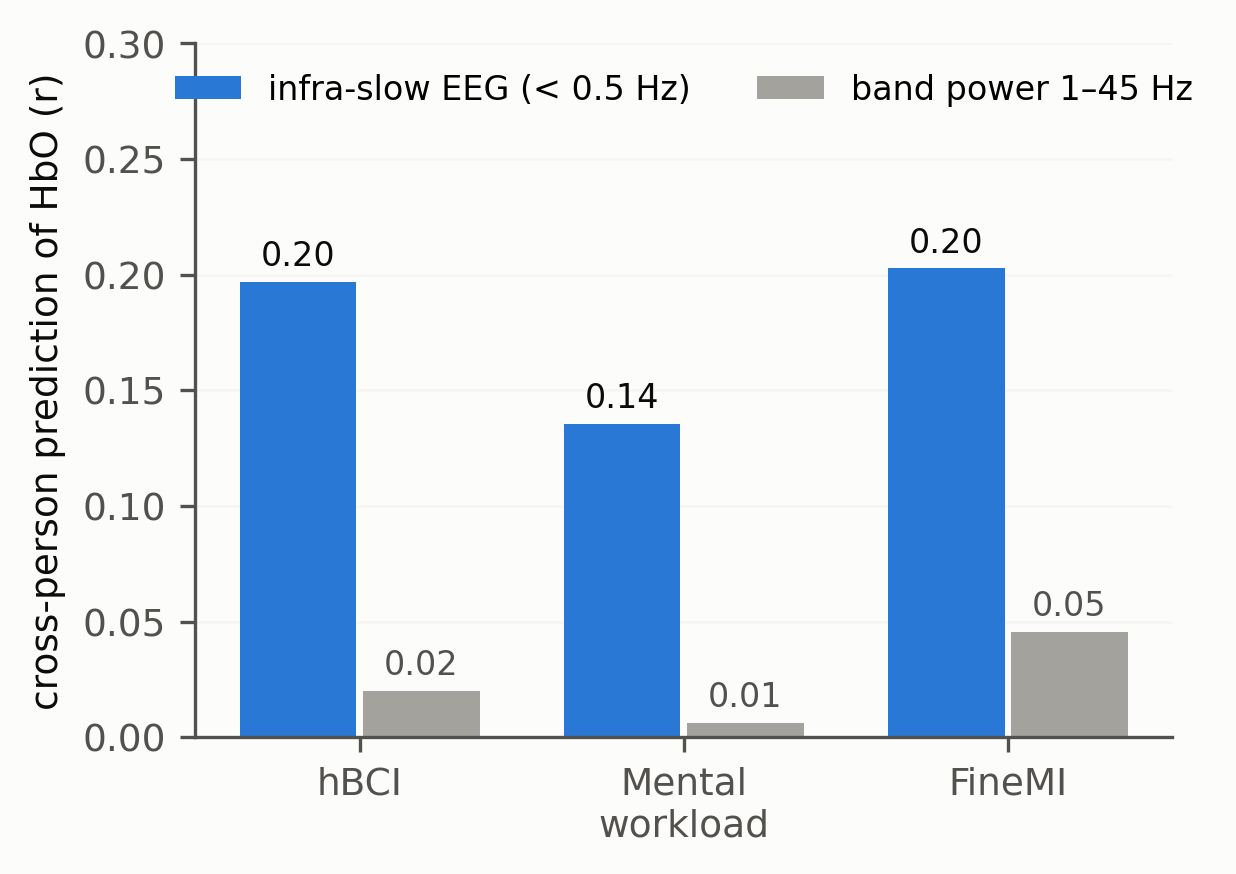

In [21]:
replication(J("replication_finemi_results.json"))
mw, fm = J("replication_results.json"), J("replication_finemi_results.json")
ps = J("person_specific_results_runs.json")["slow"]
def row(name, d):
    a = d["R1"]
    return [name, f"{a['slow_lt0.5']['r_subject']:.3f} {ci(*a['slow_lt0.5']['ci'])}", f"{a['bandpower_1-45']['r_subject']:.3f}",
            f"{a['eog_slow_lt0.5']['r_subject']:.3f}", f"{d['R3']['HbO_local']['r_subject']:.3f}", f"{d['R2']['slow_lt0.5']['identification']:.0%}"]
hb = J("bands_results.json")["lt0.5"]
table([["hBCI", f"0.197 (ridge); {hb['r_subject']:.3f} (deep)", "≈0.02", "14% of all-EEG score", f"{hb['global_local']['HbO_local']['r_subject']:.3f}", f"{ps['identification']:.0%}"],
       row("Mental workload", mw), row("FineMI", fm)],
      ["Cohort", "Slow EEG &lt; 0.5 Hz", "Band power 1–45 Hz", "EOG", "Local HbO", "Person identification"])
def draw_fig1():
    fig, ax = plt.subplots(figsize=(4.2, 3.0))
    R1 = {"mental_workload": RJ("replication_results.json")["R1"], "finemi": RJ("replication_finemi_results.json")["R1"]}
    slow = {"hbci": 0.197, **{c: v["slow_lt0.5"]["r_subject"] for c, v in R1.items()}}
    bp = {"hbci": 0.02, **{c: v["bandpower_1-45"]["r_subject"] for c, v in R1.items()}}
    x = np.arange(3)
    ax.bar(x - 0.19, [slow[c] for c in FIG_COH], 0.36, color="#2a78d6", label="infra-slow EEG (< 0.5 Hz)")
    ax.bar(x + 0.19, [bp[c] for c in FIG_COH], 0.36, color=NEUTRAL, label="band power 1–45 Hz")
    for i, c in enumerate(FIG_COH):
        ax.text(i - 0.19, slow[c] + 0.004, f"{slow[c]:.2f}", ha="center", va="bottom", color=INK, fontsize=8)
        ax.text(i + 0.19, bp[c] + 0.004, f"{bp[c]:.2f}", ha="center", va="bottom", color=INK2, fontsize=8)
    ax.set_xticks(x, ["hBCI", "Mental\nworkload", "FineMI"])
    ax.set_ylabel("cross-person prediction of HbO (r)")
    ax.set_ylim(0, 0.30)
    ax.legend(loc="upper center", fontsize=8, ncol=2)
    ax.grid(axis="x", visible=False)
    save(fig, "fig1_slow_band")


draw_fig1()
fig("fig1_slow_band", 420)

## 8. Claim 1: shared fNIRS + fMRI space

Claim 1. Fits one shared linear EEG space (rank 32, fixed in advance) that predicts both fNIRS and fMRI, and tests it on unseen people. It also checks whether real fMRI targets help fNIRS more than shuffled ones. Output: `claim1_fresh_<cohort>_results.json`. Rerun name: `claim1_fresh`.

In [22]:
def claim1_fresh(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os

    import json
    from pathlib import Path

    import nbformat
    import numpy as np
    import scipy.signal as sps
    from sklearn.linear_model import RidgeCV

    NB = Path(f"{PROJECT_ROOT}/merge/Neurovascnet_marge_v1.ipynb")
    ROOT = NB.parent / "neurovascnet_merge_v1_cache"
    FNIRS, FMRI = ROOT / "train_fnirs_a2133f5d6a71ec34", ROOT / "train_fmri_56be430c4098b1ee"
    COH = os.environ.get("FNIRS_COHORT", "mental_workload")
    FNIRS = {"hbci": FNIRS, "mental_workload": ROOT / "replication_tuberlin_mw", "finemi": ROOT / "replication_finemi"}[COH]
    SEED = int(os.environ.get("SEED", "1337"))
    SCARCE = int(os.environ.get("SCARCE", "0"))
    LOCAL = os.environ.get("TARGET", "") == "local"
    OUT = NB_OUT.joinpath(f"claim1_fresh_{COH}" + (f"_scarce{SCARCE}" if SCARCE else "") + (f"_seed{SEED}" if SEED != 1337 else "") + ("_local" if LOCAL else "") + "_results.json")
    FS, RANK = 200.0, 32
    ALPHAS = np.logspace(0, 6, 13)

    ns = globals()
    subject_level_test, interpolation_matrix, _center = ns["subject_level_test"], ns["interpolation_matrix"], ns["_center"]

    def _bins(x, nb_):
        return x.reshape(*x.shape[:-1], nb_, -1).mean(-1)

    def load(cache, local=False):
        eeg = np.load(cache / "eeg.npy", mmap_mode="r")
        sos = sps.butter(4, 0.5, btype="low", fs=FS, output="sos")
        F = np.concatenate([_bins(sps.sosfiltfilt(sos, np.asarray(eeg[i:i + 120], np.float64), axis=-1), 30)
                            for i in range(0, len(eeg), 120)])
        hemo = np.load(cache / "hemo.npy").astype(np.float64)
        if hemo.shape[-1] == 300:
            hemo = _bins(hemo, 30)
        if local:
            k_ = hemo.shape[1] // 2
            hemo = np.concatenate([hemo[:, :k_] - hemo[:, :k_].mean(1, keepdims=True),
                                   hemo[:, k_:] - hemo[:, k_:].mean(1, keepdims=True)], 1)
        sid, tid = np.load(cache / "subject_ids.npy"), np.load(cache / "task_ids.npy")
        meta = json.loads((cache / "meta.json").read_text())
        return {"F": F, "Y": hemo.reshape(len(hemo), -1), "sid": sid, "tid": tid, "rec": np.load(cache / "rec_ids.npy"),
                "g": sid.astype(np.int64) * 1000 + tid, "ch": meta["info"]["ch_names"] if "info" in meta else meta["ch_names"]}

    def zs_person(F, sid):
        F = F.reshape(len(F), -1).copy()
        for s in np.unique(sid):
            m = sid == s
            F[m] = (F[m] - F[m].mean(0)) / (F[m].std(0) + 1e-8)
        return F

    def demean(Y, g):
        Y = Y.copy()
        for k in np.unique(g):
            m = g == k
            Y[m] -= Y[m].mean(0)
        return Y

    def per_subject_r(P, T, sid):
        return {int(s): float(np.diag(_center(P[sid == s]) @ _center(T[sid == s]).T).mean()) for s in np.unique(sid)}

    def boot_ci(v, rng):
        v = np.asarray(v)
        return [float(x) for x in np.percentile([v[rng.integers(0, len(v), len(v))].mean() for _ in range(5000)], [2.5, 97.5])]

    a = load(FNIRS, local=LOCAL)
    WHICH = os.environ.get("FMRI_SET", "pooled")
    parts = []
    SETS = {"ds002336": [(0, FMRI)], "ds002338": [(100, ROOT / "replication_ds002338")]}
    SETS["pooled"] = SETS["ds002336"] + SETS["ds002338"]
    for off, cache in SETS[WHICH]:
        d_ = load(cache)
        W = interpolation_matrix(d_["ch"], a["ch"])
        assert W is not None, cache
        d_["F"] = np.einsum("ij,njt->nit", W, d_["F"])
        d_["sid"] = d_["sid"] + off
        d_["tid"] = d_["tid"] + off
        d_["g"] = d_["sid"].astype(np.int64) * 1000 + d_["tid"]
        parts.append(d_)
    b = {k: np.concatenate([p[k] for p in parts]) for k in ("F", "Y", "sid", "tid", "rec", "g")}
    print("fMRI arm:", WHICH, len(np.unique(b["sid"])), "people", len(b["sid"]), "trials", flush=True)
    Fa, Fb = zs_person(a["F"], a["sid"]), zs_person(b["F"], b["sid"])
    Ya, Yb = demean(a["Y"], a["g"]), demean(b["Y"], b["g"])
    rng = np.random.default_rng(SEED)
    Yb_shuf = Yb.copy()
    for s in np.unique(b["sid"]):
        m = np.flatnonzero(b["sid"] == s)
        Yb_shuf[m] = Yb[rng.permutation(m)]
    print(f"fNIRS {Fa.shape} -> {Ya.shape[1]} targets; fMRI {Fb.shape} -> {Yb.shape[1]} targets", flush=True)

    def basis(rank, *Bs):
        M = np.hstack([B / np.linalg.norm(B) for B in Bs])
        return np.linalg.svd(M, full_matrices=False)[0][:, :rank]

    def coef(F, Y):
        return RidgeCV(alphas=ALPHAS).fit(F, Y).coef_.T

    def boot90(v, rng):
        v = np.asarray(v)
        return [float(x) for x in np.percentile([v[rng.integers(0, len(v), len(v))].mean() for _ in range(5000)], [5, 95])]

    subs = np.unique(a["sid"])
    folds = np.array_split(np.random.default_rng(SEED).permutation(subs), 5)
    Bm_all, Bm_shuf = coef(Fb, Yb), coef(Fb, Yb_shuf)
    R = RANK
    P = {k: np.zeros_like(Ya) for k in ("full", "single", "joint", "joint_shuffled")}
    for i, hold in enumerate(folds):
        te = np.isin(a["sid"], hold)
        trn = ~te
        if SCARCE:
            keep = np.random.default_rng(SEED).choice(np.setdiff1d(subs, hold), SCARCE, replace=False)
            trn = np.isin(a["sid"], keep)
        full = RidgeCV(alphas=ALPHAS).fit(Fa[trn], Ya[trn])
        P["full"][te] = full.predict(Fa[te])
        Ba = full.coef_.T
        for key, U in (("single", basis(R, Ba)), ("joint", basis(R, Ba, Bm_all)), ("joint_shuffled", basis(R, Ba, Bm_shuf))):
            head = RidgeCV(alphas=ALPHAS).fit(Fa[trn] @ U, Ya[trn])
            P[key][te] = head.predict(Fa[te] @ U)
        print("fold", i, "done", flush=True)
    fn = {k: subject_level_test(demean(v, a["g"]), Ya, a["sid"]) for k, v in P.items()}
    per_fn = {k: per_subject_r(demean(v, a["g"]), Ya, a["sid"]) for k, v in P.items()}
    print("fNIRS", {k: round(v["r_subject"], 4) for k, v in fn.items()}, flush=True)

    if SCARCE:
        import sys as _s
        rng = np.random.default_rng(SEED)
        d_fn = [per_fn["joint"][q] - per_fn["single"][q] for q in sorted(per_fn["single"])]
        d_js = [per_fn["joint"][q] - per_fn["joint_shuffled"][q] for q in sorted(per_fn["single"])]
        c1, c2 = boot_ci(d_fn, rng), boot_ci(d_js, rng)
        ok = bool(np.mean(d_fn) > 0 and c1[0] > 0 and np.mean(d_js) > 0 and c2[0] > 0)
        print(f"SCARCE {SCARCE} {COH}: joint - single {np.mean(d_fn):+.4f} {c1}; joint - shuffled {np.mean(d_js):+.4f} {c2} -> {'PASS' if ok else 'FAIL'}")
        OUT.write_text(json.dumps({"fnirs": fn, "joint_minus_single": [float(np.mean(d_fn)), c1], "joint_minus_shuffled": [float(np.mean(d_js)), c2], "pass": ok}, indent=1, default=float))
        print("DONE"); _s.exit(0)
    Ba_all = coef(Fa, Ya)
    Q = {k: np.zeros_like(Yb) for k in ("full", "specific", "joint")}
    for s_ in np.unique(b["sid"]):
        te = b["sid"] == s_
        full = RidgeCV(alphas=ALPHAS).fit(Fb[~te], Yb[~te])
        Q["full"][te] = full.predict(Fb[te])
        Bm = full.coef_.T
        for key, U in (("specific", basis(R, Bm)), ("joint", basis(R, Ba_all, Bm))):
            head = RidgeCV(alphas=ALPHAS).fit(Fb[~te] @ U, Yb[~te])
            Q[key][te] = head.predict(Fb[te] @ U)
    fm = {k: subject_level_test(demean(v, b["g"]), Yb, b["sid"]) for k, v in Q.items()}
    per_fm = {k: per_subject_r(demean(v, b["g"]), Yb, b["sid"]) for k, v in Q.items()}

    rng = np.random.default_rng(SEED)
    d_fn = [per_fn["joint"][s] - per_fn["single"][s] for s in sorted(per_fn["single"])]
    d_js = [per_fn["joint"][s] - per_fn["joint_shuffled"][s] for s in sorted(per_fn["single"])]
    ci95_fn, ci95_js = boot_ci(d_fn, rng), boot_ci(d_js, rng)
    p31 = bool(np.mean(d_fn) > 0 and ci95_fn[0] > 0 and np.mean(d_js) > 0 and ci95_js[0] > 0)
    d_fm = [per_fm["joint"][s] - per_fm["specific"][s] for s in sorted(per_fm["specific"])]
    ci_fn, ci_fm = boot90(d_fn, rng), boot90(d_fm, rng)
    j_fn, j_fm = fn["joint"], fm["joint"]
    both_work = (j_fn["ci_low"] > 0 and j_fn["p_signflip"] < 0.05 and j_fn["r_subject"] >= 0.05
                 and j_fm["ci_low"] > 0 and j_fm["p_signflip"] < 0.05)
    no_cost = ci_fn[0] > -0.02 and ci_fm[0] > -0.02
    res = {"fnirs_cohort": COH, "rank": R, "fnirs": fn, "fmri": fm,
           "p31_joint_minus_single_ci95": {"mean": float(np.mean(d_fn)), "ci": ci95_fn},
           "p31_joint_minus_shuffled_ci95": {"mean": float(np.mean(d_js)), "ci": ci95_js}, "p31_form_pass": p31,
           "fnirs_joint_minus_specific": {"mean": float(np.mean(d_fn)), "ci90": ci_fn},
           "fmri_joint_minus_specific": {"mean": float(np.mean(d_fm)), "ci90": ci_fm},
           "both_outputs_work": bool(both_work), "no_cost_from_sharing": bool(no_cost),
           "claim1_shared_space_holds": bool(both_work and no_cost)}
    f = lambda t: f"{t['r_subject']:+.4f} [{t['ci_low']:+.4f}, {t['ci_high']:+.4f}] p_sf {t['p_signflip']:.4f}"
    print(f"fNIRS {COH} (rank {R}): full {f(fn['full'])} | specific {f(fn['single'])} | joint {f(j_fn)} | joint-shuffled {f(fn['joint_shuffled'])}")
    print(f"P3.1 form: joint - single {np.mean(d_fn):+.4f} 95% CI {ci95_fn}; joint - shuffled {np.mean(d_js):+.4f} {ci95_js} -> {'PASS' if p31 else 'FAIL'}")
    print(f"fMRI  (rank {R}): full {f(fm['full'])} | specific {f(fm['specific'])} | joint {f(j_fm)}")
    print(f"joint - specific: fNIRS {np.mean(d_fn):+.4f} 90% CI {ci_fn}, fMRI {np.mean(d_fm):+.4f} 90% CI {ci_fm}")
    print(f"both outputs work: {both_work} | no cost from sharing: {no_cost} -> Claim 1 (shared space) "
          f"{'HOLDS' if both_work and no_cost else 'DOES NOT HOLD'}")
    OUT.write_text(json.dumps(res, indent=1, default=float))
    print("DONE")


# RERUN: set RUN = {"claim1_fresh"} in section 2
if should("claim1_fresh"):
    run_with_env(claim1_fresh, FNIRS_COHORT="mental_workload")
    run_with_env(claim1_fresh, FNIRS_COHORT="finemi")
    run_with_env(claim1_fresh, FNIRS_COHORT="hbci")

**Result.** One EEG space predicts both outputs in unseen people. The cost column is the 90% CI lower bound, against a margin of −0.02 fixed in advance.

In [23]:
c1m, c1f = J("claim1_fresh_mental_workload_results.json"), J("claim1_fresh_finemi_results.json")
c1h = J("claim1_fresh_hbci_results.json")
rows = []
for n, d in (("Mental workload (primary)", c1m), ("FineMI", c1f), ("hBCI", c1h)):
    f, g = d["fnirs"]["joint"], d["fmri"]["joint"]
    rows.append([n, f"{f['r_subject']:.3f} {ci(f['ci_low'], f['ci_high'])}", f"{g['r_subject']:.3f} {ci(g['ci_low'], g['ci_high'])}",
                 f"{d['fnirs_joint_minus_specific']['ci90'][0]:+.3f}", f"{d['p31_joint_minus_shuffled_ci95']['mean']:+.4f}", "yes" if d["claim1_shared_space_holds"] else "no"])
table(rows, ["fNIRS cohort", "fNIRS r", "fMRI r", "Cost to fNIRS, 90% CI low (margin −0.02)", "Joint − shuffled fMRI", "Shared space holds"])

fNIRS cohort,fNIRS r,fMRI r,"Cost to fNIRS, 90% CI low (margin −0.02)",Joint − shuffled fMRI,Shared space holds
Mental workload (primary),"0.123 [+0.080, +0.169]","0.068 [+0.043, +0.095]",-0.014,-0.0009,yes
FineMI,"0.180 [+0.141, +0.226]","0.063 [+0.039, +0.089]",+0.002,+0.0028,yes
hBCI,"0.178 [+0.140, +0.214]","0.068 [+0.043, +0.095]",+0.001,+0.0009,yes


## 9. Claim 2: external validation

Claim 2 within one lab. A slow-EEG ridge model is frozen on hBCI and tested on mental workload, and the reverse. Output: `external_claim2_results.json`. Rerun name: `external_claim2`.

In [24]:
def external_claim2(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os

    import json
    from pathlib import Path

    import nbformat
    import numpy as np
    import scipy.signal as sps
    from sklearn.linear_model import RidgeCV

    NB = Path(f"{PROJECT_ROOT}/merge/Neurovascnet_marge_v1.ipynb")
    ROOT = NB.parent / "neurovascnet_merge_v1_cache"
    CACHES = {"hbci": ROOT / "train_fnirs_a2133f5d6a71ec34", "mental_workload": ROOT / "replication_tuberlin_mw"}
    OUT = NB_OUT.joinpath("external_claim2_results.json")
    FS, SEED = 200.0, 1337
    ALPHAS = np.logspace(0, 6, 13)

    ns = globals()
    subject_level_test, verdict_text, interpolation_matrix = ns["subject_level_test"], ns["verdict_text"], ns["interpolation_matrix"]
    print("practical_r =", ns["CFG"].practical_r)

    def _bins(x, nb_):
        return x.reshape(*x.shape[:-1], nb_, -1).mean(-1)

    def load(name):
        cache = CACHES[name]
        eeg = np.load(cache / "eeg.npy", mmap_mode="r")
        sos = sps.butter(4, 0.5, btype="low", fs=FS, output="sos")
        F = np.concatenate([_bins(sps.sosfiltfilt(sos, np.asarray(eeg[i:i + 120], np.float64), axis=-1), 30)
                            for i in range(0, len(eeg), 120)])
        hemo = np.load(cache / "hemo.npy").astype(np.float64)
        Y = _bins(np.stack([hemo[:, :36].mean(1), hemo[:, 36:].mean(1)], 1), 30).reshape(len(hemo), -1)
        meta = json.loads((cache / "meta.json").read_text())
        chans = meta["info"]["ch_names"] if "info" in meta else meta["ch_names"]
        return {"F": F, "Y": Y, "ch": chans, "sid": np.load(cache / "subject_ids.npy"),
                "tid": np.load(cache / "task_ids.npy"), "rec": np.load(cache / "rec_ids.npy")}

    def zs_person(F, sid):
        F = F.reshape(len(F), -1).copy()
        for s in np.unique(sid):
            m = sid == s
            F[m] = (F[m] - F[m].mean(0)) / (F[m].std(0) + 1e-8)
        return F

    def demean(Y, g):
        Y = Y.copy()
        for k in np.unique(g):
            m = g == k
            Y[m] -= Y[m].mean(0)
        return Y

    def trial_corr(P, T):
        P = P - P.mean(1, keepdims=True)
        T = T - T.mean(1, keepdims=True)
        return (P * T).sum(1) / (np.linalg.norm(P, axis=1) * np.linalg.norm(T, axis=1) + 1e-12)

    D = {k: load(k) for k in CACHES}
    for k, d in D.items():
        print(k, d["F"].shape, len(d["ch"]), "channels")

    res = {}
    for src, dst in (("hbci", "mental_workload"), ("mental_workload", "hbci")):
        a, b = D[src], D[dst]
        W = interpolation_matrix(b["ch"], a["ch"])
        assert W is not None, "interpolation matrix unavailable"
        Fb = np.einsum("ij,njt->nit", W, b["F"])
        Fa_z, Fb_z = zs_person(a["F"], a["sid"]), zs_person(Fb, b["sid"])
        Ya = demean(a["Y"], a["sid"] * 1000 + a["tid"])
        mdl = RidgeCV(alphas=ALPHAS).fit(Fa_z, Ya)
        g = b["sid"].astype(np.int64) * 1000 + b["tid"]
        P = demean(mdl.predict(Fb_z), g)
        T = demean(b["Y"], g)
        st = subject_level_test(P, T, b["sid"])
        st["verdict"] = verdict_text(st)
        st["alpha"] = float(mdl.alpha_)
        st["claim2_pass"] = bool(st["verdict"] == "detectable")
        for nm, sl in (("HbO", slice(0, 30)), ("HbR", slice(30, 60))):
            st[f"r_{nm}"] = subject_level_test(P[:, sl], T[:, sl], b["sid"])["r_subject"]
        res[f"{src}_to_{dst}"] = st
        print(f"{src} -> {dst}: r_subject {st['r_subject']:+.4f} [{st['ci_low']:+.4f}, {st['ci_high']:+.4f}] "
              f"null {st['null_mean']:+.4f} p_sf {st['p_signflip']:.4f} ({st['n_positive']}/{st['n_subjects']}) "
              f"HbO {st['r_HbO']:+.4f} HbR {st['r_HbR']:+.4f} -> {st['verdict']} | Claim 2 pass: {st['claim2_pass']}",
              flush=True)

        rng = np.random.default_rng(SEED)
        per = {"baseline": [], "personal": [], "hybrid_external": [], "frozen_external": []}
        for s in np.unique(b["sid"]):
            m = np.flatnonzero(b["sid"] == s)
            runs = np.unique(b["rec"][m])
            if len(runs) < 3:
                continue
            acc = {k: [] for k in per}
            for test_run in runs:
                te = m[b["rec"][m] == test_run]
                pool = [r for r in runs if r != test_run]
                cal = [pool[i] for i in rng.choice(len(pool), 2, replace=False)]
                ca = m[np.isin(b["rec"][m], cal)]
                task = b["tid"][te][0]
                mt = b["tid"][ca] == task
                base = b["Y"][ca][mt].mean(0) if mt.any() else b["Y"][ca].mean(0)
                Fr = Fb.reshape(len(Fb), -1)
                mu, sd = Fr[ca].mean(0), Fr[ca].std(0) + 1e-8
                Fca, Fte = (Fr[ca] - mu) / sd, (Fr[te] - mu) / sd
                Rca = b["Y"][ca] - base
                pers = RidgeCV(alphas=ALPHAS).fit(Fca, Rca).predict(Fte)
                ext = mdl.predict(Fte)
                for k, Pk in (("baseline", np.broadcast_to(base, (len(te), base.size))), ("personal", base + pers),
                              ("hybrid_external", base + 0.5 * (pers + ext)), ("frozen_external", base + ext)):
                    acc[k].append(trial_corr(Pk, b["Y"][te]).mean())
            for k in per:
                per[k].append(float(np.mean(acc[k])))
        cal = {k: float(np.mean(v)) for k, v in per.items()}
        gain = np.array(per["hybrid_external"]) - np.array(per["baseline"])
        boot = [gain[rng.integers(0, len(gain), len(gain))].mean() for _ in range(5000)]
        cal["hybrid_minus_baseline"] = float(gain.mean())
        cal["hybrid_minus_baseline_ci"] = [float(x) for x in np.percentile(boot, [2.5, 97.5])]
        res[f"{src}_to_{dst}"]["calibration_k2"] = cal
        print("   k=2 calibration (raw score): " + ", ".join(f"{k} {v:+.3f}" for k, v in cal.items() if not k.endswith("ci")),
              cal["hybrid_minus_baseline_ci"], flush=True)
        OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"external_claim2"} in section 2
if should("external_claim2"):
    external_claim2()

**Result.** Transfer of the slow-EEG model within the TU Berlin lab.

In [25]:
d = J("external_claim2_results.json")
table([[k.replace("_to_", " → "), f"{v['r_subject']:+.3f}", ci(v["ci_low"], v["ci_high"]), f"{v['p_signflip']:.4f}", f"{v['n_positive']}/{v['n_subjects']}", v["verdict"]] for k, v in d.items()],
      ["Direction", "r", "95% CI", "p", "People with r > 0", "Verdict"])

Direction,r,95% CI,p,People with r > 0,Verdict
hbci → mental_workload,+0.205,"[+0.128, +0.285]",0.0002,20/26,detectable
mental_workload → hbci,+0.177,"[+0.143, +0.211]",0.0001,28/29,detectable


Claim 2 across labs. The same frozen model is tested on FineMI, with five versions of the data: plain, detrended, linked-mastoid reference, Euclidean alignment and emulated hardware filter. Output: `external_finemi*_results.json`. Rerun name: `external_finemi`.

In [26]:
def external_finemi(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os

    import json
    from pathlib import Path

    import nbformat
    import numpy as np
    import scipy.signal as sps
    from sklearn.linear_model import RidgeCV

    NB = Path(f"{PROJECT_ROOT}/merge/Neurovascnet_marge_v1.ipynb")
    ROOT = NB.parent / "neurovascnet_merge_v1_cache"
    CACHES = {"hbci": ROOT / "train_fnirs_a2133f5d6a71ec34", "mental_workload": ROOT / "replication_tuberlin_mw", "finemi": ROOT / ("replication_finemi" + os.environ.get("FINEMI_TAG", "") + ("_lm" if os.environ.get("REREF") else ""))}
    EA = bool(os.environ.get("EA"))
    OUT = NB_OUT.joinpath("external_finemi" + os.environ.get("FINEMI_TAG", "") + ("_ea" if os.environ.get("EA") else "") + ("_lm" if os.environ.get("REREF") else "") + ("_detrend" if os.environ.get("DETREND") else "") + "_results.json")
    FS, SEED = 200.0, 1337
    ALPHAS = np.logspace(0, 6, 13)

    ns = globals()
    subject_level_test, verdict_text, interpolation_matrix = ns["subject_level_test"], ns["verdict_text"], ns["interpolation_matrix"]
    print("practical_r =", ns["CFG"].practical_r)

    def _bins(x, nb_):
        return x.reshape(*x.shape[:-1], nb_, -1).mean(-1)

    def load(name):
        cache = CACHES[name]
        eeg = np.load(cache / "eeg.npy", mmap_mode="r")
        sos = sps.butter(4, 0.5, btype="low", fs=FS, output="sos")
        prep = (lambda x: sps.detrend(x, axis=-1)) if os.environ.get("DETREND") else (lambda x: x)
        F = np.concatenate([_bins(sps.sosfiltfilt(sos, prep(np.asarray(eeg[i:i + 120], np.float64)), axis=-1), 30)
                            for i in range(0, len(eeg), 120)])
        hemo = np.load(cache / "hemo.npy").astype(np.float64)
        k_ = hemo.shape[1] // 2
        Y = _bins(np.stack([hemo[:, :k_].mean(1), hemo[:, k_:].mean(1)], 1), 30).reshape(len(hemo), -1)
        meta = json.loads((cache / "meta.json").read_text())
        chans = meta["info"]["ch_names"] if "info" in meta else meta["ch_names"]
        return {"F": F, "Y": Y, "ch": chans, "sid": np.load(cache / "subject_ids.npy"),
                "tid": np.load(cache / "task_ids.npy"), "rec": np.load(cache / "rec_ids.npy")}

    def ea_person(F, sid):
        """Whiten each person's (n, ch, t) slow features by that person's mean spatial covariance (unsupervised)."""
        F = F.copy()
        for s in np.unique(sid):
            m = sid == s
            X = F[m] - F[m].mean(-1, keepdims=True)
            C = np.einsum("nct,ndt->cd", X, X) / (X.shape[0] * X.shape[2])
            C += 1e-3 * np.trace(C) / len(C) * np.eye(len(C))
            w, V = np.linalg.eigh(C)
            F[m] = np.einsum("cd,ndt->nct", V @ np.diag(w ** -0.5) @ V.T, F[m])
        return F

    def zs_person(F, sid):
        F = F.reshape(len(F), -1).copy()
        for s in np.unique(sid):
            m = sid == s
            F[m] = (F[m] - F[m].mean(0)) / (F[m].std(0) + 1e-8)
        return F

    def demean(Y, g):
        Y = Y.copy()
        for k in np.unique(g):
            m = g == k
            Y[m] -= Y[m].mean(0)
        return Y

    def trial_corr(P, T):
        P = P - P.mean(1, keepdims=True)
        T = T - T.mean(1, keepdims=True)
        return (P * T).sum(1) / (np.linalg.norm(P, axis=1) * np.linalg.norm(T, axis=1) + 1e-12)

    D = {k: load(k) for k in CACHES}
    for k, d in D.items():
        print(k, d["F"].shape, len(d["ch"]), "channels")

    res = {}
    DIRS = (("hbci", "finemi"), ("mental_workload", "finemi"), ("finemi", "hbci"))
    if os.environ.get("DETREND") or EA or os.environ.get("FINEMI_TAG"):
        DIRS += (("hbci", "mental_workload"), ("mental_workload", "hbci"))
    for src, dst in DIRS:
        a, b = D[src], D[dst]
        W = interpolation_matrix(b["ch"], a["ch"])
        assert W is not None, "interpolation matrix unavailable"
        Fb = np.einsum("ij,njt->nit", W, b["F"])
        Fa_, Fb = (ea_person(a["F"], a["sid"]), ea_person(Fb, b["sid"])) if EA else (a["F"], Fb)
        Fa_z, Fb_z = zs_person(Fa_, a["sid"]), zs_person(Fb, b["sid"])
        Ya = demean(a["Y"], a["sid"] * 1000 + a["tid"])
        mdl = RidgeCV(alphas=ALPHAS).fit(Fa_z, Ya)
        g = b["sid"].astype(np.int64) * 1000 + b["tid"]
        P = demean(mdl.predict(Fb_z), g)
        T = demean(b["Y"], g)
        st = subject_level_test(P, T, b["sid"])
        st["verdict"] = verdict_text(st)
        st["alpha"] = float(mdl.alpha_)
        st["claim2_pass"] = bool(st["verdict"] == "detectable")
        for nm, sl in (("HbO", slice(0, 30)), ("HbR", slice(30, 60))):
            st[f"r_{nm}"] = subject_level_test(P[:, sl], T[:, sl], b["sid"])["r_subject"]
        res[f"{src}_to_{dst}"] = st
        print(f"{src} -> {dst}: r_subject {st['r_subject']:+.4f} [{st['ci_low']:+.4f}, {st['ci_high']:+.4f}] "
              f"null {st['null_mean']:+.4f} p_sf {st['p_signflip']:.4f} ({st['n_positive']}/{st['n_subjects']}) "
              f"HbO {st['r_HbO']:+.4f} HbR {st['r_HbR']:+.4f} -> {st['verdict']} | Claim 2 pass: {st['claim2_pass']}",
              flush=True)

        rng = np.random.default_rng(SEED)
        per = {"baseline": [], "personal": [], "hybrid_external": [], "frozen_external": []}
        for s in np.unique(b["sid"]):
            m = np.flatnonzero(b["sid"] == s)
            runs = np.unique(b["rec"][m])
            if len(runs) < 3:
                continue
            acc = {k: [] for k in per}
            for test_run in runs:
                te = m[b["rec"][m] == test_run]
                pool = [r for r in runs if r != test_run]
                cal = [pool[i] for i in rng.choice(len(pool), 2, replace=False)]
                ca = m[np.isin(b["rec"][m], cal)]
                task = b["tid"][te][0]
                mt = b["tid"][ca] == task
                base = b["Y"][ca][mt].mean(0) if mt.any() else b["Y"][ca].mean(0)
                Fr = Fb.reshape(len(Fb), -1)
                mu, sd = Fr[ca].mean(0), Fr[ca].std(0) + 1e-8
                Fca, Fte = (Fr[ca] - mu) / sd, (Fr[te] - mu) / sd
                Rca = b["Y"][ca] - base
                pers = RidgeCV(alphas=ALPHAS).fit(Fca, Rca).predict(Fte)
                ext = mdl.predict(Fte)
                for k, Pk in (("baseline", np.broadcast_to(base, (len(te), base.size))), ("personal", base + pers),
                              ("hybrid_external", base + 0.5 * (pers + ext)), ("frozen_external", base + ext)):
                    acc[k].append(trial_corr(Pk, b["Y"][te]).mean())
            for k in per:
                per[k].append(float(np.mean(acc[k])))
        cal = {k: float(np.mean(v)) for k, v in per.items()}
        gain = np.array(per["hybrid_external"]) - np.array(per["baseline"])
        boot = [gain[rng.integers(0, len(gain), len(gain))].mean() for _ in range(5000)]
        cal["hybrid_minus_baseline"] = float(gain.mean())
        cal["hybrid_minus_baseline_ci"] = [float(x) for x in np.percentile(boot, [2.5, 97.5])]
        res[f"{src}_to_{dst}"]["calibration_k2"] = cal
        print("   k=2 calibration (raw score): " + ", ".join(f"{k} {v:+.3f}" for k, v in cal.items() if not k.endswith("ci")),
              cal["hybrid_minus_baseline_ci"], flush=True)
        OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"external_finemi"} in section 2
if should("external_finemi"):
    external_finemi()
    run_with_env(external_finemi, DETREND="1")
    run_with_env(external_finemi, REREF="lm")
    run_with_env(external_finemi, EA="1")
    run_with_env(external_finemi, FINEMI_TAG="_hw")

**Result.** Transfer of the slow-EEG model to the other lab, under each harmonisation.

In [27]:
rows = []
for n, f in (("plain", ""), ("detrend", "_detrend"), ("linked mastoids", "_lm"), ("Euclidean alignment", "_ea"), ("hardware emulation", "_hw")):
    v = J(f"external_finemi{f}_results.json")["hbci_to_finemi"]
    rows.append([n, f"{v['r_subject']:+.3f}", ci(v["ci_low"], v["ci_high"]), f"{v['n_positive']}/{v['n_subjects']}"])
table(rows, ["hBCI → FineMI", "r", "95% CI", "People with r > 0"])

hBCI → FineMI,r,95% CI,People with r > 0
plain,-0.023,"[-0.050, +0.004]",6/18
detrend,-0.024,"[-0.051, +0.002]",7/18
linked mastoids,-0.025,"[-0.055, +0.004]",5/18
Euclidean alignment,-0.027,"[-0.054, +0.001]",7/18
hardware emulation,-0.064,"[-0.094, -0.037]",3/18


Claim 2 across labs, after matching the time window and the electrode montage between cohorts. Output: `harmonised_transfer_results.json`. Rerun name: `harmonised_transfer`.

In [28]:
def harmonised_transfer(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os

    import json
    from pathlib import Path

    import nbformat
    import numpy as np
    import scipy.signal as sps
    from sklearn.linear_model import RidgeCV

    NB = Path(f"{PROJECT_ROOT}/merge/Neurovascnet_marge_v1.ipynb")
    ROOT = NB.parent / "neurovascnet_merge_v1_cache"
    TAG = os.environ.get("FINEMI_TAG", "")
    CACHES = {"hbci": ROOT / "train_fnirs_a2133f5d6a71ec34", "mental_workload": ROOT / "replication_tuberlin_mw",
              "finemi": ROOT / ("replication_finemi" + TAG)}
    OUT = NB_OUT.joinpath(f"harmonised_transfer{TAG}_results.json")
    FS, NWIN = 200.0, 20
    ALPHAS = np.logspace(0, 6, 13)
    HBCI_LEFT_MOTOR = np.arange(12, 24)

    ns = globals()
    subject_level_test, verdict_text, interpolation_matrix = ns["subject_level_test"], ns["verdict_text"], ns["interpolation_matrix"]

    def _bins(x, nb_):
        return x.reshape(*x.shape[:-1], nb_, -1).mean(-1)

    def load(name):
        cache = CACHES[name]
        eeg = np.load(cache / "eeg.npy", mmap_mode="r")
        sos = sps.butter(4, 0.5, btype="low", fs=FS, output="sos")
        F = np.concatenate([_bins(sps.sosfiltfilt(sos, np.asarray(eeg[i:i + 120], np.float64), axis=-1), 30)
                            for i in range(0, len(eeg), 120)])
        hemo = _bins(np.load(cache / "hemo.npy").astype(np.float64), 30)
        k_ = hemo.shape[1] // 2
        meta = json.loads((cache / "meta.json").read_text())
        return {"F": F, "hbo": hemo[:, :k_], "hbr": hemo[:, k_:],
                "ch": meta["info"]["ch_names"] if "info" in meta else meta["ch_names"],
                "sid": np.load(cache / "subject_ids.npy"), "tid": np.load(cache / "task_ids.npy")}

    def view(d, window, motor):
        """Features (n, ch, t) and pooled target (n, 2*t) for one harmonisation setting."""
        sl = slice(0, NWIN) if window else slice(None)
        idx = HBCI_LEFT_MOTOR if (motor and d["hbo"].shape[1] == 36 and d is D["hbci"]) else slice(None)
        Y = np.concatenate([d["hbo"][:, idx].mean(1)[:, sl], d["hbr"][:, idx].mean(1)[:, sl]], 1)
        return d["F"][..., sl], Y

    def zs_person(F, sid):
        F = F.reshape(len(F), -1).copy()
        for s in np.unique(sid):
            m = sid == s
            F[m] = (F[m] - F[m].mean(0)) / (F[m].std(0) + 1e-8)
        return F

    def demean(Y, g):
        Y = Y.copy()
        for k in np.unique(g):
            m = g == k
            Y[m] -= Y[m].mean(0)
        return Y

    D = {k: load(k) for k in CACHES}
    res = {}
    RUNS = [("hbci", "finemi", True, True, "primary: window + montage"),
            ("hbci", "finemi", True, False, "window only"),
            ("hbci", "finemi", False, True, "montage only"),
            ("mental_workload", "finemi", True, False, "MW window only"),
            ("finemi", "hbci", True, True, "reverse, window + montage"),
            ("hbci", "mental_workload", True, True, "within lab reference, window + montage")]
    for src, dst, win, mot, label in RUNS:
        a, b = D[src], D[dst]
        Fa, Ya = view(a, win, mot)
        Fb, Yb = view(b, win, mot)
        W = interpolation_matrix(b["ch"], a["ch"])
        Fb = np.einsum("ij,njt->nit", W, Fb)
        mdl = RidgeCV(alphas=ALPHAS).fit(zs_person(Fa, a["sid"]), demean(Ya, a["sid"] * 1000 + a["tid"]))
        g = b["sid"].astype(np.int64) * 1000 + b["tid"]
        P = demean(mdl.predict(zs_person(Fb, b["sid"])), g)
        T = demean(Yb, g)
        st = subject_level_test(P, T, b["sid"])
        st["verdict"] = verdict_text(st)
        st["pass"] = bool(st["verdict"] == "detectable")
        h = Yb.shape[1] // 2
        st["r_HbO"] = subject_level_test(P[:, :h], T[:, :h], b["sid"])["r_subject"]
        st["r_HbR"] = subject_level_test(P[:, h:], T[:, h:], b["sid"])["r_subject"]
        res[f"{src}_to_{dst} | {label}"] = st
        print(f"{src} -> {dst} [{label}]: r {st['r_subject']:+.4f} [{st['ci_low']:+.4f}, {st['ci_high']:+.4f}] "
              f"p_sf {st['p_signflip']:.4f} ({st['n_positive']}/{st['n_subjects']}) HbO {st['r_HbO']:+.4f} "
              f"HbR {st['r_HbR']:+.4f} -> {st['verdict']}", flush=True)
        OUT.write_text(json.dumps(res, indent=1, default=float))
    print("DONE")


# RERUN: set RUN = {"harmonised_transfer"} in section 2
if should("harmonised_transfer"):
    harmonised_transfer()

**Result.** Transfer after matching the time window and the electrode montage.

In [29]:
d = J("harmonised_transfer_results.json")
table([[k, f"{v['r_subject']:+.3f}", ci(v["ci_low"], v["ci_high"]), f"{v['p_signflip']:.4f}", f"{v['n_positive']}/{v['n_subjects']}", "pass" if v["pass"] else "fail"] for k, v in d.items()],
      ["Test", "r", "95% CI", "p", "People with r > 0", "Rule"])

Test,r,95% CI,p,People with r > 0,Rule
hbci_to_finemi | primary: window + montage,-0.010,"[-0.041, +0.021]",0.5338,8/18,fail
hbci_to_finemi | window only,-0.019,"[-0.050, +0.013]",0.2673,8/18,fail
hbci_to_finemi | montage only,-0.013,"[-0.040, +0.012]",0.3438,7/18,fail
mental_workload_to_finemi | MW window only,+0.002,"[-0.027, +0.035]",0.9261,6/18,fail
"finemi_to_hbci | reverse, window + montage",-0.055,"[-0.118, +0.004]",0.1003,14/29,fail
"hbci_to_mental_workload | within lab reference, window + montage",+0.230,"[+0.156, +0.309]",0.0001,21/26,pass


Claim 2 across labs, calibrated form: does the frozen slow-EEG model add to a person's own two-run model? Output: `calibrated_transfer_results.json`. Rerun name: `calibrated_transfer`.

In [30]:
def calibrated_transfer(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os

    import json
    from pathlib import Path

    import nbformat
    import numpy as np
    import scipy.signal as sps
    from sklearn.linear_model import RidgeCV

    NB = Path(f"{PROJECT_ROOT}/merge/Neurovascnet_marge_v1.ipynb")
    ROOT = NB.parent / "neurovascnet_merge_v1_cache"
    TAG = os.environ.get("FINEMI_TAG", "")
    CACHES = {"hbci": ROOT / "train_fnirs_a2133f5d6a71ec34", "mental_workload": ROOT / "replication_tuberlin_mw",
              "finemi": ROOT / ("replication_finemi" + TAG)}
    OUT = NB_OUT.joinpath(f"calibrated_transfer{TAG}_results.json")
    FS, SEED = 200.0, 1337
    ALPHAS = np.logspace(0, 6, 13)

    ns = globals()
    interpolation_matrix = ns["interpolation_matrix"]

    def _bins(x, nb_):
        return x.reshape(*x.shape[:-1], nb_, -1).mean(-1)

    def load(name):
        cache = CACHES[name]
        eeg = np.load(cache / "eeg.npy", mmap_mode="r")
        sos = sps.butter(4, 0.5, btype="low", fs=FS, output="sos")
        F = np.concatenate([_bins(sps.sosfiltfilt(sos, np.asarray(eeg[i:i + 120], np.float64), axis=-1), 30)
                            for i in range(0, len(eeg), 120)])
        hemo = np.load(cache / "hemo.npy").astype(np.float64)
        k_ = hemo.shape[1] // 2
        Y = _bins(np.stack([hemo[:, :k_].mean(1), hemo[:, k_:].mean(1)], 1), 30).reshape(len(hemo), -1)
        meta = json.loads((cache / "meta.json").read_text())
        return {"F": F, "Y": Y, "ch": meta["info"]["ch_names"] if "info" in meta else meta["ch_names"],
                "sid": np.load(cache / "subject_ids.npy"), "tid": np.load(cache / "task_ids.npy"),
                "rec": np.load(cache / "rec_ids.npy")}

    def zs_person(F, sid):
        F = F.reshape(len(F), -1).copy()
        for s in np.unique(sid):
            m = sid == s
            F[m] = (F[m] - F[m].mean(0)) / (F[m].std(0) + 1e-8)
        return F

    def demean(Y, g):
        Y = Y.copy()
        for k in np.unique(g):
            m = g == k
            Y[m] -= Y[m].mean(0)
        return Y

    def trial_corr(P, T):
        P = P - P.mean(1, keepdims=True)
        T = T - T.mean(1, keepdims=True)
        return (P * T).sum(1) / (np.linalg.norm(P, axis=1) * np.linalg.norm(T, axis=1) + 1e-12)

    def task_means(Y, tid, ref_tid):
        return np.stack([Y[tid == t].mean(0) if np.any(tid == t) else Y.mean(0) for t in ref_tid])

    def run(src, dst):
        a, b = D[src], D[dst]
        W = interpolation_matrix(b["ch"], a["ch"])
        Fb = np.einsum("ij,njt->nit", W, b["F"]).reshape(len(b["F"]), -1)
        mdl = RidgeCV(alphas=ALPHAS).fit(zs_person(a["F"], a["sid"]), demean(a["Y"], a["sid"] * 1000 + a["tid"]))
        rng = np.random.default_rng(SEED)
        per = {}
        for s in np.unique(b["sid"]):
            m = np.flatnonzero(b["sid"] == s)
            runs = np.unique(b["rec"][m])
            if len(runs) < 3:
                continue
            cal = list(rng.choice(runs, 2, replace=False))
            ca, te = m[np.isin(b["rec"][m], cal)], m[~np.isin(b["rec"][m], cal)]
            mu, sd = Fb[ca].mean(0), Fb[ca].std(0) + 1e-8
            Z = (Fb - mu) / sd
            base_ca, base_te = task_means(b["Y"][ca], b["tid"][ca], b["tid"][ca]), task_means(b["Y"][ca], b["tid"][ca], b["tid"][te])
            R = b["Y"][ca] - base_ca
            pers_cf = np.zeros_like(R)
            for r_ in cal:
                i_fit, i_pred = b["rec"][ca] != r_, b["rec"][ca] == r_
                pers_cf[i_pred] = RidgeCV(alphas=ALPHAS).fit(Z[ca][i_fit], R[i_fit]).predict(Z[ca][i_pred])
            pers_te = RidgeCV(alphas=ALPHAS).fit(Z[ca], R).predict(Z[te])
            ext_ca, ext_te = mdl.predict(Z[ca]), mdl.predict(Z[te])
            e_mean_ca = task_means(ext_ca, b["tid"][ca], b["tid"][ca])
            ext_ca_c, ext_te_c = ext_ca - e_mean_ca, ext_te - task_means(ext_ca, b["tid"][ca], b["tid"][te])
            g_p = np.linalg.lstsq(pers_cf.reshape(-1, 1), R.ravel(), rcond=None)[0]
            g_b = np.linalg.lstsq(np.stack([pers_cf.ravel(), ext_ca_c.ravel()], 1), R.ravel(), rcond=None)[0]
            P_pers = base_te + g_p[0] * pers_te
            P_both = base_te + g_b[0] * pers_te + g_b[1] * ext_te_c
            Yt = b["Y"][te]
            per[int(s)] = {"baseline": float(trial_corr(np.broadcast_to(base_te, Yt.shape), Yt).mean()),
                           "personal": float(trial_corr(P_pers, Yt).mean()),
                           "personal_plus_external": float(trial_corr(P_both, Yt).mean()),
                           "ext_gain_sign": float(np.sign(g_b[1]))}
        d = np.array([v["personal_plus_external"] - v["personal"] for v in per.values()])
        boot = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(5000)]
        ci = [float(x) for x in np.percentile(boot, [2.5, 97.5])]
        out = {k: float(np.mean([v[k] for v in per.values()])) for k in ("baseline", "personal", "personal_plus_external")}
        out.update({"diff": float(d.mean()), "ci": ci, "n_better": int(np.sum(d > 0)), "n": len(d),
                    "frac_negative_external_gain": float(np.mean([v["ext_gain_sign"] < 0 for v in per.values()])),
                    "pass": bool(d.mean() > 0 and ci[0] > 0), "people": per})
        print(f"{src} -> {dst}: baseline {out['baseline']:.3f} personal {out['personal']:.3f} personal+external "
              f"{out['personal_plus_external']:.3f} | diff {out['diff']:+.4f} {ci} ({out['n_better']}/{out['n']}), "
              f"negative external gain in {out['frac_negative_external_gain']:.2f} -> {'PASS' if out['pass'] else 'FAIL'}", flush=True)
        return out

    D = {k: load(k) for k in CACHES}
    res = {}
    for src, dst in (("hbci", "finemi"), ("mental_workload", "finemi"), ("hbci", "mental_workload")):
        res[f"{src}_to_{dst}"] = run(src, dst)
        OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"calibrated_transfer"} in section 2
if should("calibrated_transfer"):
    calibrated_transfer()

**Result.** Gain from adding the frozen slow-EEG model to a person's own two-run model.

In [31]:
d = J("calibrated_transfer_results.json")
table([[k.replace("_to_", " → "), f"{v['personal']:.3f}", f"{v['personal_plus_external']:.3f}", f"{v['diff']:+.4f}", ci(*v["ci"]), f"{v['n_better']}/{v['n']}", "pass" if v["pass"] else "fail"] for k, v in d.items()],
      ["Direction", "Own model", "Own + external", "Gain", "95% CI", "People better", "Rule"])

Direction,Own model,Own + external,Gain,95% CI,People better,Rule
hbci → finemi,0.103,0.103,-0.0001,"[-0.003, +0.003]",10/18,fail
mental_workload → finemi,0.105,0.105,+0.0000,"[-0.003, +0.002]",12/18,fail
hbci → mental_workload,0.319,0.378,+0.0588,"[+0.023, +0.095]",18/26,pass


## 10. Continuous-recording loaders and band-power coupling

Loaders for the continuous hBCI and mental-workload recordings, helpers that align EEG with fNIRS at 1 Hz, and the lag between slow EEG and HbO. The analyses below reuse the loaders. Output: `continuous_lag_results.json`. Rerun name: `continuous_lag`.

In [32]:
def continuous_lag(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os

    import json
    from pathlib import Path

    import nbformat
    import numpy as np
    import scipy.io as sio
    import scipy.signal as sps
    from scipy.stats import wilcoxon

    NB = Path(f"{PROJECT_ROOT}/merge/Neurovascnet_marge_v1.ipynb")
    MW = Path(f"{PROJECT_ROOT}/dataset/TU Berlin EEG + NIRS")
    OUT = NB_OUT.joinpath("continuous_lag_results.json")
    MAXLAG, MINSHIFT, NSURR, SEED = 20, 60, 200, 1337
    EOG = ("VEOG", "HEOG")

    ns = globals()
    _runs, beer_lambert, split_wl = ns["_runs"], ns["beer_lambert"], ns["_split_wavelengths"]
    HBCI = ns["PATHS"]["train_fnirs"]

    def to_1hz(x, fs, lo, hi):
        """(ch, T) -> band-limited, 1 Hz."""
        if lo is None:
            sos = sps.butter(4, hi, btype="low", fs=fs, output="sos")
        else:
            sos = sps.butter(4, [lo, hi], btype="band", fs=fs, output="sos")
        y = sps.sosfiltfilt(sos, x, axis=-1)
        step = int(round(fs))
        n = y.shape[-1] // step
        return y[:, :n * step].reshape(y.shape[0], n, step).mean(-1)

    def run_pair(eeg, e_fs, hbo, n_fs, offset_s):
        """EEG (ch, T) and HbO (ch, T) of one run; NIRS time = EEG time + offset. Returns aligned 1 Hz series."""
        e = to_1hz(eeg, e_fs, None, 0.1)
        e = e - e.mean(1, keepdims=True)
        u, s, vt = np.linalg.svd(e, full_matrices=False)
        pc = vt[0] * s[0]
        h = to_1hz(hbo, n_fs, 0.01, 0.1).mean(0)
        sh = int(round(offset_s))
        a0, b0 = max(0, -sh), min(len(pc), len(h) - sh)
        if b0 - a0 < 3 * MAXLAG + MINSHIFT:
            return None
        return pc[a0:b0], h[a0 + sh:b0 + sh]

    def xcorr(a, b):
        """r at lags -MAXLAG..MAXLAG; positive lag = a (EEG) earlier than b (HbO)."""
        a = (a - a.mean()) / (a.std() + 1e-12)
        b = (b - b.mean()) / (b.std() + 1e-12)
        out = []
        for L in range(-MAXLAG, MAXLAG + 1):
            if L >= 0:
                x, y = a[:len(a) - L], b[L:]
            else:
                x, y = a[-L:], b[:len(b) + L]
            out.append(np.corrcoef(x, y)[0, 1])
        return np.abs(np.array(out))

    def person_stats(pairs, rng):
        curves = np.array([xcorr(a, b) for a, b in pairs])
        curve = curves.mean(0)
        lag = int(np.argmax(curve)) - MAXLAG
        peak = curve.max()
        null = []
        for _ in range(NSURR):
            c = []
            for a, b in pairs:
                k = rng.integers(MINSHIFT, max(MINSHIFT + 1, len(b) - MINSHIFT))
                c.append(xcorr(a, np.roll(b, k)))
            null.append(np.mean(c, 0).max())
        p = float((np.sum(np.array(null) >= peak) + 1) / (NSURR + 1))
        return {"lag_s": lag, "peak_abs_r": float(peak), "p_null": p, "curve": curve.round(4).tolist(),
                "n_runs": len(pairs)}

    HOOK = {"run_pair": run_pair}

    def hbci_people():
        eeg_dir, nirs_dir = HBCI / "EEG data", HBCI / "NRI data" / "NIRS_01-29"
        for s in range(1, 30):
            ed = next((g / f"subject {s:02d}" / "with occular artifact" for g in sorted(eeg_dir.glob("EEG_*"))
                       if (g / f"subject {s:02d}" / "with occular artifact").exists()), None)
            er_all, em_all = _runs(ed / "cnt.mat", "cnt"), _runs(ed / "mrk.mat", "mrk")
            nr_all, nm_all = _runs(nirs_dir / f"subject {s:02d}" / "cnt.mat", "cnt"), \
                _runs(nirs_dir / f"subject {s:02d}" / "mrk.mat", "mrk")
            pairs = []
            for r in range(min(er_all.size, nr_all.size, em_all.size, nm_all.size)):
                er, nr, em, nm = er_all[r], nr_all[r], em_all[r], nm_all[r]
                clab = [str(c) for c in np.atleast_1d(er.clab)]
                keep = [i for i, c in enumerate(clab) if c not in EOG]
                ex = np.asarray(er.x, float)[:, keep].T
                lo, hi = split_wl(np.asarray(nr.x, float), nr.clab)
                hbo, _ = beer_lambert(lo, hi)
                off = float(np.atleast_1d(nm.time)[0] - np.atleast_1d(em.time)[0]) / 1000.0
                pr = HOOK["run_pair"](ex, float(np.atleast_1d(er.fs).ravel()[0]), np.asarray(hbo, float),
                              float(np.atleast_1d(nr.fs).ravel()[0]), off)
                if pr is not None:
                    pairs.append(pr)
            yield f"hbci_s{s:02d}", pairs

    def mw_people():
        L = lambda p, k: sio.loadmat(p, squeeze_me=True, struct_as_record=False)[k]
        for s in range(1, 27):
            vp = f"VP{s:03d}"
            ce, me = L(MW / "EEG" / f"{vp}-EEG" / "cnt_nback.mat", "cnt_nback"), L(MW / "EEG" / f"{vp}-EEG" / "mrk_nback.mat", "mrk_nback")
            cn, mn = L(MW / "NIRS" / f"{vp}-NIRS" / "cnt_nback.mat", "cnt_nback"), L(MW / "NIRS" / f"{vp}-NIRS" / "mrk_nback.mat", "mrk_nback")
            names = [str(c) for c in np.atleast_1d(me.className)]
            ye = np.asarray(me.y)
            sess = [i for i, c in enumerate(names) if "session" in c]
            te = np.asarray(me.time, float)[ye[sess].sum(0) > 0] / 1000.0
            tn = np.asarray(mn.time, float) / 1000.0
            assert len(te) == len(tn), vp
            off = tn - te
            run = np.concatenate([[0], np.cumsum(np.abs(np.diff(off)) > 1.0)])
            clab = [str(c) for c in np.atleast_1d(ce.clab)]
            keep = [i for i, c in enumerate(clab) if c not in EOG]
            ex = np.asarray(ce.x, float)[:, keep].T
            hbo = np.asarray(cn.oxy.x, float).T
            e_fs, n_fs = float(ce.fs), float(cn.oxy.fs)
            pairs = []
            for r in np.unique(run):
                m = run == r
                a, b = te[m].min() - 20.0, te[m].max() + 60.0
                ia, ib = max(0, int(a * e_fs)), min(ex.shape[1], int(b * e_fs))
                o = float(np.median(off[m]))
                na, nb_ = max(0, int((a + o) * n_fs)), min(hbo.shape[1], int((b + o) * n_fs))
                seg_e, seg_n = ex[:, ia:ib], hbo[:, na:nb_]
                n = min(seg_e.shape[1] / e_fs, seg_n.shape[1] / n_fs)
                pr = HOOK["run_pair"](seg_e[:, :int(n * e_fs)], e_fs, seg_n[:, :int(n * n_fs)], n_fs, 0.0)
                if pr is not None:
                    pairs.append(pr)
            yield f"mw_{vp}", pairs

    if LIB:
        return locals()

    rng = np.random.default_rng(SEED)
    res = {}
    for cohort, gen in (("hbci", hbci_people), ("mental_workload", mw_people)):
        people = {}
        for pid, pairs in gen():
            if not pairs:
                print(pid, "no usable runs"); continue
            people[pid] = person_stats(pairs, rng)
            print(f"{pid}: lag {people[pid]['lag_s']:+d} s |r| {people[pid]['peak_abs_r']:.3f} p {people[pid]['p_null']:.3f} "
                  f"({people[pid]['n_runs']} runs)", flush=True)
        lags = np.array([v["lag_s"] for v in people.values()])
        ps = np.array([v["p_null"] for v in people.values()])
        try:
            w = float(wilcoxon(lags).pvalue) if np.any(lags != 0) else 1.0
        except ValueError:
            w = 1.0
        grand = np.mean([v["curve"] for v in people.values()], 0)
        res[cohort] = {"people": people, "n": len(people), "frac_beating_null": float(np.mean(ps < 0.05)),
                       "median_lag_s": float(np.median(lags)), "iqr_lag_s": [float(x) for x in np.percentile(lags, [25, 75])],
                       "wilcoxon_p_vs_0": w, "grand_curve": grand.round(4).tolist(),
                       "grand_peak_lag_s": int(np.argmax(grand)) - MAXLAG}
        r = res[cohort]
        print(f"== {cohort}: n {r['n']}, beat null {r['frac_beating_null']:.2f}, median lag {r['median_lag_s']:+.1f} s "
              f"IQR {r['iqr_lag_s']}, Wilcoxon p {w:.4f}, grand-curve peak {r['grand_peak_lag_s']:+d} s", flush=True)
        OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"continuous_lag"} in section 2
if should("continuous_lag"):
    continuous_lag()

**Result.** Lag between slow EEG and HbO in the simple single-channel form.

In [33]:
d = J("continuous_lag_results.json")
table([[COH[c], f"{d[c]['frac_beating_null']:.0%}", f"{d[c]['median_lag_s']:+.1f} s", str(d[c]["iqr_lag_s"]), f"{d[c]['wilcoxon_p_vs_0']:.4f}"] for c in d], ["Cohort", "Beat null", "Median lag (positive = EEG first)", "IQR", "Wilcoxon p"])

Cohort,Beat null,Median lag (positive = EEG first),IQR,Wilcoxon p
hBCI,72%,-6.0 s,"[-7.0, -2.0]",0.0008
Mental workload,73%,-2.5 s,"[-7.75, 3.5]",0.1779


Claim 3. Classical neurovascular coupling: lagged ridge from EEG band power (theta to gamma) to local HbO, at lags from −10 to +20 s, with each person compared to their own time-shifted null. Also holds the FineMI loader. Output: `nvc_bandpower_results.json`. Rerun name: `nvc_bandpower`.

In [34]:
def nvc_bandpower(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os
    import sys
    from pathlib import Path

    HERE = NB_OUT
    ns = continuous_lag(LIB=True)

    import json
    import warnings

    import numpy as np
    import scipy.signal as sps
    from scipy.stats import pearsonr, wilcoxon
    from sklearn.linear_model import RidgeCV

    warnings.filterwarnings("ignore")
    COHORTS_ENV = os.environ.get("COHORTS", "hbci,mental_workload,finemi").split(",")
    OUT = HERE / "nvc_bandpower_results.json"
    SHARDP = "nvc_smoke" if os.environ.get("SMOKE") else "nvc_shard"
    LAGS = np.arange(-10, 21)
    NSURR, MINSHIFT, SEED = int(os.environ.get("NSURR", "100")), 60, 1337
    ALPHAS = np.logspace(0, 4, 5)
    BANDS = (("theta", 4, 8), ("alpha", 8, 13), ("beta", 13, 30), ("gamma", 30, 45))
    to_1hz, MAXLAG = ns["to_1hz"], ns["MAXLAG"]
    SOS_SLOW = sps.butter(4, [0.01, 0.1], btype="band", fs=1.0, output="sos")

    def bandpower_1hz(x, fs):
        """(ch, T) raw EEG -> (n_s, ch * 4) log band power, 1 s means, band-passed 0.01-0.1 Hz at 1 Hz."""
        step = int(round(fs))
        n = x.shape[-1] // step
        out = []
        for _, lo, hi in BANDS:
            y = sps.sosfiltfilt(sps.butter(4, [lo, hi], btype="band", fs=fs, output="sos"), x, axis=-1)
            p = np.log((y[:, :n * step] ** 2).reshape(x.shape[0], n, step).mean(-1) + 1e-20)
            out.append(sps.sosfiltfilt(SOS_SLOW, p, axis=-1))
        return np.concatenate(out, 0).T

    def run_pair_bp(eeg, e_fs, hbo, n_fs, offset_s):
        e = bandpower_1hz(np.asarray(eeg, float), e_fs)
        h = to_1hz(hbo, n_fs, 0.01, 0.1).T
        sh = int(round(offset_s))
        a0, b0 = max(0, -sh), min(len(e), len(h) - sh)
        if b0 - a0 < 3 * MAXLAG + MINSHIFT:
            return None
        return e[a0:b0], h[a0 + sh:b0 + sh]

    ns["HOOK"]["run_pair"] = run_pair_bp

    def lagged(E, H, L):
        if L >= 0:
            return E[:len(E) - L], H[L:]
        return E[-L:], H[:len(H) + L]

    def colcorr(P, T):
        P, T = P.reshape(len(P), -1), T.reshape(len(T), -1)
        P = P - P.mean(0)
        T = T - T.mean(0)
        return float(np.mean((P * T).sum(0) / (np.linalg.norm(P, axis=0) * np.linalg.norm(T, axis=0) + 1e-12)))

    def prep(pairs, target):
        out = []
        for E, H in pairs:
            E = (E - E.mean(0)) / (E.std(0) + 1e-8)
            g = H.mean(1, keepdims=True)
            out.append((E, H - g if target == "local" else g))
        return out

    def curve(pairs, target):
        pp = prep(pairs, target)
        out = []
        for L in LAGS:
            lp = [lagged(E, Y, L) for E, Y in pp]
            rs = []
            for i in range(len(lp)):
                Xtr = np.concatenate([x for j, (x, _) in enumerate(lp) if j != i])
                Ytr = np.concatenate([y for j, (_, y) in enumerate(lp) if j != i])
                m = RidgeCV(alphas=ALPHAS).fit(Xtr, Ytr)
                rs.append(colcorr(m.predict(lp[i][0]), lp[i][1]))
            out.append(np.mean(rs))
        return np.array(out)

    def band_share(pairs, L):
        lp = [lagged(E, Y, L) for E, Y in prep(pairs, "local")]
        m = RidgeCV(alphas=ALPHAS).fit(np.concatenate([x for x, _ in lp]), np.concatenate([y for _, y in lp]))
        w = np.abs(m.coef_.reshape(-1, len(BANDS), lp[0][0].shape[1] // len(BANDS))).sum((0, 2))
        return {b[0]: float(v) for b, v in zip(BANDS, w / w.sum())}

    def person(pairs, rng):
        c = curve(pairs, "local")
        delay, peak = int(LAGS[np.argmax(c)]), float(c.max())
        null = []
        for _ in range(NSURR):
            sp = [(E, np.roll(H, rng.integers(MINSHIFT, max(MINSHIFT + 1, len(H) - MINSHIFT)), axis=0)) for E, H in pairs]
            null.append(curve(sp, "local").max())
        p = float((np.sum(np.array(null) >= peak) + 1) / (NSURR + 1))
        halves = []
        for h in (0, 1):
            hp = []
            for E, H in pairs:
                n = len(E) // 2
                sl = slice(0, n) if h == 0 else slice(n, None)
                hp.append((E[sl], H[sl]))
            halves.append(int(LAGS[np.argmax(curve(hp, "local"))]))
        cg = curve(pairs, "global")
        return {"delay_s": delay, "peak_r": peak, "p_null": p, "half_delays_s": halves, "curve_local": c.round(4).tolist(),
                "delay_global_s": int(LAGS[np.argmax(cg)]), "peak_r_global": float(cg.max()),
                "curve_global": cg.round(4).tolist(), "band_share": band_share(pairs, delay), "n_runs": len(pairs)}

    def finemi_people():
        """Raw FineMI CNT + NIRx, native reference, the P4 run split (gap > 40 s)."""
        import mne
        mne.set_log_level("ERROR")
        root = Path(f"{PROJECT_ROOT}/dataset/Multi-joint Upper-Limb EEG+FNIR/FineMI/FineMI")
        drop = {"M1", "M2", "CB1", "CB2", "EKG", "EMG", "HEO", "VEO"}

        def events(raw):
            a = raw.annotations
            keep = [i for i, d in enumerate(a.description) if d.replace(".0", "").strip().isdigit()]
            return np.asarray(a.onset)[keep], [int(float(a.description[i])) for i in keep]

        for s in sorted(int(p.name[7:]) for p in root.glob("subject*") if p.is_dir()):
            pairs = []
            for name in sorted(p.stem for p in (root / f"subject{s}" / "EEG").glob("*.cnt")):
                try:
                    e = mne.io.read_raw_cnt(root / f"subject{s}" / "EEG" / f"{name}.cnt", preload=True)
                    te, le = events(e)
                    e.pick([c for c in e.ch_names if c not in drop])
                    e.resample(200.0, npad="auto")
                    x = e.get_data()
                    n = mne.io.read_raw_nirx(root / f"subject{s}" / "fNIRS" / name, preload=True)
                    tn, ln = events(n)
                    hb = mne.preprocessing.nirs.beer_lambert_law(mne.preprocessing.nirs.optical_density(n), ppf=6.0)
                    hbo = hb.get_data(picks=[i for i, c in enumerate(hb.ch_names) if c.endswith("hbo")])
                    n_fs = float(n.info["sfreq"])
                except Exception as exc:
                    print(f"finemi s{s} {name}: unreadable {type(exc).__name__}"); continue
                if le != ln:
                    continue
                run = np.concatenate([[0], np.cumsum(np.diff(te) > 40.0)])
                off = tn - te
                for r in np.unique(run):
                    m = run == r
                    if np.ptp(off[m]) > 1.0:
                        continue
                    o = float(np.median(off[m]))
                    a, bb = max(0.0, te[m].min() - 20.0), te[m].max() + 60.0
                    ia, ib = int(a * 200), min(x.shape[1], int(bb * 200))
                    na, nb_ = max(0, int((a + o) * n_fs)), min(hbo.shape[1], int((bb + o) * n_fs))
                    n_s = min((ib - ia) / 200.0, (nb_ - na) / n_fs)
                    pr = ns["HOOK"]["run_pair"](x[:, ia:ia + int(n_s * 200)], 200.0, hbo[:, na:na + int(n_s * n_fs)], n_fs, 0.0)
                    if pr is not None:
                        pairs.append(pr)
                del x, e, n, hb
            yield f"finemi_s{s:02d}", pairs

    GENS = {"hbci": ns["hbci_people"], "mental_workload": ns["mw_people"], "finemi": finemi_people}
    if LIB:
        return locals()

    COHORTS = tuple((c, GENS[c]) for c in COHORTS_ENV)

    if MODE in ("shard", "all"):
        k, n = SHARD
        sf = HERE / f"{SHARDP}_{k}_of_{n}.json"
        done = json.loads(sf.read_text()) if sf.exists() else {}
        for ci, (cohort, gen) in enumerate(COHORTS):
            ci = ("hbci", "mental_workload", "finemi").index(cohort)
            for pi, (pid, pairs) in enumerate(gen()):
                if (ci * 100 + pi) % n != k or pid in done:
                    continue
                if len(pairs) < 2:
                    print(pid, "fewer than 2 usable runs"); continue
                v = person(pairs, np.random.default_rng([SEED, ci, pi]))
                done[pid] = dict(v, cohort=cohort)
                print(f"{pid}: local delay {v['delay_s']:+d} s r {v['peak_r']:.3f} p {v['p_null']:.3f} halves {v['half_delays_s']} "
                      f"| global delay {v['delay_global_s']:+d} s r {v['peak_r_global']:.3f} | bands "
                      + " ".join(f"{b} {w:.2f}" for b, w in v["band_share"].items()), flush=True)
                sf.write_text(json.dumps(done, indent=1))
        if MODE == "shard":
            print("SHARD DONE"); return

    allp = {}
    for f in sorted(HERE.glob(f"{SHARDP}_*_of_*.json")):
        allp.update(json.loads(f.read_text()))
    rng = np.random.default_rng(SEED)
    res = {}
    for cohort in ("hbci", "mental_workload", "finemi"):
        people = {p: v for p, v in allp.items() if v["cohort"] == cohort}
        if not people:
            continue
        d = np.array([v["delay_s"] for v in people.values()])
        h = np.array([v["half_delays_s"] for v in people.values()], float)
        ps = np.array([v["p_null"] for v in people.values()])
        r_half = float(pearsonr(h[:, 0], h[:, 1])[0]) if h[:, 0].std() > 0 and h[:, 1].std() > 0 else 0.0
        perm = np.array([pearsonr(h[:, 0], rng.permutation(h[:, 1]))[0] for _ in range(10000)])
        p_half = float((np.sum(perm >= r_half) + 1) / 10001)
        try:
            w = float(wilcoxon(d).pvalue) if np.any(d != 0) else 1.0
        except ValueError:
            w = 1.0
        exists = float(np.mean(ps < 0.05)) > 0.5
        reproducible = r_half > 0 and p_half < 0.05
        physio = bool(2 <= np.median(d) <= 10 and w < 0.05)
        edge = int(np.sum(np.isin(h, [LAGS[0], LAGS[-1]])))
        bands = {b[0]: float(np.mean([v["band_share"][b[0]] for v in people.values()])) for b in BANDS}
        res[cohort] = {"people": people, "n": len(people), "frac_beating_null": float(np.mean(ps < 0.05)),
                       "median_delay_s": float(np.median(d)), "iqr_delay_s": [float(x) for x in np.percentile(d, [25, 75])],
                       "wilcoxon_p": w, "split_half_r": r_half, "split_half_perm_p": p_half, "half_estimates_at_edge": edge,
                       "median_global_delay_s": float(np.median([v["delay_global_s"] for v in people.values()])),
                       "median_peak_r": float(np.median([v["peak_r"] for v in people.values()])),
                       "band_share": bands, "exists": bool(exists), "reproducible": bool(reproducible),
                       "claim3a_pass": bool(exists and reproducible), "physiological": physio}
        r = res[cohort]
        print(f"== {cohort}: n {r['n']}, beat null {r['frac_beating_null']:.2f}, median delay {r['median_delay_s']:+.1f} s "
              f"IQR {r['iqr_delay_s']} Wilcoxon p {w:.4f}; split-half r {r_half:+.3f} (perm p {p_half:.4f}, {edge} at edge); "
              f"median peak r {r['median_peak_r']:.3f}; global median {r['median_global_delay_s']:+.1f} s; bands {bands} "
              f"-> Claim 3a {'PASS' if r['claim3a_pass'] else 'FAIL'}, physiological {'YES' if physio else 'NO'}", flush=True)
    res["coupling_classical_supported"] = bool(res.get("hbci", {}).get("claim3a_pass") and any(
        res.get(c, {}).get("claim3a_pass") for c in ("mental_workload", "finemi")))
    print("Classical coupling claim:", "SUPPORTED" if res["coupling_classical_supported"] else "NOT SUPPORTED")
    OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"nvc_bandpower"} in section 2
if should("nvc_bandpower"):
    nvc_bandpower()

**Result and Figure 2.** Band-power coupling per cohort.

Cohort,Beat null,Median delay (positive = EEG first),IQR,Wilcoxon p,Split-half r,p,Peak local r
hBCI,100%,+6.0 s,"[2.0, 8.0]",3.7e-06,+0.39,0.020,0.191
Mental workload,81%,+4.0 s,"[1.0, 8.75]",1.4e-03,-0.15,0.774,0.135
FineMI,89%,+3.0 s,"[-2.25, 5.5]",3.1e-01,+0.12,0.318,0.053


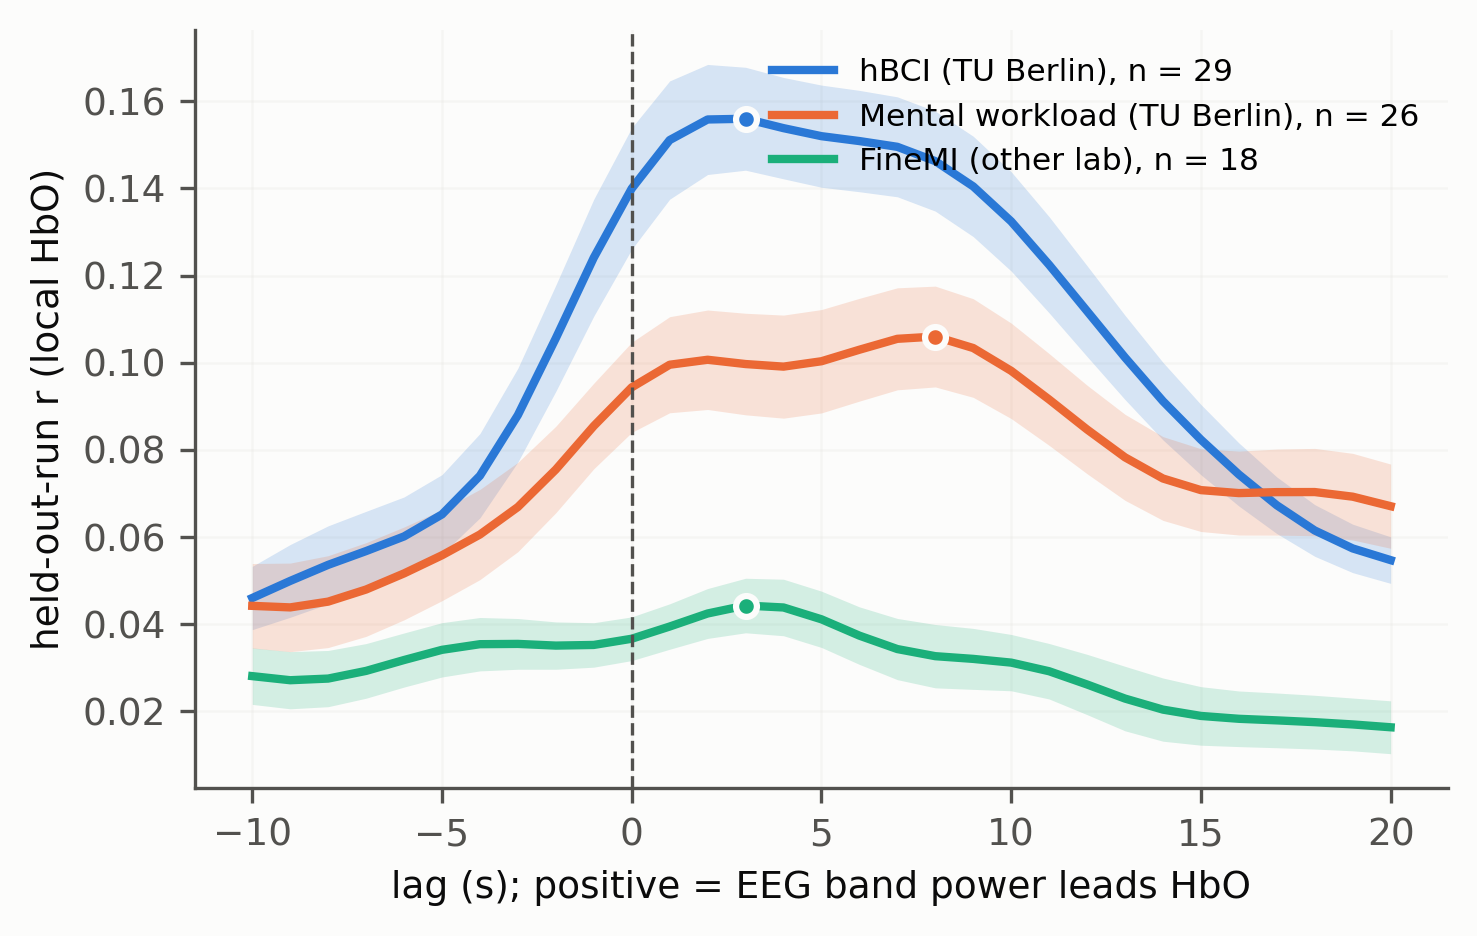

In [35]:
d = J("nvc_bandpower_results.json")
table([[COH[c], f"{d[c]['frac_beating_null']:.0%}", f"{d[c]['median_delay_s']:+.1f} s", str(d[c]["iqr_delay_s"]), f"{d[c]['wilcoxon_p']:.1e}", f"{d[c]['split_half_r']:+.2f}", f"{d[c]['split_half_perm_p']:.3f}", f"{d[c]['median_peak_r']:.3f}"] for c in COH],
      ["Cohort", "Beat null", "Median delay (positive = EEG first)", "IQR", "Wilcoxon p", "Split-half r", "p", "Peak local r"])
def draw_fig2():
    nvc = shards("nvc_shard_*_of_11.json")
    lags = np.arange(-10, 21)
    fig, ax = plt.subplots(figsize=(5.0, 3.2))
    for c, (lab, col) in FIG_COH.items():
        C = np.array([v["curve_local"] for v in nvc.values() if v["cohort"] == c])
        m, se = C.mean(0), C.std(0, ddof=1) / np.sqrt(len(C))
        ax.fill_between(lags, m - se, m + se, color=col, alpha=0.18, linewidth=0)
        ax.plot(lags, m, color=col, label=f"{lab}, n = {len(C)}")
        k = int(np.argmax(m))
        ax.plot(lags[k], m[k], "o", ms=5, color=col, mec=SURF, mew=1.5)
    ax.axvline(0, color=INK2, lw=0.8, ls="--")
    ax.set_xlabel("lag (s); positive = EEG band power leads HbO")
    ax.set_ylabel("held-out-run r (local HbO)")
    ax.legend(fontsize=7.5, loc="upper right")
    save(fig, "fig2_coupling_lag")


draw_fig2()
fig("fig2_coupling_lag", 520)

## 11. Claim 2: coupling-kernel transfer

Claim 2. A band-power coupling kernel is frozen on hBCI and tested on the other cohorts, plus leave-one-person-out within hBCI. Output: `nvc_transfer_results.json`. Rerun name: `nvc_transfer`.

In [36]:
def nvc_transfer(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os
    import sys
    from pathlib import Path

    HERE = NB_OUT
    NS = nvc_bandpower(LIB=True)

    import json

    import nbformat
    import numpy as np
    from sklearn.linear_model import RidgeCV

    inner = NS["ns"]
    interpolation_matrix = nbns["interpolation_matrix"]

    ROOT = inner["NB"].parent / "neurovascnet_merge_v1_cache"
    META = {"hbci": "train_fnirs_a2133f5d6a71ec34", "mental_workload": "replication_tuberlin_mw", "finemi": "replication_finemi"}

    def chans(c):
        m = json.loads((ROOT / META[c] / "meta.json").read_text())
        return m["info"]["ch_names"] if "info" in m else m["ch_names"]

    CH = {c: chans(c) for c in META}
    SEED, NNULL, MINSHIFT = 1337, 200, 60
    LAGS = np.arange(0, 15, 2)
    ALPHAS = np.logspace(0, 6, 7)
    OUT = HERE / "nvc_transfer_results.json"
    orig_bp = NS["run_pair_bp"]
    CUR = {"Ws": {}}

    def run_pair_tr(eeg, e_fs, hbo, n_fs, offset_s):
        """Band power of the EEG mapped onto each source montage; global HbO."""
        eeg = np.asarray(eeg, float)
        out, y = {}, None
        for key, W in CUR["Ws"].items():
            pr = orig_bp(eeg if W is None else W @ eeg, e_fs, hbo, n_fs, offset_s)
            if pr is None:
                return None
            out[key], y = pr[0], pr[1].mean(1)
        return out, y

    inner["HOOK"]["run_pair"] = run_pair_tr

    def design(E, y):
        E = (E - E.mean(0)) / (E.std(0) + 1e-8)
        y = (y - y.mean()) / (y.std() + 1e-8)
        t0 = LAGS.max()
        X = np.concatenate([E[t0 - L:len(E) - L] for L in LAGS], 1)
        return X.astype(np.float32), y[t0:].astype(np.float32)

    def load(cohort, keys):
        CUR["Ws"] = {k: (None if k == cohort else interpolation_matrix(CH[cohort], CH[k])) for k in keys}
        people = {}
        for pid, pairs in NS["GENS"][cohort]():
            if len(pairs) < 1:
                print(pid, "no usable runs"); continue
            people[pid] = {k: [design(E[k], y) for E, y in pairs] for k in keys}
            print(f"loaded {pid}: {len(pairs)} runs", flush=True)
        return people

    def fit(people, key):
        X = np.concatenate([x for p in people.values() for x, _ in p[key]])
        y = np.concatenate([y for p in people.values() for _, y in p[key]])
        m = RidgeCV(alphas=ALPHAS).fit(X, y)
        print(f"fitted on {len(people)} people, {len(y)} s, alpha {m.alpha_:g}", flush=True)
        return m

    def r(a, b):
        a, b = a - a.mean(), b - b.mean()
        return float((a * b).sum() / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))

    def score(pred_fn, people, key, rng):
        per = {}
        for pid, p in people.items():
            runs = [(pred_fn(x), y) for x, y in p[key]]
            obs = float(np.mean([r(a, b) for a, b in runs]))
            null = np.array([np.mean([r(a, np.roll(b, rng.integers(MINSHIFT, max(MINSHIFT + 1, len(b) - MINSHIFT))))
                                      for a, b in runs]) for _ in range(NNULL)])
            per[pid] = {"r": obs, "p_null": float((np.sum(null >= obs) + 1) / (NNULL + 1)), "n_runs": len(runs)}
        v = np.array([q["r"] for q in per.values()])
        boot = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(5000)]
        ci = [float(x) for x in np.percentile(boot, [2.5, 97.5])]
        beat = float(np.mean([q["p_null"] < 0.05 for q in per.values()]))
        return {"mean_r": float(v.mean()), "ci": ci, "n_positive": int(np.sum(v > 0)), "n": len(v),
                "frac_beating_null": beat, "pass": bool(v.mean() > 0 and ci[0] > 0 and beat > 0.5), "people": per}

    def show(name, s):
        print(f"== {name}: mean r {s['mean_r']:+.4f} [{s['ci'][0]:+.4f}, {s['ci'][1]:+.4f}] ({s['n_positive']}/{s['n']} > 0), "
              f"beat null {s['frac_beating_null']:.2f} -> {'PASS' if s['pass'] else 'FAIL'}", flush=True)

    rng = np.random.default_rng(SEED)
    res = {}
    H = load("hbci", ["hbci"])
    m_h = fit(H, "hbci")
    res["lag_weight_share"] = dict(zip([int(L) for L in LAGS], (lambda w: (w / w.sum()).round(3).tolist())(
        np.abs(m_h.coef_.reshape(len(LAGS), -1)).sum(1))))
    print("hBCI kernel weight share by EEG lag (s):", res["lag_weight_share"], flush=True)

    XtX = {p: sum(x.astype(np.float64).T @ x for x, _ in v["hbci"]) for p, v in H.items()}
    Xty = {p: sum(x.astype(np.float64).T @ y for x, y in v["hbci"]) for p, v in H.items()}
    A, B = sum(XtX.values()), sum(Xty.values())
    lopo = {}
    for p in H:
        w = np.linalg.solve(A - XtX[p] + m_h.alpha_ * np.eye(len(A)), B - Xty[p])
        lopo[p] = w
    per_lopo = {}
    for p, v in H.items():
        s1 = score(lambda x, w=lopo[p]: x @ w, {p: v}, "hbci", rng)
        per_lopo[p] = s1["people"][p]
    v_ = np.array([q["r"] for q in per_lopo.values()])
    res["within_hbci_lopo"] = {"mean_r": float(v_.mean()), "frac_beating_null": float(np.mean([q["p_null"] < 0.05 for q in per_lopo.values()])),
                               "people": per_lopo}
    print(f"== within hBCI (leave one person out): mean r {v_.mean():+.4f}, beat null "
          f"{res['within_hbci_lopo']['frac_beating_null']:.2f}", flush=True)
    del XtX, Xty, A, B

    M = load("mental_workload", ["hbci", "mental_workload"])
    res["hbci_to_mental_workload"] = score(m_h.predict, M, "hbci", rng)
    show("hBCI -> mental workload (same lab, reference)", res["hbci_to_mental_workload"])
    m_m = fit(M, "mental_workload")
    del M
    OUT.write_text(json.dumps(res, indent=1))

    F = load("finemi", ["hbci", "mental_workload"])
    res["hbci_to_finemi"] = score(m_h.predict, F, "hbci", rng)
    show("hBCI -> FineMI (other lab, PRIMARY)", res["hbci_to_finemi"])
    res["mental_workload_to_finemi"] = score(m_m.predict, F, "mental_workload", rng)
    show("MW -> FineMI (descriptive)", res["mental_workload_to_finemi"])
    res["claim2_coupling_transfer_cross_lab"] = res["hbci_to_finemi"]["pass"]
    print("Claim 2 (coupling-transfer form, cross-lab):", "PASS" if res["claim2_coupling_transfer_cross_lab"] else "FAIL")
    OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"nvc_transfer"} in section 2
if should("nvc_transfer"):
    nvc_transfer()

**Result.** Frozen band-power kernel, within and between labs.

In [37]:
d = J("nvc_transfer_results.json")
table([["hBCI leave one person out", f"{d['within_hbci_lopo']['mean_r']:+.3f}", "—", f"{d['within_hbci_lopo']['frac_beating_null']:.0%}", "—"]] +
      [[k.replace("_to_", " → "), f"{d[k]['mean_r']:+.3f}", ci(*d[k]["ci"]), f"{d[k]['frac_beating_null']:.0%}", "pass" if d[k]["pass"] else "fail"] for k in ("hbci_to_mental_workload", "hbci_to_finemi", "mental_workload_to_finemi")],
      ["Test", "r", "95% CI", "Beat null", "Rule"])

Test,r,95% CI,Beat null,Rule
hBCI leave one person out,+0.148,—,76%,—
hbci → mental_workload,+0.098,"[+0.071, +0.124]",54%,pass
hbci → finemi,-0.053,"[-0.071, -0.034]",0%,fail
mental_workload → finemi,-0.008,"[-0.027, +0.011]",0%,fail


Claim 2. The frozen kernel with a CBSI target, and the calibrated form: does it add to a person's own two-run model? The second call repeats the calibrated form over five seeds. Output: `nvc_transfer2_results.json`, `nvc_transfer2_seeds_results.json`. Rerun name: `nvc_transfer2`.

In [38]:
def nvc_transfer2(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os
    import sys
    from pathlib import Path

    HERE = NB_OUT
    NS = nvc_bandpower(LIB=True)

    import json

    import nbformat
    import numpy as np
    import scipy.io as sio
    from sklearn.linear_model import RidgeCV

    inner = NS["ns"]
    nbns = inner["ns"]
    interpolation_matrix = nbns["interpolation_matrix"]
    bandpower_1hz, to_1hz = NS["bandpower_1hz"], inner["to_1hz"]
    _runs, beer_lambert, split_wl, HBCI, MW, EOG = (inner[k] for k in ("_runs", "beer_lambert", "split_wl", "HBCI", "MW", "EOG"))
    MAXLAG = inner["MAXLAG"]

    ROOT = inner["NB"].parent / "neurovascnet_merge_v1_cache"
    META = {"hbci": "train_fnirs_a2133f5d6a71ec34", "mental_workload": "replication_tuberlin_mw", "finemi": "replication_finemi"}
    CH = {}
    for c, d in META.items():
        m = json.loads((ROOT / d / "meta.json").read_text())
        CH[c] = m["info"]["ch_names"] if "info" in m else m["ch_names"]
    SEED, NNULL, MINSHIFT = 1337, 200, 60
    LAGS = np.arange(0, 15, 2)
    ALPHAS = np.logspace(0, 6, 7)
    OUT = HERE / "nvc_transfer2_results.json"

    def pair(eeg, e_fs, hbo, hbr, n_fs, off, W):
        """-> (X, {"hbo": y, "cbsi": y}) for one run, or None."""
        eeg = np.asarray(eeg, float)
        E = bandpower_1hz(eeg if W is None else W @ eeg, e_fs)
        ho, hr = to_1hz(np.asarray(hbo, float), n_fs, 0.01, 0.1).T, to_1hz(np.asarray(hbr, float), n_fs, 0.01, 0.1).T
        sh = int(round(off))
        a0, b0 = max(0, -sh), min(len(E), len(ho) - sh)
        if b0 - a0 < 3 * MAXLAG + MINSHIFT:
            return None
        E, ho, hr = E[a0:b0], ho[a0 + sh:b0 + sh], hr[a0 + sh:b0 + sh]
        alpha = ho.std(0) / (hr.std(0) + 1e-12)
        ys = {"hbo": ho.mean(1), "cbsi": ((ho - alpha * hr) / 2).mean(1)}
        E = (E - E.mean(0)) / (E.std(0) + 1e-8)
        t0 = LAGS.max()
        X = np.concatenate([E[t0 - L:len(E) - L] for L in LAGS], 1).astype(np.float32)
        return X, {k: ((y - y.mean()) / (y.std() + 1e-8))[t0:].astype(np.float32) for k, y in ys.items()}

    def hbci_people(W):
        eeg_dir, nirs_dir = HBCI / "EEG data", HBCI / "NRI data" / "NIRS_01-29"
        for s in range(1, 30):
            ed = next((g / f"subject {s:02d}" / "with occular artifact" for g in sorted(eeg_dir.glob("EEG_*"))
                       if (g / f"subject {s:02d}" / "with occular artifact").exists()), None)
            er_all, em_all = _runs(ed / "cnt.mat", "cnt"), _runs(ed / "mrk.mat", "mrk")
            nr_all, nm_all = _runs(nirs_dir / f"subject {s:02d}" / "cnt.mat", "cnt"), _runs(nirs_dir / f"subject {s:02d}" / "mrk.mat", "mrk")
            runs = []
            for r in range(min(er_all.size, nr_all.size, em_all.size, nm_all.size)):
                er, nr, em, nm = er_all[r], nr_all[r], em_all[r], nm_all[r]
                clab = [str(c) for c in np.atleast_1d(er.clab)]
                ex = np.asarray(er.x, float)[:, [i for i, c in enumerate(clab) if c not in EOG]].T
                lo, hi = split_wl(np.asarray(nr.x, float), nr.clab)
                hbo, hbr = beer_lambert(lo, hi)
                off = float(np.atleast_1d(nm.time)[0] - np.atleast_1d(em.time)[0]) / 1000.0
                pr = pair(ex, float(np.atleast_1d(er.fs).ravel()[0]), hbo, hbr, float(np.atleast_1d(nr.fs).ravel()[0]), off, W)
                if pr is not None:
                    runs.append(pr)
            yield f"hbci_s{s:02d}", runs

    def mw_people(W):
        L = lambda p, k: sio.loadmat(p, squeeze_me=True, struct_as_record=False)[k]
        for s in range(1, 27):
            vp = f"VP{s:03d}"
            ce, me = L(MW / "EEG" / f"{vp}-EEG" / "cnt_nback.mat", "cnt_nback"), L(MW / "EEG" / f"{vp}-EEG" / "mrk_nback.mat", "mrk_nback")
            cn, mn = L(MW / "NIRS" / f"{vp}-NIRS" / "cnt_nback.mat", "cnt_nback"), L(MW / "NIRS" / f"{vp}-NIRS" / "mrk_nback.mat", "mrk_nback")
            names = [str(c) for c in np.atleast_1d(me.className)]
            ye = np.asarray(me.y)
            sess = [i for i, c in enumerate(names) if "session" in c]
            te = np.asarray(me.time, float)[ye[sess].sum(0) > 0] / 1000.0
            tn = np.asarray(mn.time, float) / 1000.0
            off = tn - te
            run = np.concatenate([[0], np.cumsum(np.abs(np.diff(off)) > 1.0)])
            clab = [str(c) for c in np.atleast_1d(ce.clab)]
            ex = np.asarray(ce.x, float)[:, [i for i, c in enumerate(clab) if c not in EOG]].T
            hbo, hbr = np.asarray(cn.oxy.x, float).T, np.asarray(cn.deoxy.x, float).T
            e_fs, n_fs = float(ce.fs), float(cn.oxy.fs)
            runs = []
            for r in np.unique(run):
                m = run == r
                a, b = te[m].min() - 20.0, te[m].max() + 60.0
                ia, ib = max(0, int(a * e_fs)), min(ex.shape[1], int(b * e_fs))
                o = float(np.median(off[m]))
                na, nb_ = max(0, int((a + o) * n_fs)), min(hbo.shape[1], int((b + o) * n_fs))
                n = min((ib - ia) / e_fs, (nb_ - na) / n_fs)
                pr = pair(ex[:, ia:ia + int(n * e_fs)], e_fs, hbo[:, na:na + int(n * n_fs)], hbr[:, na:na + int(n * n_fs)], n_fs, 0.0, W)
                if pr is not None:
                    runs.append(pr)
            yield f"mw_{vp}", runs

    def finemi_people(W):
        import mne
        mne.set_log_level("ERROR")
        root = Path(f"{PROJECT_ROOT}/dataset/Multi-joint Upper-Limb EEG+FNIR/FineMI/FineMI")
        drop = {"M1", "M2", "CB1", "CB2", "EKG", "EMG", "HEO", "VEO"}

        def events(raw):
            a = raw.annotations
            keep = [i for i, d in enumerate(a.description) if d.replace(".0", "").strip().isdigit()]
            return np.asarray(a.onset)[keep], [int(float(a.description[i])) for i in keep]

        for s in sorted(int(p.name[7:]) for p in root.glob("subject*") if p.is_dir()):
            runs = []
            for name in sorted(p.stem for p in (root / f"subject{s}" / "EEG").glob("*.cnt")):
                try:
                    e = mne.io.read_raw_cnt(root / f"subject{s}" / "EEG" / f"{name}.cnt", preload=True)
                    te, le = events(e)
                    e.pick([c for c in e.ch_names if c not in drop])
                    e.resample(200.0, npad="auto")
                    x = e.get_data()
                    n = mne.io.read_raw_nirx(root / f"subject{s}" / "fNIRS" / name, preload=True)
                    tn, ln = events(n)
                    hb = mne.preprocessing.nirs.beer_lambert_law(mne.preprocessing.nirs.optical_density(n), ppf=6.0)
                    hbo = hb.get_data(picks=[i for i, c in enumerate(hb.ch_names) if c.endswith("hbo")])
                    hbr = hb.get_data(picks=[i for i, c in enumerate(hb.ch_names) if c.endswith("hbr")])
                    n_fs = float(n.info["sfreq"])
                except Exception as exc:
                    print(f"finemi s{s} {name}: unreadable {type(exc).__name__}"); continue
                if le != ln:
                    continue
                run = np.concatenate([[0], np.cumsum(np.diff(te) > 40.0)])
                off = tn - te
                for r in np.unique(run):
                    m = run == r
                    if np.ptp(off[m]) > 1.0:
                        continue
                    o = float(np.median(off[m]))
                    a, bb = max(0.0, te[m].min() - 20.0), te[m].max() + 60.0
                    ia, ib = int(a * 200), min(x.shape[1], int(bb * 200))
                    na, nb_ = max(0, int((a + o) * n_fs)), min(hbo.shape[1], int((bb + o) * n_fs))
                    n_s = min((ib - ia) / 200.0, (nb_ - na) / n_fs)
                    pr = pair(x[:, ia:ia + int(n_s * 200)], 200.0, hbo[:, na:na + int(n_s * n_fs)],
                              hbr[:, na:na + int(n_s * n_fs)], n_fs, 0.0, W)
                    if pr is not None:
                        runs.append(pr)
                del x, e, n, hb
            yield f"finemi_s{s:02d}", runs

    GENS = {"hbci": hbci_people, "mental_workload": mw_people, "finemi": finemi_people}

    def load(cohort):
        W = None if cohort == "hbci" else interpolation_matrix(CH[cohort], CH["hbci"])
        people = {}
        for pid, runs in GENS[cohort](W):
            if runs:
                people[pid] = runs
                print(f"loaded {pid}: {len(runs)} runs", flush=True)
        return people

    def r(a, b):
        a, b = a - a.mean(), b - b.mean()
        return float((a * b).sum() / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))

    def score(model, people, tgt, rng):
        per = {}
        for pid, runs in people.items():
            pr = [(model.predict(X), ys[tgt]) for X, ys in runs]
            obs = float(np.mean([r(a, b) for a, b in pr]))
            null = np.array([np.mean([r(a, np.roll(b, rng.integers(MINSHIFT, max(MINSHIFT + 1, len(b) - MINSHIFT))))
                                      for a, b in pr]) for _ in range(NNULL)])
            per[pid] = {"r": obs, "p_null": float((np.sum(null >= obs) + 1) / (NNULL + 1))}
        v = np.array([q["r"] for q in per.values()])
        boot = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(5000)]
        ci = [float(x) for x in np.percentile(boot, [2.5, 97.5])]
        beat = float(np.mean([q["p_null"] < 0.05 for q in per.values()]))
        return {"mean_r": float(v.mean()), "ci": ci, "n_positive": int(np.sum(v > 0)), "n": len(v),
                "frac_beating_null": beat, "pass": bool(v.mean() > 0 and ci[0] > 0 and beat > 0.5), "people": per}

    def calibrated(model, people, rng):
        """P8.3: personal two-run model vs personal + frozen external, stacking gains fitted on the calibration runs."""
        per = {}
        for pid, runs in people.items():
            if len(runs) < 3:
                continue
            cal = sorted(rng.choice(len(runs), 2, replace=False).tolist())
            te = [i for i in range(len(runs)) if i not in cal]
            Xc = [runs[i][0] for i in cal]
            yc = [runs[i][1]["hbo"] for i in cal]
            pers_cf = [RidgeCV(alphas=ALPHAS).fit(Xc[1 - j], yc[1 - j]).predict(Xc[j]) for j in (0, 1)]
            ext_c = [model.predict(x) for x in Xc]
            Y = np.concatenate(yc)
            P, E = np.concatenate(pers_cf), np.concatenate(ext_c)
            g_p = np.linalg.lstsq(P[:, None], Y, rcond=None)[0]
            g_b = np.linalg.lstsq(np.stack([P, E], 1), Y, rcond=None)[0]
            g_e = np.linalg.lstsq(E[:, None], Y, rcond=None)[0]
            pm = RidgeCV(alphas=ALPHAS).fit(np.concatenate(Xc), Y)
            rp, rb, re_ = [], [], []
            for i in te:
                X, y = runs[i][0], runs[i][1]["hbo"]
                pt, et = pm.predict(X), model.predict(X)
                rp.append(r(g_p[0] * pt, y))
                rb.append(r(g_b[0] * pt + g_b[1] * et, y))
                re_.append(r(g_e[0] * et, y))
            per[pid] = {"personal": float(np.mean(rp)), "personal_plus_external": float(np.mean(rb)),
                        "external_calibrated": float(np.mean(re_)), "external_gain": float(g_b[1])}
        d = np.array([v["personal_plus_external"] - v["personal"] for v in per.values()])
        boot = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(5000)]
        ci = [float(x) for x in np.percentile(boot, [2.5, 97.5])]
        out = {k: float(np.mean([v[k] for v in per.values()])) for k in ("personal", "personal_plus_external", "external_calibrated")}
        out.update({"diff": float(d.mean()), "ci": ci, "n_better": int(np.sum(d > 0)), "n": len(d),
                    "frac_negative_external_gain": float(np.mean([v["external_gain"] < 0 for v in per.values()])),
                    "pass": bool(d.mean() > 0 and ci[0] > 0), "people": per})
        return out

    def show(name, s):
        print(f"== {name}: mean r {s['mean_r']:+.4f} [{s['ci'][0]:+.4f}, {s['ci'][1]:+.4f}] ({s['n_positive']}/{s['n']} > 0), "
              f"beat null {s['frac_beating_null']:.2f} -> {'PASS' if s['pass'] else 'FAIL'}", flush=True)

    def show_cal(name, s):
        print(f"== {name}: personal {s['personal']:+.4f} personal+external {s['personal_plus_external']:+.4f} "
              f"external calibrated {s['external_calibrated']:+.4f} | diff {s['diff']:+.4f} [{s['ci'][0]:+.4f}, {s['ci'][1]:+.4f}] "
              f"({s['n_better']}/{s['n']}), negative external gain {s['frac_negative_external_gain']:.2f} "
              f"-> {'PASS' if s['pass'] else 'FAIL'}", flush=True)

    if LIB:
        return locals()

    CAL_SEEDS = [int(s) for s in os.environ.get("CAL_SEEDS", "").split(",") if s]
    if CAL_SEEDS:
        OUT = HERE / "nvc_transfer2_seeds_results.json"
    rng = np.random.default_rng(SEED)
    res = {}
    H = load("hbci")
    models = {}
    for tgt in (("hbo",) if CAL_SEEDS else ("hbo", "cbsi")):
        X = np.concatenate([x for runs in H.values() for x, _ in runs])
        y = np.concatenate([ys[tgt] for runs in H.values() for _, ys in runs])
        models[tgt] = RidgeCV(alphas=ALPHAS).fit(X, y)
        print(f"hBCI {tgt} kernel: {len(y)} s, alpha {models[tgt].alpha_:g}", flush=True)
        del X, y
    del H
    if CAL_SEEDS:
        for cohort in ("mental_workload", "finemi"):
            P = load(cohort)
            for sd in CAL_SEEDS:
                res[f"calibrated | {cohort} | seed {sd}"] = calibrated(models["hbo"], P, np.random.default_rng(sd))
                show_cal(f"P8.3b seed {sd} calibrated transfer into {cohort}", res[f"calibrated | {cohort} | seed {sd}"])
            del P
            OUT.write_text(json.dumps(res, indent=1))
        n_pass = sum(res[f"calibrated | finemi | seed {sd}"]["pass"] for sd in CAL_SEEDS)
        print(f"P8.3b FineMI passes {n_pass}/{len(CAL_SEEDS)} seeds -> {'ROBUST' if n_pass >= 4 else 'NOT ROBUST'}")
        print("DONE")
        return
    for cohort in ("mental_workload", "finemi"):
        P = load(cohort)
        for tgt in ("hbo", "cbsi"):
            res[f"hbci_to_{cohort} | {tgt}"] = score(models[tgt], P, tgt, rng)
            show(f"P8.2 hBCI -> {cohort} [{tgt}]", res[f"hbci_to_{cohort} | {tgt}"])
        res[f"calibrated | {cohort}"] = calibrated(models["hbo"], P, np.random.default_rng(SEED))
        show_cal(f"P8.3 calibrated transfer into {cohort}", res[f"calibrated | {cohort}"])
        del P
        OUT.write_text(json.dumps(res, indent=1))
    print("Claim 2 P8.2 (CBSI, cross-lab):", "PASS" if res["hbci_to_finemi | cbsi"]["pass"] else "FAIL")
    print("Claim 2 P8.3 (calibrated, cross-lab):", "PASS" if res["calibrated | finemi"]["pass"] else "FAIL")
    print("DONE")


# RERUN: set RUN = {"nvc_transfer2"} in section 2
if should("nvc_transfer2"):
    nvc_transfer2()
    run_with_env(nvc_transfer2, CAL_SEEDS="1,2,3,4,5")

**Result.** Frozen kernel with a CBSI target, then the calibrated form over six calibration-run seeds. The FineMI gain is nominal: see the summary at the end.

In [39]:
d, sd = J("nvc_transfer2_results.json"), J("nvc_transfer2_seeds_results.json")
table([[k, f"{d[k]['mean_r']:+.3f}", ci(*d[k]["ci"]), f"{d[k]['frac_beating_null']:.0%}", "pass" if d[k]["pass"] else "fail"] for k in d if k.startswith("hbci_to_")], ["Frozen kernel", "r", "95% CI", "Beat null", "Rule"])
all_ = {"seed 1337 | " + k.split(" | ")[1]: v for k, v in d.items() if k.startswith("calibrated")}
all_.update({k.split(" | ")[2] + " | " + k.split(" | ")[1]: v for k, v in sd.items()})
table([[k, f"{v['diff']:+.3f}", ci(*v["ci"]), f"{v['n_better']}/{v['n']}", f"{v['frac_negative_external_gain']:.0%}", "pass" if v["pass"] else "fail"] for k, v in all_.items()], ["Calibrated gain", "Gain", "95% CI", "People better", "Negative external gain", "Rule"])

Frozen kernel,r,95% CI,Beat null,Rule
hbci_to_mental_workload | hbo,+0.098,"[+0.071, +0.124]",54%,pass
hbci_to_mental_workload | cbsi,+0.062,"[+0.029, +0.096]",31%,fail
hbci_to_finemi | hbo,-0.053,"[-0.071, -0.034]",0%,fail
hbci_to_finemi | cbsi,-0.055,"[-0.081, -0.032]",0%,fail


Calibrated gain,Gain,95% CI,People better,Negative external gain,Rule
seed 1337 | mental_workload,+0.066,"[+0.028, +0.110]",19/26,12%,pass
seed 1337 | finemi,+0.020,"[+0.004, +0.039]",11/18,78%,pass
seed 1 | mental_workload,+0.045,"[+0.008, +0.088]",19/26,15%,pass
seed 2 | mental_workload,+0.027,"[-0.013, +0.074]",15/26,19%,fail
seed 3 | mental_workload,+0.036,"[+0.011, +0.063]",18/26,12%,pass
seed 4 | mental_workload,+0.035,"[+0.006, +0.065]",15/26,19%,pass
seed 5 | mental_workload,+0.026,"[-0.004, +0.057]",15/26,15%,fail
seed 1 | finemi,+0.031,"[+0.000, +0.071]",13/18,72%,pass
seed 2 | finemi,+0.015,"[+0.004, +0.025]",15/18,78%,pass
seed 3 | finemi,+0.023,"[+0.010, +0.039]",14/18,78%,pass


Diagnostic for the sign flip into FineMI: kernels restricted to single EEG bands, an alpha + beta kernel, and FineMI leave-one-person-out. Output: `nvc_bands_results.json`. Rerun name: `nvc_bands`.

In [40]:
def nvc_bands(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import sys
    from pathlib import Path

    HERE = NB_OUT
    NS2 = nvc_transfer2(LIB=True)

    import json

    import numpy as np
    from sklearn.linear_model import RidgeCV

    load, score, calibrated, show, show_cal = (NS2[k] for k in ("load", "score", "calibrated", "show", "show_cal"))
    ALPHAS, LAGS, SEED = NS2["ALPHAS"], NS2["LAGS"], NS2["SEED"]
    BANDS = ("theta", "alpha", "beta", "gamma")
    NCH = len(NS2["CH"]["hbci"])
    OUT = HERE / "nvc_bands_results.json"
    NF = len(BANDS) * NCH
    band_of = (np.arange(NF * len(LAGS)) % NF) // NCH

    class Sub:
        def __init__(self, idx, m):
            self.idx, self.m = idx, m

        def predict(self, X):
            return self.m.predict(X[:, self.idx])

    def fit(people, idx=None):
        X = np.concatenate([x for runs in people.values() for x, _ in runs])
        y = np.concatenate([ys["hbo"] for runs in people.values() for _, ys in runs])
        assert X.shape[1] == NF * len(LAGS), X.shape
        idx = np.arange(X.shape[1]) if idx is None else idx
        return Sub(idx, RidgeCV(alphas=ALPHAS).fit(X[:, idx], y))

    def band_sums(model):
        c = model.m.coef_
        full = np.zeros(NF * len(LAGS)); full[model.idx] = c
        return {b: float(full[band_of == i].sum()) for i, b in enumerate(BANDS)}

    def lopo(people, rng):
        """Leave-one-person-out kernel within a cohort, scored with the P7.2 score."""
        preds = {}
        for pid in people:
            m = fit({p: v for p, v in people.items() if p != pid})
            preds[pid] = m
        out = {}
        for pid, runs in people.items():
            out.update(score(preds[pid], {pid: runs}, "hbo", rng)["people"])
        v = np.array([q["r"] for q in out.values()])
        boot = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(5000)]
        ci = [float(x) for x in np.percentile(boot, [2.5, 97.5])]
        beat = float(np.mean([q["p_null"] < 0.05 for q in out.values()]))
        return {"mean_r": float(v.mean()), "ci": ci, "n_positive": int(np.sum(v > 0)), "n": len(v),
                "frac_beating_null": beat, "pass": bool(v.mean() > 0 and ci[0] > 0 and beat > 0.5), "people": out}

    if LIB:
        return locals()

    rng = np.random.default_rng(SEED)
    res = {}
    AB = np.where(np.isin(band_of, [1, 2]))[0]
    H = load("hbci")
    kern = {"all": fit(H), "alpha+beta": fit(H, AB)}
    for i, b in enumerate(BANDS):
        kern[b] = fit(H, np.where(band_of == i)[0])
    res["band_sums | hbci"] = band_sums(kern["all"])
    print("hBCI pooled kernel band sums:", {k: round(v, 4) for k, v in res["band_sums | hbci"].items()}, flush=True)
    del H
    for cohort in ("mental_workload", "finemi"):
        P = load(cohort)
        own = fit(P)
        res[f"band_sums | {cohort}"] = band_sums(own)
        print(f"{cohort} pooled kernel band sums:", {k: round(v, 4) for k, v in res[f"band_sums | {cohort}"].items()}, flush=True)
        for name, m in kern.items():
            res[f"hbci_to_{cohort} | {name}"] = score(m, P, "hbo", rng)
            show(f"hBCI [{name}] -> {cohort}", res[f"hbci_to_{cohort} | {name}"])
        res[f"calibrated | {cohort} | alpha+beta"] = calibrated(kern["alpha+beta"], P, np.random.default_rng(SEED))
        show_cal(f"P9.3 calibrated alpha+beta -> {cohort}", res[f"calibrated | {cohort} | alpha+beta"])
        if cohort == "finemi":
            res["lopo | finemi"] = lopo(P, rng)
            show("P9.2 FineMI leave-one-person-out", res["lopo | finemi"])
        del P
        OUT.write_text(json.dumps(res, indent=1))
    print("P9.3 primary (frozen alpha+beta -> FineMI):", "PASS" if res["hbci_to_finemi | alpha+beta"]["pass"] else "FAIL")
    print("P9.3 secondary (calibrated alpha+beta -> FineMI):", "PASS" if res["calibrated | finemi | alpha+beta"]["pass"] else "FAIL")
    print("DONE")


# RERUN: set RUN = {"nvc_bands"} in section 2
if should("nvc_bands"):
    nvc_bands()

**Result and Figure 4.** Every single band transfers with a negative sign into FineMI, while FineMI people share a kernel of their own.

Kernel,r,95% CI,Beat null,Rule
hBCI → mental_workload | all,+0.098,"[+0.071, +0.124]",54%,pass
hBCI → mental_workload | alpha+beta,+0.089,"[+0.051, +0.128]",54%,pass
hBCI → mental_workload | theta,+0.074,"[+0.039, +0.112]",31%,fail
hBCI → mental_workload | alpha,+0.072,"[+0.040, +0.103]",50%,fail
hBCI → mental_workload | beta,+0.074,"[+0.037, +0.110]",35%,fail
hBCI → mental_workload | gamma,+0.100,"[+0.070, +0.129]",50%,fail
hBCI → finemi | all,-0.053,"[-0.071, -0.034]",0%,fail
hBCI → finemi | alpha+beta,-0.050,"[-0.070, -0.030]",0%,fail
hBCI → finemi | theta,-0.034,"[-0.050, -0.018]",0%,fail
hBCI → finemi | alpha,-0.019,"[-0.035, -0.002]",0%,fail


Calibrated alpha + beta,Gain,95% CI,People better,Rule
mental_workload,+0.065,"[+0.024, +0.114]",19/26,pass
finemi,+0.015,"[-0.003, +0.035]",11/18,fail


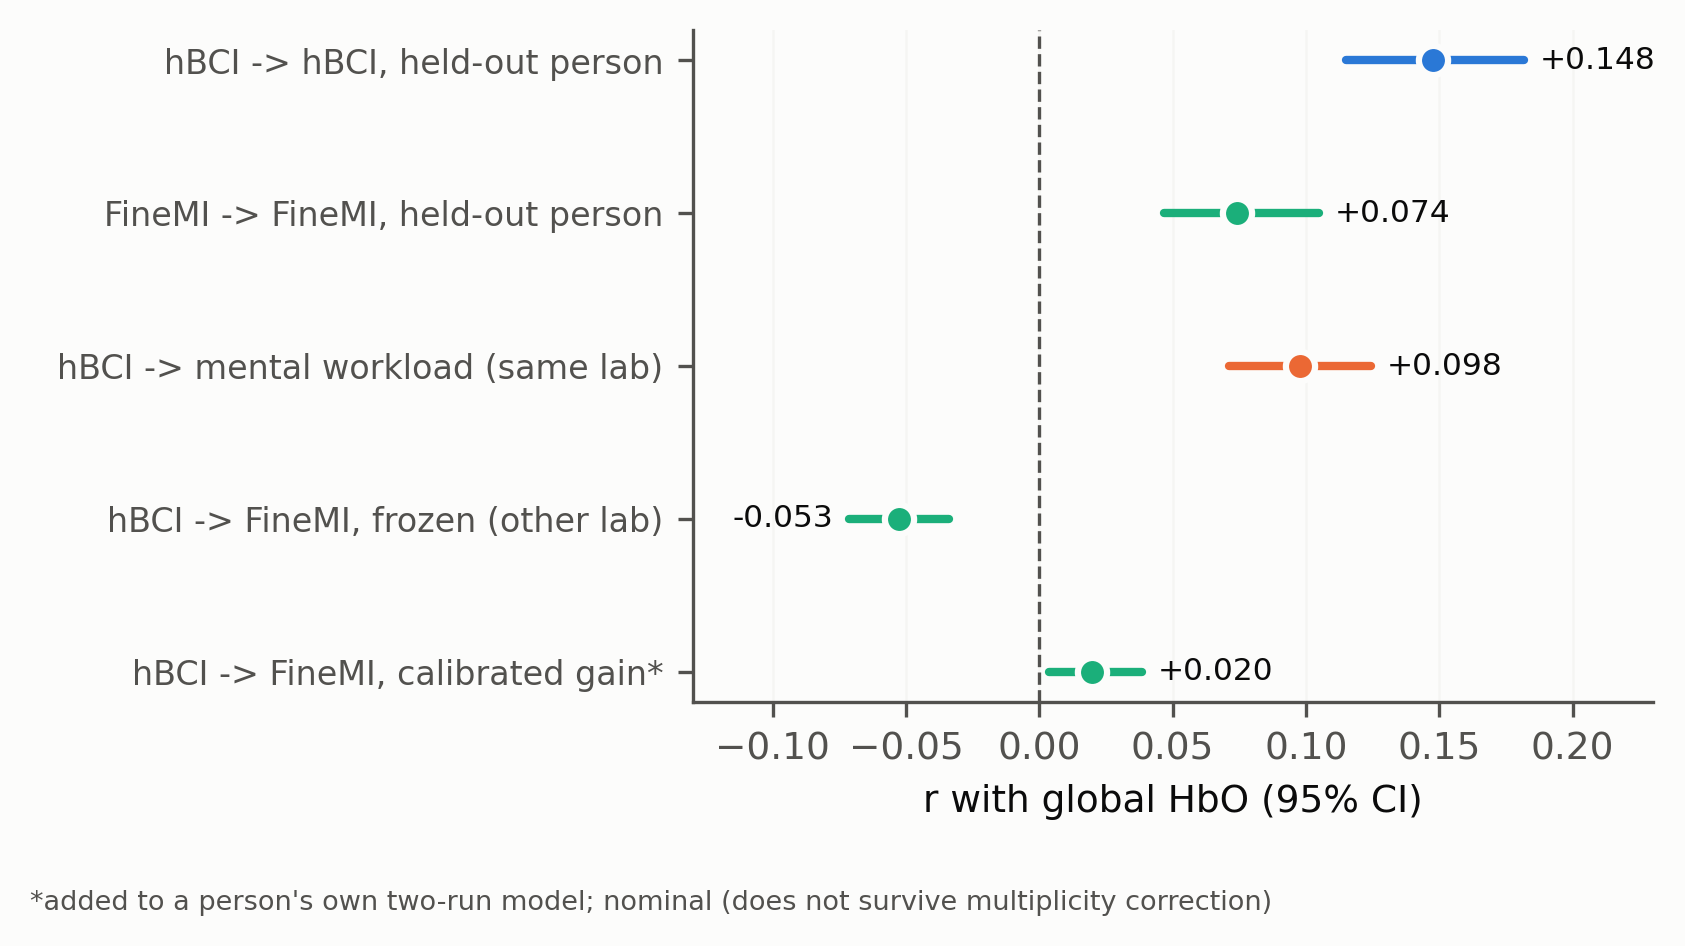

In [41]:
d = J("nvc_bands_results.json")
table([[k.replace("hbci_to_", "hBCI → "), f"{v['mean_r']:+.3f}", ci(*v["ci"]), f"{v['frac_beating_null']:.0%}", "pass" if v["pass"] else "fail"] for k, v in d.items() if k.startswith("hbci_to_")] +
      [["FineMI leave one person out", f"{d['lopo | finemi']['mean_r']:+.3f}", ci(*d["lopo | finemi"]["ci"]), f"{d['lopo | finemi']['frac_beating_null']:.0%}", "pass" if d["lopo | finemi"]["pass"] else "fail"]],
      ["Kernel", "r", "95% CI", "Beat null", "Rule"])
table([[k.split(" | ")[1], f"{v['diff']:+.3f}", ci(*v["ci"]), f"{v['n_better']}/{v['n']}", "pass" if v["pass"] else "fail"] for k, v in d.items() if k.startswith("calibrated")], ["Calibrated alpha + beta", "Gain", "95% CI", "People better", "Rule"])
def draw_fig4():
    tr = RJ("nvc_transfer_results.json")
    bd = RJ("nvc_bands_results.json")
    t2 = RJ("nvc_transfer2_results.json")
    lopo_h = tr["within_hbci_lopo"]
    lh_ci = lopo_h["ci"] if "ci" in lopo_h else boot_ci([q["r"] for q in lopo_h["people"].values()]) if "people" in lopo_h else [np.nan] * 2
    rows = [("hBCI -> hBCI, held-out person", lopo_h["mean_r"], lh_ci, "hbci"),
            ("FineMI -> FineMI, held-out person", bd["lopo | finemi"]["mean_r"], bd["lopo | finemi"]["ci"], "finemi"),
            ("hBCI -> mental workload (same lab)", tr["hbci_to_mental_workload"]["mean_r"], tr["hbci_to_mental_workload"]["ci"], "mental_workload"),
            ("hBCI -> FineMI, frozen (other lab)", tr["hbci_to_finemi"]["mean_r"], tr["hbci_to_finemi"]["ci"], "finemi"),
            ("hBCI -> FineMI, calibrated gain*", t2["calibrated | finemi"]["diff"], t2["calibrated | finemi"]["ci"], "finemi")]
    fig, ax = plt.subplots(figsize=(5.6, 3.1))
    for i, (lab, m, ci, c) in enumerate(rows[::-1]):
        col = FIG_COH[c][1]
        ax.plot(ci, [i, i], color=col, lw=2, solid_capstyle="round")
        ax.plot(m, i, "o", ms=7, color=col, mec=SURF, mew=1.5)
        if m < 0:
            ax.text(ci[0] - 0.006, i, f"{m:+.3f}", va="center", ha="right", fontsize=7.5, color=INK)
        else:
            ax.text(ci[1] + 0.006, i, f"{m:+.3f}", va="center", fontsize=7.5, color=INK)
    ax.axvline(0, color=INK2, lw=0.8, ls="--")
    ax.set_yticks(range(len(rows)), [r[0] for r in rows[::-1]], fontsize=8)
    ax.set_xlabel("r with global HbO (95% CI)")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(-0.13, 0.23)
    fig.text(0.01, 0.01, "*added to a person's own two-run model; nominal (does not survive multiplicity correction)",
             fontsize=6.5, color=INK2)
    save(fig, "fig4_kernel_transfer")


draw_fig4()
fig("fig4_kernel_transfer", 560)

Diagnostic: the FineMI kernel applied to TU Berlin data, and the correlation of overall EEG power with global HbO in each cohort. Output: `nvc_labdiff_results.json`. Rerun name: `nvc_labdiff`.

In [42]:
def nvc_labdiff(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    from pathlib import Path

    HERE = NB_OUT
    NSB = nvc_bands(LIB=True)

    import json

    import numpy as np

    load, score, show, fit, NF, LAGS, SEED = (NSB[k] for k in ("load", "score", "show", "fit", "NF", "LAGS", "SEED"))
    OUT = HERE / "nvc_labdiff_results.json"

    def broadband(people, rng):
        per = {}
        for pid, runs in people.items():
            rs = []
            for X, ys in runs:
                y = ys["hbo"]
                for li in range(len(LAGS)):
                    b = X[:, li * NF:(li + 1) * NF].mean(1)
                    rs.append(float(np.corrcoef(b, y)[0, 1]))
            per[pid] = float(np.mean(rs))
        v = np.array(list(per.values()))
        boot = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(5000)]
        return {"mean_r": float(v.mean()), "ci": [float(x) for x in np.percentile(boot, [2.5, 97.5])],
                "n_positive": int(np.sum(v > 0)), "n": len(v), "people": per}

    rng = np.random.default_rng(SEED)
    res = {}
    F = load("finemi")
    fk = fit(F)
    res["broadband | finemi"] = broadband(F, rng)
    del F
    for cohort in ("hbci", "mental_workload"):
        P = load(cohort)
        res[f"finemi_to_{cohort}"] = score(fk, P, "hbo", rng)
        show(f"P9.4a FineMI kernel -> {cohort}", res[f"finemi_to_{cohort}"])
        res[f"broadband | {cohort}"] = broadband(P, rng)
        del P
        OUT.write_text(json.dumps(res, indent=1))
    for c in ("hbci", "mental_workload", "finemi"):
        b = res[f"broadband | {c}"]
        print(f"== P9.4b broadband power vs global HbO, {c}: mean r {b['mean_r']:+.4f} [{b['ci'][0]:+.4f}, {b['ci'][1]:+.4f}] "
              f"({b['n_positive']}/{b['n']} > 0)", flush=True)
    OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"nvc_labdiff"} in section 2
if should("nvc_labdiff"):
    nvc_labdiff()

**Result.** The kernel flip in the reverse direction, and overall EEG power against global HbO.

In [43]:
d = J("nvc_labdiff_results.json")
table([[k.replace("_to_", " → "), f"{v['mean_r']:+.3f}", ci(*v["ci"]), f"{v['n_positive']}/{v['n']}"] for k, v in d.items() if "_to_" in k] +
      [[f"Overall EEG power vs global HbO, {COH[c]}", f"{d['broadband | ' + c]['mean_r']:+.3f}", ci(*d["broadband | " + c]["ci"]), f"{d['broadband | ' + c]['n_positive']}/{d['broadband | ' + c]['n']}"] for c in COH],
      ["Test", "r", "95% CI", "People with r > 0"])

Test,r,95% CI,People with r > 0
finemi → hbci,-0.029,"[-0.056, -0.000]",10/29
finemi → mental_workload,-0.021,"[-0.060, +0.019]",10/26
"Overall EEG power vs global HbO, hBCI",-0.038,"[-0.055, -0.022]",5/29
"Overall EEG power vs global HbO, Mental workload",-0.035,"[-0.077, +0.008]",9/26
"Overall EEG power vs global HbO, FineMI",+0.044,"[+0.023, +0.067]",15/18


Tests whether the overall EEG power term causes the sign flip, by refitting the kernel with that term removed and with that term alone. Output: `nvc_broadband_results.json`. Rerun name: `nvc_broadband`.

In [44]:
def nvc_broadband(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    from pathlib import Path

    HERE = NB_OUT
    NSB = nvc_bands(LIB=True)

    import json

    import numpy as np
    from sklearn.linear_model import RidgeCV

    load, score, calibrated, show, show_cal = (NSB[k] for k in ("load", "score", "calibrated", "show", "show_cal"))
    NF, LAGS, SEED, ALPHAS = (NSB[k] for k in ("NF", "LAGS", "SEED", "ALPHAS"))
    OUT = HERE / "nvc_broadband_results.json"
    NL = len(LAGS)

    def same(X):
        return X

    def removed(X):
        X = X.copy()
        for i in range(NL):
            b = X[:, i * NF:(i + 1) * NF]
            b -= b.mean(1, keepdims=True)
        return X

    def only(X):
        return np.stack([X[:, i * NF:(i + 1) * NF].mean(1) for i in range(NL)], 1)

    class Wrapped:
        def __init__(self, f, m):
            self.f, self.m = f, m

        def predict(self, X):
            return self.m.predict(self.f(X))

    def fit(people, f):
        X = np.concatenate([f(x) for runs in people.values() for x, _ in runs])
        y = np.concatenate([ys["hbo"] for runs in people.values() for _, ys in runs])
        return Wrapped(f, RidgeCV(alphas=ALPHAS).fit(X, y))

    def signflip(d, rng, n=200000):
        d = np.asarray(d)
        return float((np.sum((rng.choice([-1, 1], size=(n, len(d))) * d).mean(1) >= d.mean()) + 1) / (n + 1))

    rng = np.random.default_rng(SEED)
    res = {}
    H = load("hbci")
    K = {"all": fit(H, same), "removed": fit(H, removed), "only": fit(H, only)}
    del H
    for cohort in ("mental_workload", "finemi"):
        P = load(cohort)
        s = {}
        for name, m in K.items():
            s[name] = score(m, P, "hbo", rng)
            res[f"hbci_to_{cohort} | {name}"] = s[name]
            show(f"hBCI [{name}] -> {cohort}", s[name])
        d = np.array([s["removed"]["people"][p]["r"] - s["all"]["people"][p]["r"] for p in s["all"]["people"]])
        ci = [float(x) for x in np.percentile([d[rng.integers(0, len(d), len(d))].mean() for _ in range(5000)], [2.5, 97.5])]
        pf = signflip([q["r"] for q in s["removed"]["people"].values()], rng)
        res[f"paired removed-all | {cohort}"] = {"diff": float(d.mean()), "ci": ci, "signflip_p_removed": pf}
        print(f"== paired removed - all, {cohort}: {d.mean():+.4f} [{ci[0]:+.4f}, {ci[1]:+.4f}]; sign-flip p of removed {pf:.5f}", flush=True)
        c = calibrated(K["removed"], P, np.random.default_rng(SEED))
        show_cal(f"calibrated removed -> {cohort}", c)
        c["signflip_p"] = signflip([q["personal_plus_external"] - q["personal"] for q in c["people"].values()], rng)
        res[f"calibrated | {cohort} | removed"] = c
        print(f"== calibrated sign-flip p, {cohort}: {c['signflip_p']:.5f}", flush=True)
        del P
        OUT.write_text(json.dumps(res, indent=1))
    f, o, pr = res["hbci_to_finemi | removed"], res["hbci_to_finemi | only"], res["paired removed-all | finemi"]
    sup = bool(pr["ci"][0] > 0 and f["ci"][1] >= 0 and o["mean_r"] < 0 and o["ci"][1] < 0)
    print("P10.1 broadband explanation:", "SUPPORTED" if sup else "NOT SUPPORTED")
    print("P10.1 Claim 2 primary (frozen removed -> FineMI):", "PASS" if f["pass"] else "FAIL")
    print("DONE")


# RERUN: set RUN = {"nvc_broadband"} in section 2
if should("nvc_broadband"):
    nvc_broadband()

**Result.** Removing the broadband term shrinks the FineMI flip but does not remove it.

In [45]:
d = J("nvc_broadband_results.json")
table([[k.split(" | ")[0].replace("hbci_to_", "hBCI → "), k.split(" | ")[1], f"{d[k]['mean_r']:+.3f}", ci(*d[k]["ci"]), f"{d[k]['frac_beating_null']:.0%}", "pass" if d[k]["pass"] else "fail"] for k in d if k.startswith("hbci_to_")], ["Direction", "Kernel", "r", "95% CI", "Beat null", "Rule"])
table([[k, f"{v['diff']:+.3f}", ci(*v["ci"]), f"{v.get('signflip_p', v.get('signflip_p_removed')):.4f}"] for k, v in d.items() if k.startswith(("paired", "calibrated"))], ["Test", "Difference", "95% CI", "Sign-flip p"])

Direction,Kernel,r,95% CI,Beat null,Rule
hBCI → mental_workload,all,+0.098,"[+0.071, +0.124]",54%,pass
hBCI → mental_workload,removed,+0.073,"[+0.041, +0.104]",42%,fail
hBCI → mental_workload,only,+0.087,"[+0.035, +0.134]",46%,fail
hBCI → finemi,all,-0.053,"[-0.071, -0.034]",0%,fail
hBCI → finemi,removed,-0.036,"[-0.053, -0.021]",0%,fail
hBCI → finemi,only,-0.053,"[-0.074, -0.031]",6%,fail


Test,Difference,95% CI,Sign-flip p
paired removed-all | mental_workload,-0.025,"[-0.041, -0.007]",0.0001
calibrated | mental_workload | removed,+0.034,"[-0.001, +0.076]",0.0518
paired removed-all | finemi,+0.017,"[+0.007, +0.027]",1.0000
calibrated | finemi | removed,+0.008,"[-0.004, +0.021]",0.1162


## 12. Claim 3: coupling and delay

Claim 3 beyond the task. The coupling analysis repeated after removing the cue-locked average response, so a shared task response cannot explain it. Output: `nvc_residual_results.json`. Rerun name: `nvc_residual`.

In [46]:
def nvc_residual(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os
    import sys
    from pathlib import Path

    HERE = NB_OUT
    ns = nvc_bandpower(LIB=True)

    import json

    import numpy as np
    import scipy.io as sio
    from scipy.stats import pearsonr, wilcoxon

    person, run_pair_bp, LAGS, SEED, BANDS = ns["person"], ns["run_pair_bp"], ns["LAGS"], ns["SEED"], ns["BANDS"]
    inner = ns["ns"]
    _runs, beer_lambert, split_wl, HBCI, MW = inner["_runs"], inner["beer_lambert"], inner["split_wl"], inner["HBCI"], inner["MW"]
    EOG = inner["EOG"]
    COHORTS_ENV = os.environ.get("COHORTS", "hbci,mental_workload,finemi").split(",")
    OUT = HERE / "nvc_residual_results.json"
    SHARDP = "nvc_res_smoke" if os.environ.get("SMOKE") else "nvc_res_shard"
    NFIR = 30

    def residualise(E, H, cues):
        """Remove the pooled cue-locked FIR response (0..NFIR-1 s) + intercept from every column of E and H."""
        T = len(E)
        X = np.zeros((T, NFIR + 1))
        X[:, -1] = 1.0
        for c in cues:
            for l in range(NFIR):
                if 0 <= c + l < T:
                    X[c + l, l] += 1.0
        Z = np.hstack([E, H])
        beta = np.linalg.lstsq(X, Z, rcond=None)[0]
        R = Z - X @ beta
        return R[:, :E.shape[1]], R[:, E.shape[1]:]

    def with_cues(pr, cues_s, start_s):
        """pr = (E, H) from run_pair_bp; cue times in EEG seconds; start_s = EEG time of E[0]."""
        if pr is None:
            return None
        idx = [int(round(t - start_s)) for t in cues_s]
        return residualise(pr[0], pr[1], [i for i in idx if -NFIR < i < len(pr[0])])

    def hbci_people():
        eeg_dir, nirs_dir = HBCI / "EEG data", HBCI / "NRI data" / "NIRS_01-29"
        for s in range(1, 30):
            ed = next((g / f"subject {s:02d}" / "with occular artifact" for g in sorted(eeg_dir.glob("EEG_*"))
                       if (g / f"subject {s:02d}" / "with occular artifact").exists()), None)
            er_all, em_all = _runs(ed / "cnt.mat", "cnt"), _runs(ed / "mrk.mat", "mrk")
            nr_all, nm_all = _runs(nirs_dir / f"subject {s:02d}" / "cnt.mat", "cnt"), \
                _runs(nirs_dir / f"subject {s:02d}" / "mrk.mat", "mrk")
            pairs = []
            for r in range(min(er_all.size, nr_all.size, em_all.size, nm_all.size)):
                er, nr, em, nm = er_all[r], nr_all[r], em_all[r], nm_all[r]
                clab = [str(c) for c in np.atleast_1d(er.clab)]
                keep = [i for i, c in enumerate(clab) if c not in EOG]
                ex = np.asarray(er.x, float)[:, keep].T
                lo, hi = split_wl(np.asarray(nr.x, float), nr.clab)
                hbo, _ = beer_lambert(lo, hi)
                off = float(np.atleast_1d(nm.time)[0] - np.atleast_1d(em.time)[0]) / 1000.0
                pr = run_pair_bp(ex, float(np.atleast_1d(er.fs).ravel()[0]), np.asarray(hbo, float),
                                 float(np.atleast_1d(nr.fs).ravel()[0]), off)
                a0 = max(0, -int(round(off)))
                pr = with_cues(pr, np.atleast_1d(em.time).astype(float) / 1000.0, a0)
                if pr is not None:
                    pairs.append(pr)
            yield f"hbci_s{s:02d}", pairs

    def mw_people():
        L = lambda p, k: sio.loadmat(p, squeeze_me=True, struct_as_record=False)[k]
        for s in range(1, 27):
            vp = f"VP{s:03d}"
            ce, me = L(MW / "EEG" / f"{vp}-EEG" / "cnt_nback.mat", "cnt_nback"), L(MW / "EEG" / f"{vp}-EEG" / "mrk_nback.mat", "mrk_nback")
            cn, mn = L(MW / "NIRS" / f"{vp}-NIRS" / "cnt_nback.mat", "cnt_nback"), L(MW / "NIRS" / f"{vp}-NIRS" / "mrk_nback.mat", "mrk_nback")
            names = [str(c) for c in np.atleast_1d(me.className)]
            ye = np.asarray(me.y)
            sess = [i for i, c in enumerate(names) if "session" in c]
            te = np.asarray(me.time, float)[ye[sess].sum(0) > 0] / 1000.0
            tn = np.asarray(mn.time, float) / 1000.0
            off = tn - te
            run = np.concatenate([[0], np.cumsum(np.abs(np.diff(off)) > 1.0)])
            clab = [str(c) for c in np.atleast_1d(ce.clab)]
            keep = [i for i, c in enumerate(clab) if c not in EOG]
            ex = np.asarray(ce.x, float)[:, keep].T
            hbo = np.asarray(cn.oxy.x, float).T
            e_fs, n_fs = float(ce.fs), float(cn.oxy.fs)
            pairs = []
            for r in np.unique(run):
                m = run == r
                a, b = te[m].min() - 20.0, te[m].max() + 60.0
                ia, ib = max(0, int(a * e_fs)), min(ex.shape[1], int(b * e_fs))
                o = float(np.median(off[m]))
                na, nb_ = max(0, int((a + o) * n_fs)), min(hbo.shape[1], int((b + o) * n_fs))
                seg_e, seg_n = ex[:, ia:ib], hbo[:, na:nb_]
                n = min(seg_e.shape[1] / e_fs, seg_n.shape[1] / n_fs)
                pr = run_pair_bp(seg_e[:, :int(n * e_fs)], e_fs, seg_n[:, :int(n * n_fs)], n_fs, 0.0)
                pr = with_cues(pr, te[m], ia / e_fs)
                if pr is not None:
                    pairs.append(pr)
            yield f"mw_{vp}", pairs

    def finemi_people():
        import mne
        mne.set_log_level("ERROR")
        root = Path(f"{PROJECT_ROOT}/dataset/Multi-joint Upper-Limb EEG+FNIR/FineMI/FineMI")
        drop = {"M1", "M2", "CB1", "CB2", "EKG", "EMG", "HEO", "VEO"}

        def events(raw):
            a = raw.annotations
            keep = [i for i, d in enumerate(a.description) if d.replace(".0", "").strip().isdigit()]
            return np.asarray(a.onset)[keep], [int(float(a.description[i])) for i in keep]

        for s in sorted(int(p.name[7:]) for p in root.glob("subject*") if p.is_dir()):
            pairs = []
            for name in sorted(p.stem for p in (root / f"subject{s}" / "EEG").glob("*.cnt")):
                try:
                    e = mne.io.read_raw_cnt(root / f"subject{s}" / "EEG" / f"{name}.cnt", preload=True)
                    te, le = events(e)
                    e.pick([c for c in e.ch_names if c not in drop])
                    e.resample(200.0, npad="auto")
                    x = e.get_data()
                    n = mne.io.read_raw_nirx(root / f"subject{s}" / "fNIRS" / name, preload=True)
                    tn, ln = events(n)
                    hb = mne.preprocessing.nirs.beer_lambert_law(mne.preprocessing.nirs.optical_density(n), ppf=6.0)
                    hbo = hb.get_data(picks=[i for i, c in enumerate(hb.ch_names) if c.endswith("hbo")])
                    n_fs = float(n.info["sfreq"])
                except Exception as exc:
                    print(f"finemi s{s} {name}: unreadable {type(exc).__name__}"); continue
                if le != ln:
                    continue
                run = np.concatenate([[0], np.cumsum(np.diff(te) > 40.0)])
                off = tn - te
                for r in np.unique(run):
                    m = run == r
                    if np.ptp(off[m]) > 1.0:
                        continue
                    o = float(np.median(off[m]))
                    a, bb = max(0.0, te[m].min() - 20.0), te[m].max() + 60.0
                    ia, ib = int(a * 200), min(x.shape[1], int(bb * 200))
                    na, nb_ = max(0, int((a + o) * n_fs)), min(hbo.shape[1], int((bb + o) * n_fs))
                    n_s = min((ib - ia) / 200.0, (nb_ - na) / n_fs)
                    pr = run_pair_bp(x[:, ia:ia + int(n_s * 200)], 200.0, hbo[:, na:na + int(n_s * n_fs)], n_fs, 0.0)
                    pr = with_cues(pr, te[m], ia / 200.0)
                    if pr is not None:
                        pairs.append(pr)
                del x, e, n, hb
            yield f"finemi_s{s:02d}", pairs

    GENS = {"hbci": hbci_people, "mental_workload": mw_people, "finemi": finemi_people}
    if LIB:
        return locals()

    if MODE in ("shard", "all"):
        k, n = SHARD
        sf = HERE / f"{SHARDP}_{k}_of_{n}.json"
        done = json.loads(sf.read_text()) if sf.exists() else {}
        for cohort in COHORTS_ENV:
            ci = ("hbci", "mental_workload", "finemi").index(cohort)
            for pi, (pid, pairs) in enumerate(GENS[cohort]()):
                if (ci * 100 + pi) % n != k or pid in done:
                    continue
                if len(pairs) < 2:
                    print(pid, "fewer than 2 usable runs"); continue
                v = person(pairs, np.random.default_rng([SEED, ci, pi]))
                done[pid] = dict(v, cohort=cohort)
                print(f"RES {pid}: local delay {v['delay_s']:+d} s r {v['peak_r']:.3f} p {v['p_null']:.3f} halves {v['half_delays_s']} "
                      f"| global delay {v['delay_global_s']:+d} s r {v['peak_r_global']:.3f}", flush=True)
                sf.write_text(json.dumps(done, indent=1))
        if MODE == "shard":
            print("SHARD DONE"); return

    allp = {}
    for f in sorted(HERE.glob(f"{SHARDP}_*_of_*.json")):
        allp.update(json.loads(f.read_text()))
    rng = np.random.default_rng(SEED)
    res = {}
    for cohort in ("hbci", "mental_workload", "finemi"):
        people = {p: v for p, v in allp.items() if v["cohort"] == cohort}
        if not people:
            continue
        d = np.array([v["delay_s"] for v in people.values()])
        h = np.array([v["half_delays_s"] for v in people.values()], float)
        ps = np.array([v["p_null"] for v in people.values()])
        r_half = float(pearsonr(h[:, 0], h[:, 1])[0]) if h[:, 0].std() > 0 and h[:, 1].std() > 0 else 0.0
        perm = np.array([pearsonr(h[:, 0], rng.permutation(h[:, 1]))[0] for _ in range(10000)])
        p_half = float((np.sum(perm >= r_half) + 1) / 10001)
        try:
            w = float(wilcoxon(d).pvalue) if np.any(d != 0) else 1.0
        except ValueError:
            w = 1.0
        exists = float(np.mean(ps < 0.05)) > 0.5
        reproducible = r_half > 0 and p_half < 0.05
        physio = bool(2 <= np.median(d) <= 10 and w < 0.05)
        res[cohort] = {"people": people, "n": len(people), "frac_beating_null": float(np.mean(ps < 0.05)),
                       "median_delay_s": float(np.median(d)), "iqr_delay_s": [float(x) for x in np.percentile(d, [25, 75])],
                       "wilcoxon_p": w, "split_half_r": r_half, "split_half_perm_p": p_half,
                       "half_estimates_at_edge": int(np.sum(np.isin(h, [LAGS[0], LAGS[-1]]))),
                       "median_peak_r": float(np.median([v["peak_r"] for v in people.values()])),
                       "median_global_delay_s": float(np.median([v["delay_global_s"] for v in people.values()])),
                       "band_share": {b[0]: float(np.mean([v["band_share"][b[0]] for v in people.values()])) for b in BANDS},
                       "exists": bool(exists), "reproducible": bool(reproducible),
                       "claim3a_pass": bool(exists and reproducible), "physiological": physio}
        r = res[cohort]
        print(f"== RES {cohort}: n {r['n']}, beat null {r['frac_beating_null']:.2f}, median delay {r['median_delay_s']:+.1f} s "
              f"IQR {r['iqr_delay_s']} Wilcoxon p {w:.4f}; split-half r {r_half:+.3f} (perm p {p_half:.4f}, "
              f"{r['half_estimates_at_edge']} at edge); median peak r {r['median_peak_r']:.3f} -> Claim 3a "
              f"{'PASS' if r['claim3a_pass'] else 'FAIL'}, physiological {'YES' if physio else 'NO'}", flush=True)
    res["coupling_beyond_task_supported"] = bool(res.get("hbci", {}).get("claim3a_pass") and any(
        res.get(c, {}).get("claim3a_pass") for c in ("mental_workload", "finemi")))
    print("Coupling beyond the task:", "SUPPORTED" if res["coupling_beyond_task_supported"] else "NOT SUPPORTED")
    OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"nvc_residual"} in section 2
if should("nvc_residual"):
    nvc_residual()

**Result.** Coupling after the cue-locked task response is removed.

In [47]:
d = J("nvc_residual_results.json")
table([[COH[c], f"{d[c]['frac_beating_null']:.0%}", f"{d[c]['median_delay_s']:+.1f} s", f"{d[c]['split_half_r']:+.2f}", f"{d[c]['split_half_perm_p']:.3f}", f"{d[c]['median_peak_r']:.3f}"] for c in COH], ["Cohort", "Beat null", "Median delay", "Split-half r", "p", "Peak local r"])

Cohort,Beat null,Median delay,Split-half r,p,Peak local r
hBCI,100%,+6.0 s,+0.33,0.041,0.164
Mental workload,85%,+2.0 s,-0.10,0.701,0.094
FineMI,83%,+1.5 s,+0.22,0.179,0.061


Claim 3. Does a person's coupling curve in the first half of the recording match the second half, more than after time-shifting? The second call uses the task-removed data. Output: `nvc_kernel_results.json`, `nvc_kernel_resid_results.json`. Rerun name: `nvc_kernel`.

In [48]:
def nvc_kernel(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os
    import sys
    from pathlib import Path

    HERE = NB_OUT
    RESID = os.environ.get("RESID") == "1"
    ns = nvc_residual(LIB=True) if RESID else nvc_bandpower(LIB=True)

    import json

    import numpy as np
    from scipy.stats import pearsonr, wilcoxon

    base = ns["ns"] if RESID else ns
    curve, LAGS, SEED, GENS = base["curve"], base["LAGS"], base["SEED"], ns["GENS"]
    NK, MINSHIFT = int(os.environ.get("NK", "20")), 60
    COHORTS_ENV = os.environ.get("COHORTS", "hbci,mental_workload,finemi").split(",")
    TAG = "_resid" if RESID else ""
    OUT = HERE / f"nvc_kernel{TAG}_results.json"
    SHARDP = f"nvc_kernel{TAG}_smoke" if os.environ.get("SMOKE") else f"nvc_kernel{TAG}_shard"

    def halves(pairs):
        a, b = [], []
        for E, H in pairs:
            n = len(E) // 2
            a.append((E[:n], H[:n]))
            b.append((E[n:], H[n:]))
        return a, b

    def person(pairs, rng):
        ha, hb = halves(pairs)
        ca, cb = curve(ha, "local"), curve(hb, "local")
        k = float(pearsonr(ca, cb)[0])
        kn = []
        for _ in range(NK):
            sp = [(E, np.roll(H, rng.integers(MINSHIFT, max(MINSHIFT + 1, len(H) - MINSHIFT)), axis=0)) for E, H in hb]
            kn.append(float(pearsonr(ca, curve(sp, "local"))[0]))
        return {"k": k, "k_null": kn, "d": k - float(np.mean(kn)),
                "p_person": float((np.sum(np.array(kn) >= k) + 1) / (NK + 1)),
                "delay_A_s": int(LAGS[np.argmax(ca)]), "delay_B_s": int(LAGS[np.argmax(cb)]),
                "curve_A": ca.round(4).tolist(), "curve_B": cb.round(4).tolist(), "n_runs": len(pairs)}

    if MODE in ("shard", "all"):
        k_, n_ = SHARD
        sf = HERE / f"{SHARDP}_{k_}_of_{n_}.json"
        done = json.loads(sf.read_text()) if sf.exists() else {}
        for cohort in COHORTS_ENV:
            ci = ("hbci", "mental_workload", "finemi").index(cohort)
            for pi, (pid, pairs) in enumerate(GENS[cohort]()):
                if (ci * 100 + pi) % n_ != k_ or pid in done:
                    continue
                if len(pairs) < 2:
                    print(pid, "fewer than 2 usable runs"); continue
                v = person(pairs, np.random.default_rng([SEED, ci, pi, 7]))
                done[pid] = dict(v, cohort=cohort)
                print(f"{pid}: k {v['k']:+.3f} null {np.mean(v['k_null']):+.3f} d {v['d']:+.3f} p {v['p_person']:.3f} "
                      f"delays {v['delay_A_s']:+d}/{v['delay_B_s']:+d}", flush=True)
                sf.write_text(json.dumps(done, indent=1))
        if MODE == "shard":
            print("SHARD DONE"); return

    allp = {}
    for f in sorted(HERE.glob(f"{SHARDP}_*_of_*.json")):
        allp.update(json.loads(f.read_text()))
    p64 = json.loads((HERE / ("nvc_residual_results.json" if RESID else "nvc_bandpower_results.json")).read_text())
    rng = np.random.default_rng(SEED)
    res = {}
    for cohort in ("hbci", "mental_workload", "finemi"):
        people = {p: v for p, v in allp.items() if v["cohort"] == cohort}
        if not people:
            continue
        d = np.array([v["d"] for v in people.values()])
        try:
            w = float(wilcoxon(d, alternative="greater").pvalue)
        except ValueError:
            w = 1.0
        dA = np.array([v["delay_A_s"] for v in people.values()])
        dB = np.array([v["delay_B_s"] for v in people.values()])
        agree = float(np.mean(np.abs(dA - dB) <= 2))
        chance = float(np.mean([np.mean(np.abs(dA[i] - np.delete(dB, i)) <= 2) for i in range(len(dA))]))
        exists = bool(p64[cohort]["frac_beating_null"] > 0.5)
        repro = bool(np.median(d) > 0 and w < 0.05)
        res[cohort] = {"people": people, "n": len(people), "median_k": float(np.median([v["k"] for v in people.values()])),
                       "median_k_null": float(np.median([np.mean(v["k_null"]) for v in people.values()])),
                       "median_d": float(np.median(d)), "wilcoxon_p_greater": w,
                       "frac_person_p05": float(np.mean([v["p_person"] < 0.05 for v in people.values()])),
                       "delay_agree_2s": agree, "delay_agree_2s_chance": chance,
                       "exists_p64": exists, "kernel_reproducible": repro, "claim3a_kernel_pass": bool(exists and repro)}
        r = res[cohort]
        print(f"== KERNEL{TAG} {cohort}: n {r['n']}, median k {r['median_k']:+.3f} vs null {r['median_k_null']:+.3f}, "
              f"median d {r['median_d']:+.3f}, Wilcoxon p {w:.4f}, {r['frac_person_p05']:.2f} of people p<0.05; "
              f"delays within 2 s {agree:.2f} (chance {chance:.2f}) -> exists {exists}, reproducible {repro} "
              f"-> 3a' {'PASS' if r['claim3a_kernel_pass'] else 'FAIL'}", flush=True)
    res["claim3_kernel_supported"] = bool(res.get("hbci", {}).get("claim3a_kernel_pass") and any(
        res.get(c, {}).get("claim3a_kernel_pass") for c in ("mental_workload", "finemi")))
    print(f"Claim 3 (kernel form{', beyond the task' if RESID else ''}):",
          "SUPPORTED" if res["claim3_kernel_supported"] else "NOT SUPPORTED")
    OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"nvc_kernel"} in section 2
if should("nvc_kernel"):
    nvc_kernel()
    run_with_env(nvc_kernel, RESID="1")

**Result and Figure 3.** Does a person's coupling curve repeat between the two halves of the recording?

Cohort,Data,Median half-to-half r,Shifted null,Difference,Wilcoxon p,Reproducible
hBCI,raw,+0.753,-0.015,+0.776,5.6e-09,yes
hBCI,task removed,+0.740,-0.034,+0.744,4.7e-08,yes
Mental workload,raw,+0.179,+0.042,+0.101,9.1e-02,no
Mental workload,task removed,+0.227,+0.003,+0.224,6.0e-03,yes
FineMI,raw,+0.205,-0.031,+0.191,3.3e-02,yes
FineMI,task removed,+0.277,-0.012,+0.238,9.7e-04,yes


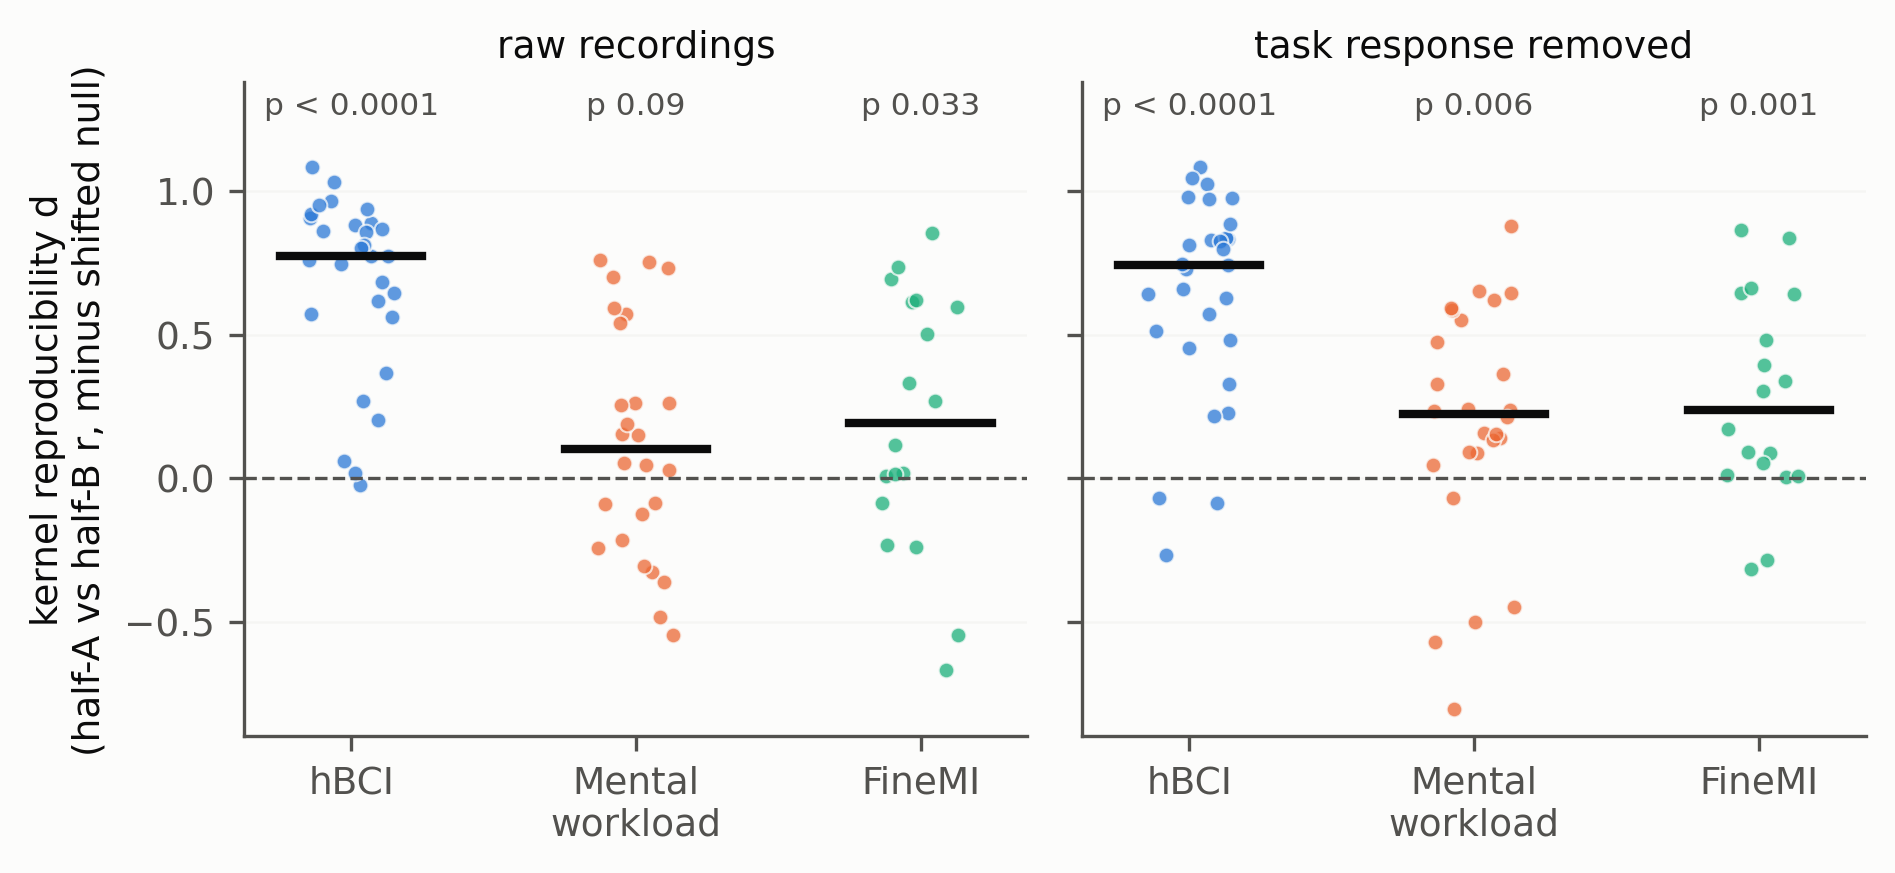

In [49]:
kr, kt = J("nvc_kernel_results.json"), J("nvc_kernel_resid_results.json")
table([[COH[c], label, f"{d[c]['median_k']:+.3f}", f"{d[c]['median_k_null']:+.3f}", f"{d[c]['median_d']:+.3f}", f"{d[c]['wilcoxon_p_greater']:.1e}", "yes" if d[c]["kernel_reproducible"] else "no"] for c in COH for label, d in (("raw", kr), ("task removed", kt))],
      ["Cohort", "Data", "Median half-to-half r", "Shifted null", "Difference", "Wilcoxon p", "Reproducible"])
def draw_fig3():
    fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.0), sharey=True)
    pvals = {("", "hbci"): "p < 0.0001", ("", "mental_workload"): "p 0.09", ("", "finemi"): "p 0.033",
             ("_resid", "hbci"): "p < 0.0001", ("_resid", "mental_workload"): "p 0.006", ("_resid", "finemi"): "p 0.001"}
    rng = np.random.default_rng(0)
    for ax, (tag, title) in zip(axes, (("", "raw recordings"), ("_resid", "task response removed"))):
        K = shards(f"nvc_kernel{tag}_shard_*_of_*.json")
        for i, (c, (lab, col)) in enumerate(FIG_COH.items()):
            d = np.array([v["d"] for v in K.values() if v["cohort"] == c])
            ax.scatter(i + rng.uniform(-0.15, 0.15, len(d)), d, s=14, color=col, alpha=0.75, edgecolors=SURF, linewidths=0.5)
            ax.plot([i - 0.25, i + 0.25], [np.median(d)] * 2, color=INK, lw=2)
            ax.text(i, 1.27, pvals[(tag, c)], ha="center", fontsize=7.5, color=INK2)
        ax.axhline(0, color=INK2, lw=0.8, ls="--")
        ax.set_xticks(range(3), ["hBCI", "Mental\nworkload", "FineMI"])
        ax.set_title(title, fontsize=9, color=INK)
        ax.grid(axis="x", visible=False)
        ax.set_ylim(-0.9, 1.38)
    axes[0].set_ylabel("kernel reproducibility d\n(half-A vs half-B r, minus shifted null)")
    save(fig, "fig3_kernel_repro")


draw_fig3()
fig("fig3_kernel_repro", 640)

Claim 3. Personal delay taken from smoothed half-recording curves, and how often the two halves agree within 2 s. Needs the output of `nvc_kernel`. Output: `nvc_delay_smooth_results.json`. Rerun name: `nvc_delay_smooth`.

In [50]:
def nvc_delay_smooth(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import json
    from pathlib import Path

    import numpy as np
    from scipy.stats import pearsonr

    HERE = NB_OUT
    LAGS = np.arange(-10, 21)
    OUT = HERE / "nvc_delay_smooth_results.json"

    def smooth(c, w=5):
        c = np.asarray(c, float)
        h = w // 2
        return np.array([c[max(0, i - h):i + h + 1].mean() for i in range(len(c))])

    def stats(people, rng):
        dA = np.array([LAGS[np.argmax(smooth(v["curve_A"]))] for v in people.values()])
        dB = np.array([LAGS[np.argmax(smooth(v["curve_B"]))] for v in people.values()])
        agree = float(np.mean(np.abs(dA - dB) <= 2))
        chance = float(np.mean([np.mean(np.abs(dA[i] - np.delete(dB, i)) <= 2) for i in range(len(dA))]))
        perm = np.array([np.mean(np.abs(dA - rng.permutation(dB)) <= 2) for _ in range(10000)])
        p_agree = float((np.sum(perm >= agree) + 1) / 10001)
        r = float(pearsonr(dA, dB)[0]) if dA.std() > 0 and dB.std() > 0 else 0.0
        pr = np.array([pearsonr(dA, rng.permutation(dB))[0] for _ in range(10000)])
        p_r = float((np.sum(pr >= r) + 1) / 10001)
        return {"n": len(dA), "agree_2s": agree, "chance": chance, "p_agree": p_agree, "split_half_r": r, "p_r": p_r,
                "median_delay_s": float(np.median(np.concatenate([dA, dB]))),
                "iqr_delay_s": [float(x) for x in np.percentile(np.concatenate([dA, dB]), [25, 75])],
                "reproducible": bool(agree > chance and p_agree < 0.05)}

    if LIB:
        return locals()

    rng = np.random.default_rng(1337)
    res = {}
    for tag, label in (("", "raw"), ("_resid", "task removed")):
        allp = {}
        for f in sorted(HERE.glob(f"nvc_kernel{tag}_shard_*_of_*.json")):
            allp.update(json.loads(f.read_text()))
        for cohort in ("hbci", "mental_workload", "finemi"):
            s = stats({p: v for p, v in allp.items() if v["cohort"] == cohort}, rng)
            res[f"{cohort} | {label}"] = s
            print(f"{cohort:16s} {label:12s}: within 2 s {s['agree_2s']:.2f} (chance {s['chance']:.2f}, p {s['p_agree']:.4f}); "
                  f"split-half r {s['split_half_r']:+.3f} (p {s['p_r']:.4f}); median delay {s['median_delay_s']:+.1f} s "
                  f"IQR {s['iqr_delay_s']} -> {'REPRODUCIBLE' if s['reproducible'] else 'not reproducible'}")
    OUT.write_text(json.dumps(res, indent=1))


# RERUN: set RUN = {"nvc_delay_smooth"} in section 2
if should("nvc_delay_smooth"):
    nvc_delay_smooth()

**Result.** The personal delay repeats in hBCI only.

In [51]:
d = J("nvc_delay_smooth_results.json")
table([[k.split(" | ")[0], k.split(" | ")[1], f"{v['agree_2s']:.0%}", f"{v['chance']:.0%}", f"{v['p_agree']:.4f}", f"{v['median_delay_s']:+.1f} s", "yes" if v["reproducible"] else "no"] for k, v in d.items()], ["Cohort", "Data", "Halves agree within 2 s", "Chance", "p", "Median delay", "Reproducible"])

Cohort,Data,Halves agree within 2 s,Chance,p,Median delay,Reproducible
hbci,raw,66%,29%,0.0003,+5.0 s,yes
mental_workload,raw,23%,21%,0.4813,+5.0 s,no
finemi,raw,17%,15%,0.5346,-2.0 s,no
hbci,task removed,69%,30%,0.0001,+5.5 s,yes
mental_workload,task removed,15%,20%,0.8046,+4.0 s,no
finemi,task removed,11%,15%,0.7870,-1.5 s,no


Diagnostic: hBCI recordings cut to the length of the other cohorts, to see whether the personal delay still repeats. Output: `nvc_power_results.json`. Rerun name: `nvc_power`.

In [52]:
def nvc_power(LIB=False, MODE="merge", SHARD=(0, 1), ARGS=()):
    import json
    import sys
    from pathlib import Path

    HERE = NB_OUT
    ns = nvc_bandpower(LIB=True)

    import numpy as np
    from scipy.stats import pearsonr, wilcoxon

    curve, LAGS, SEED, GENS = ns["curve"], ns["LAGS"], ns["SEED"], ns["GENS"]
    NK, MINSHIFT = 20, 60
    DUR = HERE / "nvc_power_durations.json"
    OUT = HERE / "nvc_power_results.json"

    smooth_ns = nvc_delay_smooth(LIB=True)

    def halves(pairs):
        a, b = [], []
        for E, H in pairs:
            n = len(E) // 2
            a.append((E[:n], H[:n]))
            b.append((E[n:], H[n:]))
        return a, b

    def person(pairs, rng):
        ha, hb = halves(pairs)
        ca, cb = curve(ha, "local"), curve(hb, "local")
        k = float(pearsonr(ca, cb)[0])
        kn = []
        for _ in range(NK):
            sp = [(E, np.roll(H, rng.integers(MINSHIFT, max(MINSHIFT + 1, len(H) - MINSHIFT)), axis=0)) for E, H in hb]
            kn.append(float(pearsonr(ca, curve(sp, "local"))[0]))
        return {"k": k, "k_null": kn, "d": k - float(np.mean(kn)),
                "p_person": float((np.sum(np.array(kn) >= k) + 1) / (NK + 1)),
                "delay_A_s": int(LAGS[np.argmax(ca)]), "delay_B_s": int(LAGS[np.argmax(cb)]),
                "curve_A": ca.round(4).tolist(), "curve_B": cb.round(4).tolist(), "n_runs": len(pairs)}

    if MODE == "durations":
        out = {}
        for cohort in ("mental_workload", "finemi", "hbci"):
            tot, nr = [], []
            for pid, pairs in GENS[cohort]():
                if len(pairs) >= 2:
                    tot.append(sum(len(E) for E, _ in pairs)); nr.append(len(pairs))
                    print(pid, nr[-1], tot[-1], flush=True)
            out[cohort] = {"median_total_s": float(np.median(tot)), "median_runs": float(np.median(nr)), "n": len(tot),
                           "totals_s": tot, "runs": nr}
            print(cohort, out[cohort]["median_total_s"], out[cohort]["median_runs"], flush=True)
            DUR.write_text(json.dumps(out, indent=1))
        print("DONE"); return

    dur = json.loads(DUR.read_text())
    LEVELS = {}
    for c in ("mental_workload", "finemi"):
        n = int(min(6, round(dur[c]["median_runs"])))
        LEVELS[c] = (n, int(dur[c]["median_total_s"] // n))

    if MODE == "shard":
        k_, n_ = SHARD
        sf = HERE / f"nvc_power_shard_{k_}_of_{n_}.json"
        done = json.loads(sf.read_text()) if sf.exists() else {}
        for pi, (pid, pairs) in enumerate(GENS["hbci"]()):
            if pi % n_ != k_:
                continue
            for c, (n, L) in LEVELS.items():
                key = f"{pid} | {c}"
                if key in done:
                    continue
                cut = [(E[:L], H[:L]) for E, H in pairs[:n]]
                if len(cut) < 2 or min(len(E) for E, _ in cut) < 3 * 20 + MINSHIFT:
                    print(key, "too short"); continue
                v = person(cut, np.random.default_rng([SEED, pi, 9, len(key)]))
                done[key] = dict(v, cohort="hbci", level=c, runs_used=n, s_per_run=L)
                print(f"{key}: k {v['k']:+.3f} null {np.mean(v['k_null']):+.3f} delays {v['delay_A_s']:+d}/{v['delay_B_s']:+d}",
                      flush=True)
                sf.write_text(json.dumps(done, indent=1))
        print("SHARD DONE"); return

    allp = {}
    for f in sorted(HERE.glob("nvc_power_shard_*_of_*.json")):
        allp.update(json.loads(f.read_text()))
    rng = np.random.default_rng(SEED)
    res = {"durations": {c: {k: dur[c][k] for k in ("median_total_s", "median_runs", "n")} for c in dur},
           "levels": {c: {"runs": n, "s_per_run": L} for c, (n, L) in LEVELS.items()}}
    for c in LEVELS:
        people = {p: v for p, v in allp.items() if v["level"] == c}
        d = np.array([v["d"] for v in people.values()])
        w = float(wilcoxon(d, alternative="greater").pvalue)
        s = smooth_ns["stats"](people, rng)
        s.update({"median_d": float(np.median(d)), "wilcoxon_p": w, "kernel_reproducible": bool(np.median(d) > 0 and w < 0.05)})
        res[f"hbci matched to {c}"] = s
        n, L = LEVELS[c]
        print(f"== hBCI cut to {c} length ({n} runs x {L} s): kernel median d {s['median_d']:+.3f} Wilcoxon p {w:.4f} "
              f"-> {'reproducible' if s['kernel_reproducible'] else 'not'}; smoothed delay within 2 s {s['agree_2s']:.2f} "
              f"(chance {s['chance']:.2f}, p {s['p_agree']:.4f}) -> delay {'REPRODUCIBLE' if s['reproducible'] else 'NOT reproducible'}",
              flush=True)
    OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"nvc_power"} in section 2
if should("nvc_power"):
    nvc_power(MODE="durations")
    nvc_power(MODE="shard")
    nvc_power(MODE="merge")

**Result.** Recording length alone does not explain the delay failures.

In [53]:
d = J("nvc_power_results.json")
table([[k.replace("hbci matched to ", ""), f"{v['agree_2s']:.0%}", f"{v['chance']:.0%}", f"{v['p_agree']:.4f}", f"{v['wilcoxon_p']:.1e}", "yes" if v["reproducible"] else "no"] for k, v in d.items() if k.startswith("hbci matched")], ["hBCI cut to the length of", "Halves agree within 2 s", "Chance", "p", "Kernel Wilcoxon p", "Delay reproducible"])

hBCI cut to the length of,Halves agree within 2 s,Chance,p,Kernel Wilcoxon p,Delay reproducible
mental_workload,34%,19%,0.0277,1.9e-02,yes
finemi,66%,29%,0.0001,5.6e-09,yes


Diagnostic: hBCI fNIRS degraded with added noise to the coupling strength of the other cohorts, to see whether the personal delay still repeats. Output: `nvc_snr_results.json`. Rerun name: `nvc_snr`.

In [54]:
def nvc_snr(LIB=False, MODE="merge", SHARD=(0, 1), ARGS=()):
    import json
    import sys
    from pathlib import Path

    HERE = NB_OUT
    ns = nvc_bandpower(LIB=True)

    import numpy as np

    curve, SEED, GENS = ns["curve"], ns["SEED"], ns["GENS"]
    MINSHIFT = 60
    GRID = (0.5, 1, 1.5, 2, 3, 4, 6, 8)
    LEVELS = {"mental_workload": (3, 626, 0.135), "finemi": (6, None, 0.053)}
    CAL = HERE / "nvc_snr_calibration.json"
    OUT = HERE / "nvc_snr_results.json"
    smooth_ns = nvc_delay_smooth(LIB=True)

    def cut(pairs, n, L):
        return [(E[:L], H[:L]) if L else (E, H) for E, H in pairs[:n]]

    def degrade(pairs, c, rng):
        out = []
        for E, H in pairs:
            s = rng.integers(MINSHIFT, max(MINSHIFT + 1, len(H) - MINSHIFT))
            out.append((E, H + c * np.roll(H, s, axis=0)))
        return out

    if MODE in ("calibrate", "shard"):
        k_, n_ = SHARD
        tag = "cal" if MODE == "calibrate" else "shard"
        sf = HERE / f"nvc_snr_{tag}_{k_}_of_{n_}.json"
        done = json.loads(sf.read_text()) if sf.exists() else {}
        cs = json.loads(CAL.read_text())["c"] if MODE == "shard" else None
        for pi, (pid, pairs) in enumerate(GENS["hbci"]()):
            if pi % n_ != k_:
                continue
            for lv, (n, L, _) in LEVELS.items():
                cp = cut(pairs, n, L)
                if MODE == "calibrate":
                    for c in GRID:
                        key = f"{pid} | {lv} | {c}"
                        if key not in done:
                            done[key] = float(curve(degrade(cp, c, np.random.default_rng([SEED, pi, 11])), "local").max())
                            sf.write_text(json.dumps(done, indent=1))
                    print(pid, lv, "calibrated", flush=True)
                else:
                    key = f"{pid} | {lv}"
                    if key in done:
                        continue
                    dg = degrade(cp, cs[lv], np.random.default_rng([SEED, pi, 13]))
                    a = [(E[:len(E) // 2], H[:len(H) // 2]) for E, H in dg]
                    b = [(E[len(E) // 2:], H[len(H) // 2:]) for E, H in dg]
                    done[key] = {"curve_A": curve(a, "local").round(4).tolist(), "curve_B": curve(b, "local").round(4).tolist(),
                                 "level": lv, "c": cs[lv]}
                    print(key, flush=True)
                    sf.write_text(json.dumps(done, indent=1))
        print("SHARD DONE")
        return

    if MODE == "pick":
        allc = {}
        for f in sorted(HERE.glob("nvc_snr_cal_*_of_*.json")):
            allc.update(json.loads(f.read_text()))
        out = {"c": {}, "median_peak": {}}
        for lv, (_, _, target) in LEVELS.items():
            med = {c: float(np.median([v for k, v in allc.items() if k.split(" | ")[1] == lv and float(k.split(" | ")[2]) == c]))
                   for c in GRID}
            out["median_peak"][lv] = {str(c): m for c, m in med.items()}
            out["c"][lv] = min(GRID, key=lambda c: abs(med[c] - target))
            print(lv, "target", target, "grid", {c: round(m, 3) for c, m in med.items()}, "-> c", out["c"][lv], flush=True)
        CAL.write_text(json.dumps(out, indent=1))
        return

    allp = {}
    for f in sorted(HERE.glob("nvc_snr_shard_*_of_*.json")):
        allp.update(json.loads(f.read_text()))
    rng = np.random.default_rng(SEED)
    cal = json.loads(CAL.read_text())
    res = {"calibration": cal}
    for lv, (_, _, target) in LEVELS.items():
        s = smooth_ns["stats"]({p: v for p, v in allp.items() if v["level"] == lv}, rng)
        res[f"hbci at {lv} strength"] = s
        achieved = cal["median_peak"][lv][str(cal["c"][lv])]
        print(f"== hBCI degraded to {lv} strength (c {cal['c'][lv]}, achieved peak {achieved:.3f}, target {target}): "
              f"delay within 2 s {s['agree_2s']:.2f} (chance {s['chance']:.2f}, p {s['p_agree']:.4f}) -> "
              f"{'REPRODUCIBLE' if s['reproducible'] else 'NOT reproducible'}", flush=True)
    OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"nvc_snr"} in section 2
if should("nvc_snr"):
    nvc_snr(MODE="calibrate")
    nvc_snr(MODE="pick")
    nvc_snr(MODE="shard")
    nvc_snr(MODE="merge")

**Result.** At FineMI's coupling strength the hBCI delay no longer repeats, so the FineMI delay result is inconclusive rather than negative.

In [55]:
d = J("nvc_snr_results.json")
table([[k.replace("hbci at ", "").replace(" strength", ""), d["calibration"]["c"][k.split()[2]], f"{d['calibration']['median_peak'][k.split()[2]][str(d['calibration']['c'][k.split()[2]])]:.3f}", f"{v['agree_2s']:.0%}", f"{v['chance']:.0%}", f"{v['p_agree']:.4f}", "yes" if v["reproducible"] else "no"] for k, v in d.items() if k.startswith("hbci at")],
      ["hBCI degraded to the strength of", "Noise level c", "Achieved peak r", "Halves agree within 2 s", "Chance", "p", "Delay reproducible"])

hBCI degraded to the strength of,Noise level c,Achieved peak r,Halves agree within 2 s,Chance,p,Delay reproducible
mental_workload,0.5,0.105,24%,16%,0.1817,no
finemi,2.0,0.054,10%,16%,0.8750,no


## 13. Claim 4: downstream task

Claim 4. Task decoding from EEG-predicted haemodynamics compared with PCA and random-projection codes of the same size. Output: `downstream_repr_nlab0_results.json`. Rerun name: `downstream_repr`.

In [56]:
def downstream_repr(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os

    import json
    from pathlib import Path

    import numpy as np
    import scipy.signal as sps
    from sklearn.linear_model import LogisticRegression, RidgeCV
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    ROOT = Path(f"{PROJECT_ROOT}/merge/neurovascnet_merge_v1_cache")
    CACHES = {"hbci": ROOT / "train_fnirs_a2133f5d6a71ec34", "mental_workload": ROOT / "replication_tuberlin_mw", "finemi": ROOT / "replication_finemi"}
    N_LAB = int(os.environ.get("N_LAB", "0"))
    OUT = NB_OUT.joinpath(f"downstream_repr_nlab{N_LAB}_results.json")
    FS, SEED, TMIN = 200.0, 1337, -2.0
    ALPHAS = np.logspace(0, 6, 13)
    WIN = slice(int(5 - TMIN), int(15 - TMIN))

    def _bins(x, nb):
        return x.reshape(*x.shape[:-1], nb, -1).mean(-1)

    def load(cache):
        eeg = np.load(cache / "eeg.npy", mmap_mode="r")
        slow = sps.butter(4, 0.5, btype="low", fs=FS, output="sos")
        bands = [sps.butter(4, b, btype="band", fs=FS, output="sos") for b in ((8, 13), (13, 30))]
        a, b = int(-TMIN * FS), int((10 - TMIN) * FS)
        F, BP = [], []
        for i in range(0, len(eeg), 120):
            x = np.asarray(eeg[i:i + 120], np.float64)
            F.append(_bins(sps.sosfiltfilt(slow, x, axis=-1), 30).reshape(len(x), -1))
            BP.append(np.concatenate([np.log(sps.sosfiltfilt(s, x, axis=-1)[..., a:b].var(-1) + 1e-12) for s in bands], 1))
        hemo = np.load(cache / "hemo.npy").astype(np.float64)
        k_ = hemo.shape[1] // 2
        g = np.repeat(np.stack([hemo[:, :k_].mean(1), hemo[:, k_:].mean(1)], 1), k_, axis=1)
        Y = _bins(hemo - g, 30)
        return {"F": np.concatenate(F), "BP": np.concatenate(BP), "Y": Y, "sid": np.load(cache / "subject_ids.npy"),
                "tid": np.load(cache / "task_ids.npy"), "lab": np.load(cache / "labels.npy")}

    def zs_person(X, sid):
        X = X.copy()
        for s in np.unique(sid):
            m = sid == s
            X[m] = (X[m] - X[m].mean(0)) / (X[m].std(0) + 1e-8)
        return X

    def demean(Y, g):
        Y = Y.copy()
        for k in np.unique(g):
            m = g == k
            Y[m] -= Y[m].mean(0)
        return Y

    def virtual(d, Fz, train_idx, apply_idx, shuffle, rng):
        Y = demean(d["Y"].reshape(len(d["Y"]), -1), d["sid"].astype(np.int64) * 1000 + d["tid"])
        Ytr = Y[train_idx].copy()
        if shuffle:
            for s in np.unique(d["sid"][train_idx]):
                m = np.flatnonzero(d["sid"][train_idx] == s)
                Ytr[m] = Ytr[rng.permutation(m)]
        P = RidgeCV(alphas=ALPHAS).fit(Fz[train_idx], Ytr).predict(Fz[apply_idx])
        return P.reshape(len(apply_idx), -1, 30)[..., WIN].mean(-1)

    def virtual_oof(d, Fz, people_idx, shuffle, rng):
        """Out-of-fold virtual hemodynamics for the classifier's training people (inner person folds)."""
        out = np.zeros((len(people_idx), d["Y"].shape[1]))
        subs = np.unique(d["sid"][people_idx])
        for hold in np.array_split(np.random.default_rng(SEED).permutation(subs), 3):
            te = np.isin(d["sid"][people_idx], hold)
            out[te] = virtual(d, Fz, people_idx[~te], people_idx[te], shuffle, rng)
        return out

    def boot_ci(v, rng):
        v = np.asarray(v)
        b = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(5000)]
        return [float(x) for x in np.percentile(b, [2.5, 97.5])]

    def run_task(d, mask, name, rng):
        Fz = zs_person(d["F"], d["sid"])
        BPz = zs_person(d["BP"], d["sid"])
        proj = rng.standard_normal((Fz.shape[1], d["Y"].shape[1])) / np.sqrt(Fz.shape[1])
        task_idx = np.flatnonzero(mask)
        y = np.unique(d["lab"][task_idx], return_inverse=True)[1]
        subs = np.unique(d["sid"][task_idx])
        acc = {k: {} for k in ("V", "Rp", "PC", "Full")}
        for hold in np.array_split(np.random.default_rng(SEED).permutation(subs), 3):
            te_t = np.isin(d["sid"][task_idx], hold)
            tr_people = np.flatnonzero(~np.isin(d["sid"], hold))
            tr_i, te_i = task_idx[~te_t], task_idx[te_t]
            pos = {v: i for i, v in enumerate(tr_people)}
            feats = {}
            oof = virtual_oof(d, Fz, tr_people, False, rng)
            feats["V"] = (oof[[pos[i] for i in tr_i]], virtual(d, Fz, tr_people, te_i, False, rng))
            k = feats["V"][0].shape[1]
            feats["Rp"] = (Fz[tr_i] @ proj, Fz[te_i] @ proj)
            from sklearn.decomposition import PCA
            pc = PCA(n_components=k, random_state=SEED).fit(Fz[tr_people])
            feats["PC"] = (pc.transform(Fz[tr_i]), pc.transform(Fz[te_i]))
            feats["Full"] = (Fz[tr_i], Fz[te_i])
            tr_subs = np.unique(d["sid"][tr_i])
            chosen = np.random.default_rng(SEED).choice(tr_subs, N_LAB, replace=False) if N_LAB else tr_subs
            lab_m = np.isin(d["sid"][tr_i], chosen)
            for key, (Xtr, Xte) in feats.items():
                clf = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)).fit(Xtr[lab_m], y[~te_t][lab_m])
                hit = clf.predict(Xte) == y[te_t]
                for s in hold:
                    acc[key][int(s)] = float(hit[d["sid"][te_i] == s].mean())
        people = sorted(acc["V"])
        mean = {k: float(np.mean([acc[k][s] for s in people])) for k in acc}
        diffs = {}
        for other in ("Rp", "PC", "Full"):
            v = [acc["V"][s] - acc[other][s] for s in people]
            diffs[f"V_minus_{other}"] = {"mean": float(np.mean(v)), "ci": boot_ci(v, rng)}
        ok = diffs["V_minus_Rp"]["ci"][0] > 0 and diffs["V_minus_PC"]["ci"][0] > 0
        print(f"{name} [N_LAB={N_LAB}]: " + ", ".join(f"{k} {v:.4f}" for k, v in mean.items()) + " | " +
              ", ".join(f"{k} {v['mean']:+.4f} [{v['ci'][0]:+.4f}, {v['ci'][1]:+.4f}]" for k, v in diffs.items()) +
              f" -> {'PASS' if ok else 'FAIL'}", flush=True)
        return {"mean_acc": mean, "diffs": diffs, "pass": bool(ok), "chance": 1 / len(np.unique(y)), "per_person": acc}

    rng = np.random.default_rng(SEED)
    res = {}
    h = load(CACHES["hbci"])
    res["hbci_MI_left_right (primary)"] = run_task(h, h["tid"] == 0, "hBCI MI left vs right (primary)", rng)
    res["hbci_MA_vs_rest"] = run_task(h, h["tid"] == 1, "hBCI MA vs rest", rng)
    OUT.write_text(json.dumps(res, indent=1)); del h
    m = load(CACHES["mental_workload"])
    res["mw_nback_0_2_3"] = run_task(m, m["tid"] == 0, "MW n-back 0/2/3", rng)
    OUT.write_text(json.dumps(res, indent=1)); del m
    f = load(CACHES["finemi"])
    res["finemi_8class"] = run_task(f, f["tid"] == 0, "FineMI 8-class", rng)
    OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"downstream_repr"} in section 2
if should("downstream_repr"):
    run_with_env(downstream_repr, N_LAB="0")

**Result.** Decoding accuracy from virtual haemodynamics against same-size unsupervised codes.

In [57]:
d = J("downstream_repr_nlab0_results.json")
table([[k, f"{v['mean_acc']['V']:.3f}", f"{v['mean_acc']['PC']:.3f}", f"{v['mean_acc']['Rp']:.3f}", f"{v['chance']:.3f}", "pass" if v["pass"] else "fail"] for k, v in d.items()],
      ["Task", "Virtual haemodynamics", "PCA", "Random projection", "Chance", "Rule"])

Task,Virtual haemodynamics,PCA,Random projection,Chance,Rule
hbci_MI_left_right (primary),0.697,0.760,0.707,0.500,fail
hbci_MA_vs_rest,0.675,0.668,0.636,0.500,fail
mw_nback_0_2_3,0.413,0.453,0.423,0.333,fail
finemi_8class,0.153,0.161,0.143,0.125,fail


## 14. Claim 5: calibration and reliability

Deployment test. After `k` calibration runs with EEG and fNIRS together, does a person's EEG-only model beat replaying their own average response? Run on raw and local HbO. Output: `calibration_results.json`, `calibration_results_local.json`. Rerun name: `calibration`.

In [58]:
def calibration(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os

    import itertools
    import json
    import time
    from pathlib import Path

    import numpy as np
    import scipy.signal as sps
    from sklearn.linear_model import RidgeCV

    ROOT = Path(f"{PROJECT_ROOT}/merge/neurovascnet_merge_v1_cache")
    COHORTS = {"hbci": ROOT / "train_fnirs_a2133f5d6a71ec34", "mental_workload": ROOT / "replication_tuberlin_mw",
               "finemi": ROOT / "replication_finemi"}
    TARGET = os.environ.get("TARGET", "raw")
    OUT = NB_OUT.joinpath("calibration_results.json" if TARGET == "raw" else f"calibration_results_{TARGET}.json")
    FS, SEED, MAXSUB, PRIMARY_K = 200.0, 1337, 10, 2
    ALPHAS = np.logspace(0, 6, 13)

    def _bins(x, nb):
        return x.reshape(*x.shape[:-1], nb, -1).mean(-1)

    def trial_corr(P, T):
        P = P - P.mean(1, keepdims=True)
        T = T - T.mean(1, keepdims=True)
        P = P / (np.linalg.norm(P, axis=1, keepdims=True) + 1e-12)
        T = T / (np.linalg.norm(T, axis=1, keepdims=True) + 1e-12)
        return (P * T).sum(1)

    def slow_features(eeg, chunk=120):
        sos = sps.butter(4, 0.5, btype="low", fs=FS, output="sos")
        out = []
        for i in range(0, len(eeg), chunk):
            x = np.asarray(eeg[i:i + chunk], np.float64)
            out.append(_bins(sps.sosfiltfilt(sos, x, axis=-1), 30).reshape(len(x), -1))
        return np.concatenate(out)

    def zs(F, ref):
        return (F - ref.mean(0)) / (ref.std(0) + 1e-8)

    def task_mean(Y, tid, task):
        m = tid == task
        return Y[m].mean(0) if m.any() else Y.mean(0)

    def subject_stats(v, rng):
        v = np.asarray(v)
        boot = np.array([v[rng.integers(0, len(v), len(v))].mean() for _ in range(5000)])
        flips = rng.choice([-1.0, 1.0], size=(10000, len(v)))
        p = float((np.sum(np.abs((flips * v).mean(1)) >= abs(v.mean())) + 1) / 10001)
        return {"mean": float(v.mean()), "ci": [float(x) for x in np.percentile(boot, [2.5, 97.5])], "p_signflip": p,
                "n_positive": int((v > 0).sum()), "n": len(v)}

    if LIB:
        return locals()

    def run_cohort(cache):
        eeg = np.load(cache / "eeg.npy", mmap_mode="r")
        hemo = np.load(cache / "hemo.npy").astype(np.float64)
        if TARGET != "raw":
            k_ = hemo.shape[1] // 2
            g = np.stack([hemo[:, :k_].mean(1), hemo[:, k_:].mean(1)], 1)
            hemo = g if TARGET == "global" else hemo - np.repeat(g, k_, axis=1)
        sid, tid, rec = np.load(cache / "subject_ids.npy"), np.load(cache / "task_ids.npy"), np.load(cache / "rec_ids.npy")
        t0 = time.time()
        F = slow_features(eeg)
        Y = _bins(hemo, 30).reshape(len(hemo), -1)
        print(f"  features {F.shape} in {(time.time() - t0) / 60:.1f} min", flush=True)
        subs = np.unique(sid)
        Fz_own, R_own = np.zeros_like(F), np.zeros_like(Y)
        for s in subs:
            m = sid == s
            Fz_own[m] = zs(F[m], F[m])
            for t in np.unique(tid[m]):
                mt = m & (tid == t)
                R_own[mt] = Y[mt] - Y[mt].mean(0)
        rng_sub = np.random.default_rng(SEED)
        per = {}
        for s in subs:
            m = np.flatnonzero(sid == s)
            others = np.flatnonzero(sid != s)
            pop = RidgeCV(alphas=ALPHAS).fit(Fz_own[others], R_own[others])
            runs = np.unique(rec[m])
            acc = {}

            def add(key, val):
                acc.setdefault(key, []).append(val)

            for test_run in runs:
                te = m[rec[m] == test_run]
                task = tid[te][0]
                pool = [r for r in runs if r != test_run]
                Yte = Y[te]
                Yte_c = Yte - Yte.mean(0)
                ref0 = F[m[rec[m] != test_run]]
                pt = task_mean(Y[others], tid[others], task)
                P0 = pt + pop.predict(zs(F[te], ref0))
                add("k0_population", trial_corr(P0, Yte).mean())
                add("k0_population_trial", trial_corr(P0 - P0.mean(0), Yte_c).mean())
                for k in range(1, len(pool) + 1):
                    subsets = list(itertools.combinations(pool, k))
                    if len(subsets) > MAXSUB:
                        subsets = [subsets[i] for i in rng_sub.choice(len(subsets), MAXSUB, replace=False)]
                    for cal_runs in subsets:
                        ca = m[np.isin(rec[m], cal_runs)]
                        base = task_mean(Y[ca], tid[ca], task)
                        Rca = Y[ca] - np.stack([task_mean(Y[ca], tid[ca], t) for t in tid[ca]])
                        Fca, Fte = zs(F[ca], F[ca]), zs(F[te], F[ca])
                        pers = RidgeCV(alphas=ALPHAS).fit(Fca, Rca).predict(Fte)
                        Pb = np.broadcast_to(base, Yte.shape)
                        Pp = base + pers
                        Ph = base + 0.5 * (pers + pop.predict(Fte))
                        for name, P in (("baseline", Pb), ("personal", Pp), ("hybrid", Ph)):
                            add(f"k{k}_{name}", trial_corr(P, Yte).mean())
                            add(f"k{k}_{name}_trial", trial_corr(P - P.mean(0), Yte_c).mean())
            per[int(s)] = {key: float(np.mean(v)) for key, v in acc.items()}
            print(f"  s{int(s):02d}: k{PRIMARY_K} base {per[int(s)][f'k{PRIMARY_K}_baseline']:.3f} "
                  f"pers {per[int(s)][f'k{PRIMARY_K}_personal']:.3f} hyb {per[int(s)][f'k{PRIMARY_K}_hybrid']:.3f} "
                  f"| k0 pop {per[int(s)]['k0_population']:.3f}", flush=True)
        rng = np.random.default_rng(SEED)
        keys = sorted(set().union(*(v.keys() for v in per.values())))
        summary = {key: subject_stats([per[s][key] for s in per if key in per[s]], rng) for key in keys}
        ks = sorted({int(key.split("_")[0][1:]) for key in keys} - {0})
        gains = {}
        for k in ks:
            for name in ("personal", "hybrid"):
                for suffix in ("", "_trial"):
                    g = [per[s][f"k{k}_{name}{suffix}"] - per[s][f"k{k}_baseline{suffix}"] for s in per
                         if f"k{k}_baseline{suffix}" in per[s]]
                    gains[f"k{k}_{name}{suffix}_minus_baseline"] = subject_stats(g, rng)
        return {"n_people": len(per), "people": per, "summary": summary, "gains": gains}

    import sys
    res = json.loads(OUT.read_text()) if OUT.exists() else {}
    for name, cache in COHORTS.items():
        if ARGS and name not in ARGS:
            continue
        print(name, flush=True)
        res[name] = run_cohort(cache)
        g = res[name]["gains"][f"k{PRIMARY_K}_personal_minus_baseline"]
        verdict = "EEG ADDS DEPLOYMENT VALUE" if g["mean"] >= 0.03 and g["ci"][0] > 0 else "no deployment value shown"
        res[name]["verdict"] = verdict
        print(f"== {name}: k{PRIMARY_K} personal - baseline {g['mean']:+.4f} CI [{g['ci'][0]:+.4f}, {g['ci'][1]:+.4f}] "
              f"p {g['p_signflip']:.4f} ({g['n_positive']}/{g['n']}) -> {verdict}", flush=True)
        for key, v in res[name]["gains"].items():
            print(f"   {key:40s} {v['mean']:+.4f} [{v['ci'][0]:+.4f}, {v['ci'][1]:+.4f}] p {v['p_signflip']:.4f}")
        for key, v in res[name]["summary"].items():
            print(f"   {key:30s} {v['mean']:+.4f}")
        OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"calibration"} in section 2
if should("calibration"):
    calibration()
    run_with_env(calibration, TARGET="local")

**Result.** Gain over a person's own mean response, by number of calibration runs.

In [59]:
rows = []
for label, g in (("raw HbO", J("calibration_results.json")), ("local HbO", J("calibration_results_local.json"))):
    for c, n in COH.items():
        for k in range(1, 6):
            v = g[c]["gains"].get(f"k{k}_personal_minus_baseline")
            if v and v.get("mean") is not None and v["mean"] == v["mean"]:
                rows.append([label, n, k, f"{v['mean']:+.3f}", ci(*v["ci"]), f"{v['n_positive']}/{v['n']}"])
table(rows, ["Target", "Cohort", "Calibration runs", "Gain over own mean", "95% CI", "People better"])

Target,Cohort,Calibration runs,Gain over own mean,95% CI,People better
raw HbO,hBCI,1,+0.118,"[+0.088, +0.153]",28/29
raw HbO,hBCI,2,+0.176,"[+0.135, +0.218]",29/29
raw HbO,hBCI,3,+0.212,"[+0.168, +0.257]",29/29
raw HbO,hBCI,4,+0.237,"[+0.190, +0.285]",29/29
raw HbO,hBCI,5,+0.258,"[+0.206, +0.308]",28/29
raw HbO,Mental workload,1,+0.027,"[+0.004, +0.048]",19/26
raw HbO,Mental workload,2,+0.059,"[+0.025, +0.099]",17/26
raw HbO,Mental workload,3,-0.001,"[-0.001, -0.001]",0/1
raw HbO,Mental workload,4,-0.005,"[-0.005, -0.005]",0/1
raw HbO,Mental workload,5,-0.010,"[-0.010, -0.010]",0/1


Claim 5, per person. Does a person's score on their two calibration runs predict how well the model works on their later runs? Output: `calib_reliability_results.json`, `calib_reliability_local_results.json`. Rerun name: `calib_reliability`.

In [60]:
def calib_reliability(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os

    import json
    import sys
    from pathlib import Path

    import numpy as np
    from scipy.stats import spearmanr
    from sklearn.linear_model import RidgeCV

    HERE = NB_OUT
    ns = calibration(LIB=True)
    COHORTS, ALPHAS = ns["COHORTS"], ns["ALPHAS"]
    SEED = int(os.environ.get("SEED", "1337"))
    trial_corr, slow_features, zs, task_mean, _bins = (ns[k] for k in ("trial_corr", "slow_features", "zs", "task_mean", "_bins"))
    TARGET = ns["TARGET"]
    GAIN = bool(os.environ.get("GAIN"))
    OUT = HERE / ("calib_reliability" + ("" if TARGET == "raw" else f"_{TARGET}") + ("_gain" if GAIN else "") + (f"_seed{SEED}" if SEED != 1337 else "") + "_results.json")

    def hybrid(F, Y, tid, ca, te, pop):
        base = np.stack([task_mean(Y[ca], tid[ca], t) for t in tid[te]])
        Rca = Y[ca] - np.stack([task_mean(Y[ca], tid[ca], t) for t in tid[ca]])
        Fca, Fte = zs(F[ca], F[ca]), zs(F[te], F[ca])
        pers = RidgeCV(alphas=ALPHAS).fit(Fca, Rca).predict(Fte)
        h = trial_corr(base + 0.5 * (pers + pop.predict(Fte)), Y[te]).mean()
        if GAIN:
            return h - trial_corr(base, Y[te]).mean()
        return h

    def run(cache):
        eeg = np.load(cache / "eeg.npy", mmap_mode="r")
        hemo = np.load(cache / "hemo.npy").astype(np.float64)
        if TARGET != "raw":
            k_ = hemo.shape[1] // 2
            g = np.stack([hemo[:, :k_].mean(1), hemo[:, k_:].mean(1)], 1)
            hemo = g if TARGET == "global" else hemo - np.repeat(g, k_, axis=1)
        sid, tid, rec = np.load(cache / "subject_ids.npy"), np.load(cache / "task_ids.npy"), np.load(cache / "rec_ids.npy")
        F = slow_features(eeg)
        Y = _bins(hemo, 30).reshape(len(hemo), -1)
        Fz, R = np.zeros_like(F), np.zeros_like(Y)
        for s in np.unique(sid):
            m = sid == s
            Fz[m] = zs(F[m], F[m])
            for t in np.unique(tid[m]):
                mt = m & (tid == t)
                R[mt] = Y[mt] - Y[mt].mean(0)
        rng = np.random.default_rng(SEED)
        per = {}
        for s in np.unique(sid):
            m = np.flatnonzero(sid == s)
            runs = np.unique(rec[m])
            if len(runs) < 3:
                continue
            others = np.flatnonzero(sid != s)
            pop = RidgeCV(alphas=ALPHAS).fit(Fz[others], R[others])
            cal = list(rng.choice(runs, 2, replace=False))
            c0, c1 = (m[rec[m] == r] for r in cal)
            score = 0.5 * (hybrid(F, Y, tid, c0, c1, pop) + hybrid(F, Y, tid, c1, c0, pop))
            ca = np.concatenate([c0, c1])
            test = [hybrid(F, Y, tid, ca, m[rec[m] == r], pop) for r in runs if r not in cal]
            per[int(s)] = {"cal_score": float(score), "test_r": float(np.mean(test)), "error": float(1 - np.mean(test))}
            print(f"  s{int(s)}: calibration score {score:+.3f} test r {np.mean(test):+.3f}", flush=True)
        sc = np.array([v["cal_score"] for v in per.values()])
        te = np.array([v["test_r"] for v in per.values()])
        rho = float(spearmanr(sc, te)[0])
        boot = []
        for _ in range(5000):
            i = rng.integers(0, len(sc), len(sc))
            boot.append(spearmanr(sc[i], te[i])[0])
        ci = [float(x) for x in np.nanpercentile(boot, [2.5, 97.5])]
        return {"people": per, "n": len(per), "spearman_score_vs_minus_error": rho, "ci95": ci,
                "passes": bool(rho > 0.2 and ci[0] > 0)}

    res = json.loads(OUT.read_text()) if OUT.exists() else {}
    for name, cache in COHORTS.items():
        if ARGS and name not in ARGS:
            continue
        print(name, flush=True)
        res[name] = run(cache)
        r = res[name]
        print(f"== {name}: n {r['n']}, Spearman {r['spearman_score_vs_minus_error']:+.3f} CI {r['ci95']} -> "
              f"{'PASS' if r['passes'] else 'FAIL'}", flush=True)
        OUT.write_text(json.dumps(res, indent=1))
    ext = [res[k]["passes"] for k in ("mental_workload", "finemi") if k in res]
    if "hbci" in res and ext:
        res["claim5_calibrated_form_holds"] = bool(res["hbci"]["passes"] and any(ext))
        print("Claim 5 (person-level calibrated form):", "HOLDS" if res["claim5_calibrated_form_holds"] else "DOES NOT HOLD")
    OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"calib_reliability"} in section 2
if should("calib_reliability"):
    calib_reliability()
    run_with_env(calib_reliability, TARGET="local")

**Result and Figure 5.** Calibration-run score against later accuracy, with the deployment gain.

Cohort,"Spearman ρ, raw",95% CI,"ρ, local",95% CI,Rule
hBCI,0.68,"[+0.370, +0.865]",0.58,"[+0.262, +0.807]",pass
Mental workload,0.56,"[+0.221, +0.783]",0.61,"[+0.249, +0.815]",pass
FineMI,0.90,"[+0.689, +0.971]",0.84,"[+0.574, +0.946]",pass


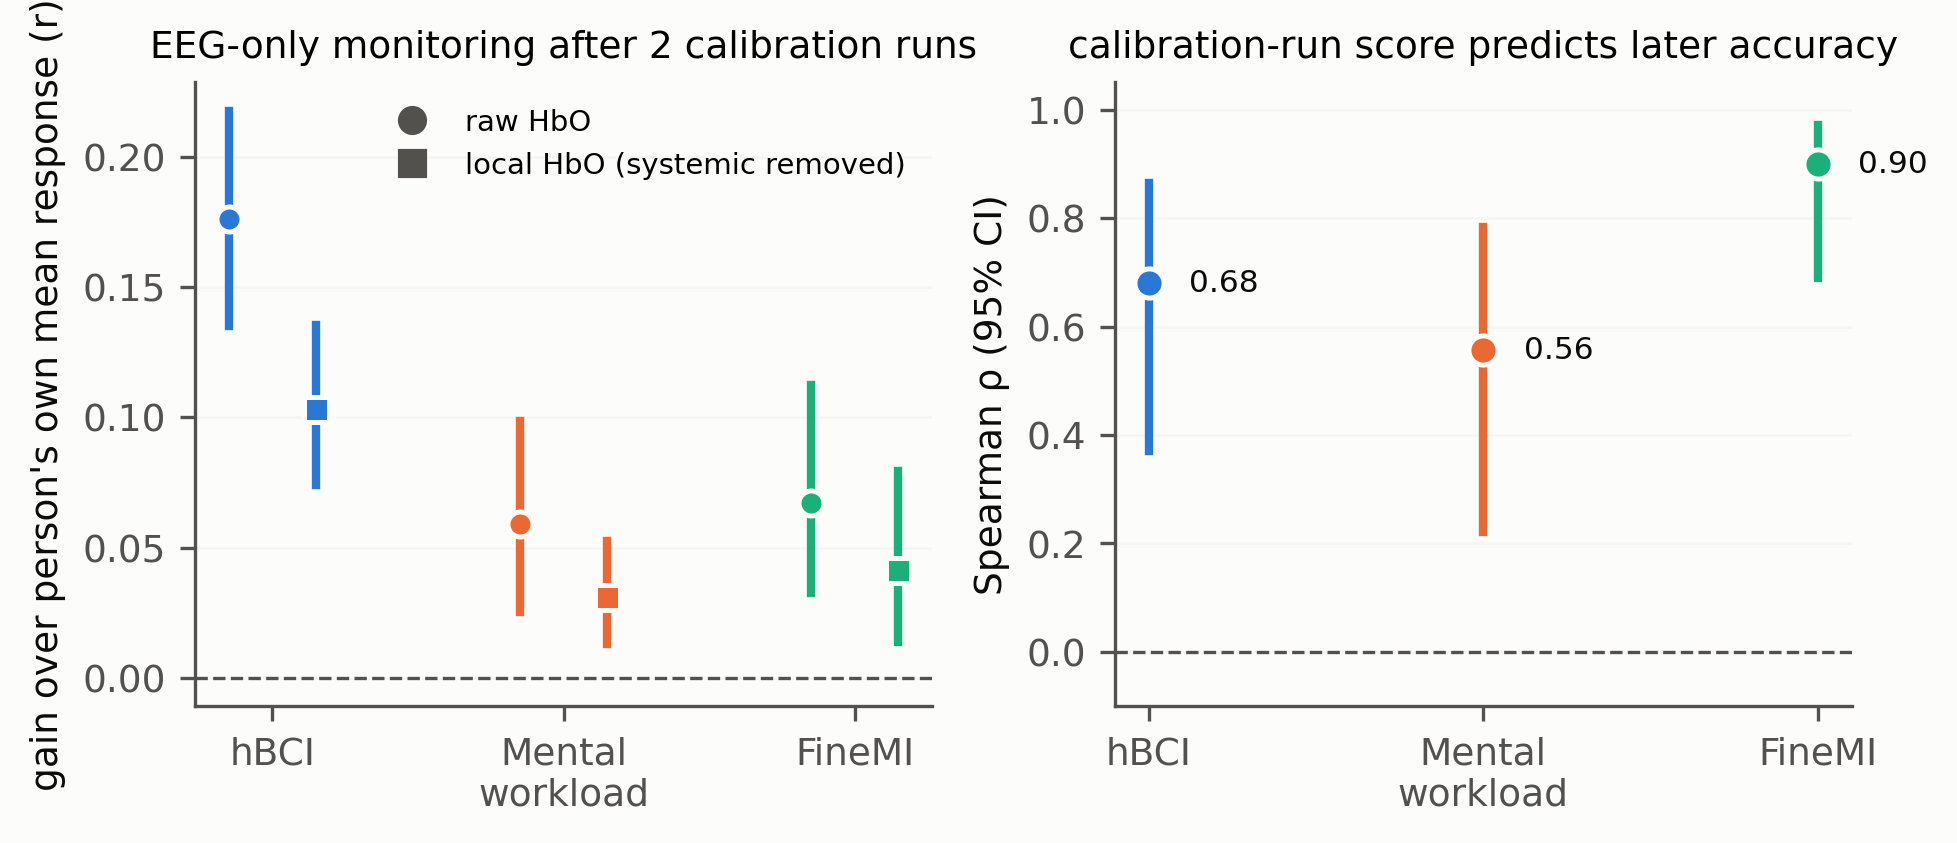

In [61]:
rel, loc = J("calib_reliability_results.json"), J("calib_reliability_local_results.json")
table([[COH[c], f"{rel[c]['spearman_score_vs_minus_error']:.2f}", ci(*rel[c]["ci95"]), f"{loc[c]['spearman_score_vs_minus_error']:.2f}", ci(*loc[c]["ci95"]), "pass" if rel[c]["passes"] else "fail"] for c in COH], ["Cohort", "Spearman ρ, raw", "95% CI", "ρ, local", "95% CI", "Rule"])
def draw_fig5():
    fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.9))
    G, GL = RJ("calibration_results.json"), RJ("calibration_results_local.json")
    gain = {c: tuple(x for d in (G, GL) for x in (d[c]["gains"]["k2_personal_minus_baseline"]["mean"], *d[c]["gains"]["k2_personal_minus_baseline"]["ci"])) for c in FIG_COH}
    ax = axes[0]
    for i, (c, (lab, col)) in enumerate(FIG_COH.items()):
        g = gain[c]
        for j, (m, lo, hi, mk) in enumerate(((g[0], g[1], g[2], "o"), (g[3], g[4], g[5], "s"))):
            xx = i + (j - 0.5) * 0.3
            ax.plot([xx, xx], [lo, hi], color=col, lw=2)
            ax.plot(xx, m, mk, ms=6, color=col, mec=SURF, mew=1.2)
    ax.plot([], [], "o", color=INK2, label="raw HbO")
    ax.plot([], [], "s", color=INK2, label="local HbO (systemic removed)")
    ax.axhline(0, color=INK2, lw=0.8, ls="--")
    ax.set_xticks(range(3), ["hBCI", "Mental\nworkload", "FineMI"])
    ax.set_ylabel("gain over person's own mean response (r)")
    ax.set_title("EEG-only monitoring after 2 calibration runs", fontsize=9)
    ax.legend(fontsize=7, loc="upper right")
    ax.grid(axis="x", visible=False)
    ax = axes[1]
    REL = RJ("calib_reliability_results.json")
    rel = {c: (REL[c]["spearman_score_vs_minus_error"], *REL[c]["ci95"]) for c in FIG_COH}
    for i, (c, (lab, col)) in enumerate(FIG_COH.items()):
        m, lo, hi = rel[c]
        ax.plot([i, i], [lo, hi], color=col, lw=2)
        ax.plot(i, m, "o", ms=7, color=col, mec=SURF, mew=1.2)
        ax.text(i + 0.12, m, f"{m:.2f}", va="center", fontsize=7.5, color=INK)
    ax.axhline(0, color=INK2, lw=0.8, ls="--")
    ax.set_xticks(range(3), ["hBCI", "Mental\nworkload", "FineMI"])
    ax.set_ylabel("Spearman ρ (95% CI)")
    ax.set_title("calibration-run score predicts later accuracy", fontsize=9)
    ax.set_ylim(-0.1, 1.05)
    ax.grid(axis="x", visible=False)
    save(fig, "fig5_deployment_reliability")


draw_fig5()
fig("fig5_deployment_reliability", 640)

Claim 5, per trial. Can single unreliable trials be identified in advance? Output: `trial_reliability_results.json`. Rerun name: `trial_reliability`.

In [62]:
def trial_reliability(LIB=False, MODE="all", SHARD=(0, 1), ARGS=()):
    import os

    import json
    import sys
    from pathlib import Path

    import numpy as np
    from scipy.stats import spearmanr
    from sklearn.linear_model import RidgeCV

    HERE = NB_OUT
    ns = calibration(LIB=True)
    COHORTS, ALPHAS, SEED = ns["COHORTS"], ns["ALPHAS"], 1337
    trial_corr, slow_features, zs, task_mean, _bins = (ns[k] for k in ("trial_corr", "slow_features", "zs", "task_mean", "_bins"))
    OUT = HERE / "trial_reliability_results.json"

    def run(cache):
        eeg = np.load(cache / "eeg.npy", mmap_mode="r")
        hemo = np.load(cache / "hemo.npy").astype(np.float64)
        sid, tid, rec = np.load(cache / "subject_ids.npy"), np.load(cache / "task_ids.npy"), np.load(cache / "rec_ids.npy")
        F = slow_features(eeg)
        Y = _bins(hemo, 30).reshape(len(hemo), -1)
        Fz, R = np.zeros_like(F), np.zeros_like(Y)
        for s in np.unique(sid):
            m = sid == s
            Fz[m] = zs(F[m], F[m])
            for t in np.unique(tid[m]):
                mt = m & (tid == t)
                R[mt] = Y[mt] - Y[mt].mean(0)
        rng = np.random.default_rng(SEED)
        per = {}
        for s in np.unique(sid):
            m = np.flatnonzero(sid == s)
            runs = np.unique(rec[m])
            if len(runs) < 3:
                continue
            others = np.flatnonzero(sid != s)
            pop = RidgeCV(alphas=ALPHAS).fit(Fz[others], R[others])
            cal = list(rng.choice(runs, 2, replace=False))
            ca = m[np.isin(rec[m], cal)]
            te = m[~np.isin(rec[m], cal)]
            base = np.stack([task_mean(Y[ca], tid[ca], t) for t in tid[te]])
            Rca = Y[ca] - np.stack([task_mean(Y[ca], tid[ca], t) for t in tid[ca]])
            Fca, Fte = zs(F[ca], F[ca]), zs(F[te], F[ca])
            dev = 0.5 * (RidgeCV(alphas=ALPHAS).fit(Fca, Rca).predict(Fte) + pop.predict(Fte))
            err = 1 - trial_corr(base + dev, Y[te])
            ood = -(Fte ** 2).mean(1)
            energy = np.linalg.norm(dev, axis=1)
            per[int(s)] = {"ood": float(spearmanr(ood, -err)[0]), "energy": float(spearmanr(energy, -err)[0]),
                           "n_trials": int(len(te))}
            print(f"  s{int(s)}: -OOD {per[int(s)]['ood']:+.3f} energy {per[int(s)]['energy']:+.3f}", flush=True)
        out = {"people": per}
        for k in ("ood", "energy"):
            v = np.array([p[k] for p in per.values()])
            b = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(5000)]
            out[k] = {"mean": float(v.mean()), "ci": [float(x) for x in np.percentile(b, [2.5, 97.5])]}
        out["passes"] = bool(out["ood"]["mean"] > 0.2 and out["ood"]["ci"][0] > 0)
        return out

    res = {}
    for name, cache in COHORTS.items():
        print(name, flush=True)
        res[name] = run(cache)
        r = res[name]
        print(f"== {name}: -OOD {r['ood']['mean']:+.3f} {r['ood']['ci']} | energy {r['energy']['mean']:+.3f} {r['energy']['ci']} "
              f"-> {'PASS' if r['passes'] else 'FAIL'}", flush=True)
        OUT.write_text(json.dumps(res, indent=1))
    res["claim5_trial_form_holds"] = bool(res["hbci"]["passes"] and (res["mental_workload"]["passes"] or res["finemi"]["passes"]))
    print("Claim 5 trial-level calibrated form:", "HOLDS" if res["claim5_trial_form_holds"] else "DOES NOT HOLD")
    OUT.write_text(json.dumps(res, indent=1))
    print("DONE")


# RERUN: set RUN = {"trial_reliability"} in section 2
if should("trial_reliability"):
    trial_reliability()

**Result.** The declared rule requires hBCI, which fails, so the claim fails at trial level. Mental workload passes on its own.

In [63]:
d = J("trial_reliability_results.json")
table([[COH[c], f"{d[c]['ood']['mean']:+.3f}", ci(*d[c]["ood"]["ci"]), f"{d[c]['energy']['mean']:+.3f}", ci(*d[c]["energy"]["ci"]), "pass" if d[c]["passes"] else "fail"] for c in COH], ["Cohort", "Out-of-distribution score", "95% CI", "Predicted-signal energy", "95% CI", "Rule"])

Cohort,Out-of-distribution score,95% CI,Predicted-signal energy,95% CI,Rule
hBCI,-0.007,"[-0.063, +0.048]",+0.216,"[+0.152, +0.278]",fail
Mental workload,+0.234,"[+0.086, +0.369]",+0.060,"[-0.087, +0.213]",pass
FineMI,+0.042,"[-0.018, +0.101]",+0.164,"[+0.093, +0.236]",fail


## 15. Summary of all claims

The best result for each of the five claims and its verdict.

In [64]:
c1m, c1f = J("claim1_fresh_mental_workload_results.json"), J("claim1_fresh_finemi_results.json")
ext = J("external_claim2_results.json")["hbci_to_mental_workload"]
t2, bp, sm = J("nvc_transfer2_results.json"), J("nvc_bandpower_results.json"), J("nvc_delay_smooth_results.json")
rep = J("downstream_repr_nlab0_results.json")["hbci_MI_left_right (primary)"]["mean_acc"]
rel = J("calib_reliability_results.json")
cal = t2["calibrated | finemi"]
table([
 ["1. Shared fNIRS + fMRI space", f"fNIRS MW {c1m['fnirs']['joint']['r_subject']:.3f}, FineMI {c1f['fnirs']['joint']['r_subject']:.3f}; fMRI {c1m['fmri']['joint']['r_subject']:.3f}", "<b>Holds</b> (shared-space form). fMRI supervision does not improve fNIRS."],
 ["2. External validation", f"Same lab {ext['r_subject']:+.3f} {ci(ext['ci_low'], ext['ci_high'])}; other lab, calibrated {cal['diff']:+.3f} {ci(*cal['ci'])}", "<b>Holds within lab.</b> Cross-lab: frozen fails, calibrated nominal only."],
 ["3. Delay / coupling", f"hBCI {bp['hbci']['frac_beating_null']:.0%} beat null, delay {bp['hbci']['median_delay_s']:+.0f} s (EEG first); delay repeats {sm['hbci | raw']['agree_2s']:.0%} vs {sm['hbci | raw']['chance']:.0%} chance", "<b>Holds in hBCI.</b> Kernel shape repeats in other cohorts; precise delay there is inconclusive."],
 ["4. Downstream EEG-only task", f"Virtual haemodynamics {rep['V']:.3f} vs PCA {rep['PC']:.3f}", "<b>Refuted.</b>"],
 ["5. Calibrated reliability", "Spearman " + ", ".join(f"{COH[c]} {rel[c]['spearman_score_vs_minus_error']:.2f}" for c in COH), "<b>Holds per person</b>; fails per trial."],
], ["Claim", "Best result", "Verdict"])

Claim,Best result,Verdict
1. Shared fNIRS + fMRI space,"fNIRS MW 0.123, FineMI 0.180; fMRI 0.068",Holds (shared-space form). fMRI supervision does not improve fNIRS.
2. External validation,"Same lab +0.205 [+0.128, +0.285]; other lab, calibrated +0.020 [+0.004, +0.039]","Holds within lab. Cross-lab: frozen fails, calibrated nominal only."
3. Delay / coupling,"hBCI 100% beat null, delay +6 s (EEG first); delay repeats 66% vs 29% chance",Holds in hBCI. Kernel shape repeats in other cohorts; precise delay there is inconclusive.
4. Downstream EEG-only task,Virtual haemodynamics 0.697 vs PCA 0.760,Refuted.
5. Calibrated reliability,"Spearman hBCI 0.68, Mental workload 0.56, FineMI 0.90",Holds per person; fails per trial.


Which positive results survive Bonferroni correction across all attempts at the same claim, also when cohorts are counted as separate tests. Details: `TEST_LEDGER.md`.

In [65]:
kr, kt = J("nvc_kernel_results.json"), J("nvc_kernel_resid_results.json")
from_attempts = {"Claim 1": 8, "Claim 2 same lab": 3, "Claim 2 other lab": 16, "Claim 3": 13, "Claim 5": 4}
p83 = signflip([v["personal_plus_external"] - v["personal"] for v in cal["people"].values()])
items = [("Claim 1", "Shared space predicts fMRI", c1m["fmri"]["joint"]["p_signflip"]),
         ("Claim 2 same lab", "hBCI → MW, slow EEG", ext["p_signflip"]),
         ("Claim 2 other lab", "hBCI → FineMI, calibrated (P8.3)", p83),
         ("Claim 3", "hBCI kernel repeats", kr["hbci"]["wilcoxon_p_greater"]),
         ("Claim 3", "hBCI delay repeats", sm["hbci | raw"]["p_agree"]),
         ("Claim 3", "FineMI kernel, task removed", kt["finemi"]["wilcoxon_p_greater"]),
         ("Claim 3", "MW kernel, task removed", kt["mental_workload"]["wilcoxon_p_greater"]),
         ("Claim 3", "FineMI kernel, raw", kr["finemi"]["wilcoxon_p_greater"])]
items += [("Claim 5", f"Reliability, {COH[c]}", spearman_p(rel[c]["spearman_score_vs_minus_error"], rel[c]["n"])) for c in COH]
rows = []
for fam, name, p in items:
    n = from_attempts[fam]
    a, b = 0.05 / n, 0.05 / (n * 3)
    rows.append([fam, name, f"{p:.1e}", n, f"{a:.4f}", "yes" if p < a else "<b>no</b>", "yes" if p < b else "<b>no</b>"])
table(rows, ["Family", "Result", "p", "Attempts", "α", "Survives", "Survives if cohorts counted too (×3)"])

Family,Result,p,Attempts,α,Survives,Survives if cohorts counted too (×3)
Claim 1,Shared space predicts fMRI,1.0e-04,8,0.0063,yes,yes
Claim 2 same lab,"hBCI → MW, slow EEG",2.0e-04,3,0.0167,yes,yes
Claim 2 other lab,"hBCI → FineMI, calibrated (P8.3)",1.7e-02,16,0.0031,no,no
Claim 3,hBCI kernel repeats,5.6e-09,13,0.0038,yes,yes
Claim 3,hBCI delay repeats,3.0e-04,13,0.0038,yes,yes
Claim 3,"FineMI kernel, task removed",9.7e-04,13,0.0038,yes,yes
Claim 3,"MW kernel, task removed",6.0e-03,13,0.0038,no,no
Claim 3,"FineMI kernel, raw",3.3e-02,13,0.0038,no,no
Claim 5,"Reliability, hBCI",5.0e-05,4,0.0125,yes,yes
Claim 5,"Reliability, Mental workload",3.1e-03,4,0.0125,yes,yes
